In [1]:
# First, let's check which Python interpreter is being used by this notebook
import sys
print(f"Current Python executable: {sys.executable}")

# Let's see all available environments
!conda env list

# Let's check if we're in a conda environment and which one
import os
print(f"CONDA_DEFAULT_ENV: {os.environ.get('CONDA_DEFAULT_ENV', 'Not set')}")

# Let's try to install ortools directly in the current environment
!{sys.executable} -m pip install ortools

# After installation, try importing again
try:
    from ortools.constraint_solver import routing_enums_pb2
    from ortools.constraint_solver import pywrapcp
    print("Successfully imported ortools modules")
except ImportError as e:
    print(f"Import error: {e}")
!{sys.executable} -m pip install polars

Current Python executable: C:\Users\Administrator\.conda\envs\ml_env\python.exe

# conda environments:
#
base                   C:\ProgramData\anaconda3
ml_env               * C:\Users\Administrator\.conda\envs\ml_env
ml_env — копия         C:\Users\Administrator\.conda\envs\ml_env — копия

CONDA_DEFAULT_ENV: ml_env
Successfully imported ortools modules



[notice] A new release of pip is available: 26.1.1 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 26.1.1 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os
from joblib import Parallel, delayed
import sqlite3
import polars as pl
from collections import defaultdict
import numpy as np
from ortools.constraint_solver import routing_enums_pb2
from ortools.constraint_solver import pywrapcp
import time
from tqdm import tqdm
import networkx as nx
import copy
import random
import pickle
from shapely.geometry import Polygon, Point
from shapely.ops import transform
from pyproj import Transformer
from typing import Dict, List, Tuple
import warnings
import json
import re

rng = np.random.default_rng (seed = 42)

MPID_df = pl.read_json('ml_ozon_logistic_dataSetOrders.json')

MPIDs_dict = defaultdict(list)
orders_dict = defaultdict(list)
orders_geo = defaultdict(list)

for item in MPID_df['Orders'].to_list():
    for order in item:
        if order['ID'] != 0:
            orders_geo[order['ID']] = {
                'lat': order['Lat'],
                'lon': order['Long']
            }
            MPIDs_dict[order['MpId']].append(order['ID'])
            orders_dict[order['ID']] = order['MpId']
        
MPIDs_list = list(MPIDs_dict.keys())

print(f"Загружено {len(orders_geo)} заказов, {len(MPIDs_list)} MPID")

def load_couriers_data(file_path):
    """Загружает данные о курьерах с координатами из Warehouse"""
    with open(file_path, 'r') as f:
        data = json.load(f)
    
    warehouse_geo = {
        'lat': data['Warehouse']['Lat'],
        'lon': data['Warehouse']['Long']
    }
    
    couriers = []
    for courier_group in data['Couriers']:
        courier_id = courier_group['ID']
        service_times = {}
        for service_time in courier_group['ServiceTimeInMps']:
            service_times[service_time['MpID']] = service_time['ServiceTime']
        
        couriers.append({
            'id': courier_id,
            'service_times': service_times
        })
    
    return warehouse_geo, couriers

warehouse_geo, couriers_data = load_couriers_data('ml_ozon_logistic_dataSetCouriers.json')
all_couriers_IDs = [c['id'] for c in couriers_data]

print(f"Загружено {len(couriers_data)} курьеров, склад: ({warehouse_geo['lat']}, {warehouse_geo['lon']})")

Загружено 20159 заказов, 1393 MPID
Загружено 280 курьеров, склад: (55.855153, 36.801776)


In [3]:
def create_sorted_distance_array():
    """Создает отсортированный массив расстояний с возможностью быстрого поиска"""
    conn = sqlite3.connect('distances.db')
    cursor = conn.cursor()

    # Получаем общее количество строк
    cursor.execute('SELECT COUNT(*) FROM distances')
    total_rows = cursor.fetchone()[0]

    # Создаем memory-mapped файл
    mmap_array = np.memmap('distances.dat', dtype=np.int32, mode='w+', shape=(total_rows, 3))

    # Загружаем данные из базы
    cursor.execute("SELECT from_location, to_location, distance FROM distances ORDER BY from_location, to_location")

    batch_size = 100000
    index = 0

    progress_bar = tqdm(total=total_rows, desc="Создание отсортированного массива", unit="row")

    while True:
        rows = cursor.fetchmany(batch_size)
        if not rows:
            break

        batch_array = np.array(rows, dtype=np.int32)
        mmap_array[index:index+len(batch_array)] = batch_array
        index += len(batch_array)

        progress_bar.update(len(rows))

    progress_bar.close()
    conn.close()

    return mmap_array

def create_search_index(distance_array):
    """Создает индекс для быстрого поиска по from_location"""
    # Находим уникальные from_location и их начальные позиции
    unique_from, start_indices = np.unique(distance_array[:, 0], return_index=True)

    # Создаем словарь для быстрого поиска диапазонов
    index_dict = {}
    for i in range(len(unique_from)):
        start = start_indices[i]
        end = start_indices[i+1] if i+1 < len(start_indices) else len(distance_array)
        index_dict[unique_from[i]] = (start, end)

    return index_dict

print("создание numpy сета расстояний из базы данных...")
start_time = time.time()

with open('distances.dat', 'rb') as f:
    data_bytes = f.read()
    
distance_array = np.frombuffer(data_bytes, dtype=np.int32).reshape(-1, 3)

# distance_array = create_sorted_distance_array()

idx_dict = create_search_index(distance_array)
cache_time = time.time() - start_time
print(f"Кэш создан за {cache_time:.2f} секунд, всего {len(distance_array)} записей")

создание numpy сета расстояний из базы данных...
Кэш создан за 6.15 секунд, всего 406405440 записей


In [4]:
def get_distance(distance_array, idx_dict, from_point, to_point, default=10**9):
    """Быстрое получение расстояния между двумя точками"""
    if from_point not in idx_dict:
        return default

    start, end = idx_dict[from_point]

    # Бинарный поиск в отсортированном диапазоне
    subset = distance_array[start:end]
    to_points = subset[:, 1]

    # Используем бинарный поиск NumPy
    pos = np.searchsorted(to_points, to_point)

    if pos < len(to_points) and to_points[pos] == to_point:
        return subset[pos, 2]
    else:
        return default

def create_distance_matrix(points, distance_array, idx_dict, poly_mapping=None, punishment=8000):
    """Создает матрицу расстояний для точек полигона с учетом штрафов между разными полигонами"""
    n = len(points)
    matrix = np.zeros((n, n))

    for i in range(n):
        for j in range(n):
            if i == j:
                matrix[i][j] = 0
            else:
                distance = get_distance(distance_array, idx_dict, points[i], points[j])
                
                if poly_mapping is not None:
                    poly_i = poly_mapping[points[i]]
                    poly_j = poly_mapping[points[j]]
                    
                    if poly_i != poly_j:
                        matrix[i][j] = distance + punishment
                    else:
                        matrix[i][j] = distance
                else:
                    matrix[i][j] = distance

    return matrix.astype(int).tolist()

In [5]:
import pickle
from collections import defaultdict

with open('optimized_solution_fast.pkl', 'rb') as file:
    final_solution = pickle.load(file)

with open('each_polygon_opt_route.pkl', 'rb') as file:
    final_each_polygon_opt_route = pickle.load(file)

new_couriers_dict = defaultdict()
for i in range(len(couriers_data)):
    new_couriers_dict[couriers_data[i]['id']] = couriers_data[i]['service_times']

brokens_list = []

In [57]:
import math
import copy
from typing import Optional, List, Tuple

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader


# ============================================================
# 1. Mixed-Score Multi-Head Attention  (THE core of MatNet)
#    Fuses the scaled dot-product score with the raw matrix
#    entry (distance) through a tiny MLP "mixer".
# ============================================================
class MixedScoreMHA(nn.Module):
    def __init__(self, embed_dim: int, n_heads: int, ms_hidden: int = 16):
        super().__init__()
        assert embed_dim % n_heads == 0
        self.n_heads, self.head_dim = n_heads, embed_dim // n_heads
        self.Wq = nn.Linear(embed_dim, embed_dim, bias=False)
        self.Wk = nn.Linear(embed_dim, embed_dim, bias=False)
        self.Wv = nn.Linear(embed_dim, embed_dim, bias=False)
        self.out = nn.Linear(embed_dim, embed_dim, bias=False)
        # mixer: [dot_score, matrix_entry] -> fused score  (per head)
        self.mixer = nn.Sequential(nn.Linear(2, ms_hidden), nn.ReLU(),
                                   nn.Linear(ms_hidden, 1))

    def forward(self, q_in, kv_in, matrix, key_mask=None):
        # q_in:(B,Nq,E)  kv_in:(B,Nk,E)  matrix:(B,Nq,Nk)  key_mask:(B,Nk) True=valid
        B, Nq, _ = q_in.shape
        Nk = kv_in.size(1)
        H, hd = self.n_heads, self.head_dim
        q = self.Wq(q_in).view(B, Nq, H, hd).transpose(1, 2)
        k = self.Wk(kv_in).view(B, Nk, H, hd).transpose(1, 2)
        v = self.Wv(kv_in).view(B, Nk, H, hd).transpose(1, 2)
        dot = torch.matmul(q, k.transpose(-2, -1)) / math.sqrt(hd)   # (B,H,Nq,Nk)
        mat = matrix.unsqueeze(1).expand(-1, H, -1, -1)              # (B,H,Nq,Nk)
        scores = self.mixer(torch.stack([dot, mat], dim=-1)).squeeze(-1)
        if key_mask is not None:
            scores = scores.masked_fill(~key_mask[:, None, None, :], -1e9)
        attn = F.softmax(scores, dim=-1)
        out = torch.matmul(attn, v).transpose(1, 2).contiguous().view(B, Nq, -1)
        return self.out(out)


# ============================================================
# 2. Dual-attention encoder block (rows <-> columns)
# ============================================================
class MatNetLayer(nn.Module):
    def __init__(self, embed_dim, n_heads, ff_dim, ms_hidden):
        super().__init__()
        self.row_attn = MixedScoreMHA(embed_dim, n_heads, ms_hidden)
        self.col_attn = MixedScoreMHA(embed_dim, n_heads, ms_hidden)
        self.rn1, self.rn2 = nn.LayerNorm(embed_dim), nn.LayerNorm(embed_dim)
        self.cn1, self.cn2 = nn.LayerNorm(embed_dim), nn.LayerNorm(embed_dim)
        self.rff = nn.Sequential(nn.Linear(embed_dim, ff_dim), nn.ReLU(),
                                 nn.Linear(ff_dim, embed_dim))
        self.cff = nn.Sequential(nn.Linear(embed_dim, ff_dim), nn.ReLU(),
                                 nn.Linear(ff_dim, embed_dim))

    def forward(self, row, col, matrix, mask):
        # rows attend to columns through D ; columns attend to rows through D^T
        row = self.rn1(row + self.row_attn(row, col, matrix, mask))
        row = self.rn2(row + self.rff(row))
        col = self.cn1(col + self.col_attn(col, row, matrix.transpose(1, 2), mask))
        col = self.cn2(col + self.cff(col))
        return row, col


# ============================================================
# 3. Autoregressive decoder (Attention-Model style:
#    multi-head glimpse + single-head clipped logits)
# ============================================================
class MatNetDecoder(nn.Module):
    def __init__(self, embed_dim, n_heads, clip=10.0):
        super().__init__()
        self.n_heads, self.head_dim, self.clip = n_heads, embed_dim // n_heads, clip
        self.Wq   = nn.Linear(embed_dim, embed_dim, bias=False)
        self.Wk   = nn.Linear(embed_dim, embed_dim, bias=False)
        self.Wv   = nn.Linear(embed_dim, embed_dim, bias=False)
        self.Wout = nn.Linear(embed_dim, embed_dim, bias=False)
        self.WkL  = nn.Linear(embed_dim, embed_dim, bias=False)

    def set_kv(self, node_emb):                       # cache K,V once per instance
        B, N, E = node_emb.shape
        H, hd = self.n_heads, self.head_dim
        self.gk = self.Wk(node_emb).view(B, N, H, hd).transpose(1, 2)
        self.gv = self.Wv(node_emb).view(B, N, H, hd).transpose(1, 2)
        self.lk = self.WkL(node_emb)
        self.scale = math.sqrt(E)

    def forward(self, query, visited):                # query:(B,E) visited:(B,N) bool
        B, E = query.shape
        H, hd = self.n_heads, self.head_dim
        q = self.Wq(query).view(B, H, 1, hd)
        s = torch.matmul(q, self.gk.transpose(-2, -1)) / math.sqrt(hd)
        s = s.masked_fill(visited[:, None, None, :], -1e9)
        glimpse = torch.matmul(F.softmax(s, dim=-1), self.gv)         # (B,H,1,hd)
        glimpse = self.Wout(glimpse.transpose(1, 2).reshape(B, 1, E)).squeeze(1)
        logits = torch.matmul(glimpse.unsqueeze(1),
                              self.lk.transpose(1, 2)).squeeze(1) / self.scale
        logits = self.clip * torch.tanh(logits)
        return logits.masked_fill(visited, -1e9)


# ============================================================
# 4. The full MatNet model
# ============================================================
class MatNet(nn.Module):
    def __init__(self, embed_dim=128, n_layers=5, n_heads=8,
                 ff_dim=512, ms_hidden=16, clip=10.0):
        super().__init__()
        self.embed_dim = embed_dim
        self.layers = nn.ModuleList(
            [MatNetLayer(embed_dim, n_heads, ff_dim, ms_hidden) for _ in range(n_layers)])
        self.decoder = MatNetDecoder(embed_dim, n_heads, clip)

    # MatNet initial embeddings: rows = zeros, columns = random one-hot ("instance
    # augmentation" replacement of node features for a featureless matrix).
    def _init_emb(self, B, N, device):
        row = torch.zeros(B, N, self.embed_dim, device=device)
        col = torch.zeros(B, N, self.embed_dim, device=device)
        idx = torch.rand(B, self.embed_dim, device=device).argsort(1)[:, :N]
        col.scatter_(2, idx.unsqueeze(-1), 1.0)
        return row, col

    def encode(self, dist, mask):
        B, N, _ = dist.shape
        INF_THRESHOLD = 1e4
        # 1. Mask out the padded nodes BEFORE finding the maximum
        # mask shape is (B, N), we need it to be (B, 1, 1) or broadcastable to (B, N, N)
        valid_edge_mask = (dist < INF_THRESHOLD) & mask.unsqueeze(1) & mask.unsqueeze(2) 
        masked_dist = dist.masked_fill(~valid_edge_mask, 0.0)
        
        # 2. Calculate max ONLY on real nodes
        max_val = masked_dist.amax(dim=(1, 2), keepdim=True) + 1e-8
        
        # 3. Normalize
        mnorm = dist / max_val 
        
        row, col = self._init_emb(B, N, dist.device)
        for layer in self.layers:
            row, col = layer(row, col, mnorm, mask)
        return row, col

    def decode(self, dist, mask, n_nodes, start_idx=None,
               decode_type='greedy', temperature=1.0):
        """Returns (tours:(B,N_max), sum_log_prob:(B,)). OPEN tour: no return edge."""
        B, N, _ = dist.shape
        device = dist.device
        if start_idx is None:
            start_idx = torch.zeros(B, dtype=torch.long, device=device)
        row, _ = self.encode(dist, mask)
        self.decoder.set_kv(row)

        # NOTE: every update below is OUT-OF-PLACE so that the `visited`/`logits`
        # tensors saved by masked_fill for backward are never mutated afterwards.
        visited = (~mask).clone()                              # (B,N) bool
        visited = visited.scatter(1, start_idx[:, None], True) # out-of-place
        ar = torch.arange(B, device=device)
        cur = start_idx
        tours, logps = [start_idx], []

        for _ in range(N - 1):
            logits = self.decoder(row[ar, cur], visited)       # (B,N), grad-tracked
            done = (logits <= -1e8).all(-1)                    # finished instances
            if done.any():
                # out-of-place self-loop fix (logp = 0 for finished rows)
                self_mask = torch.zeros_like(visited)
                self_mask[ar[done], cur[done]] = True          # fresh bool tensor, no grad
                logits = torch.where(self_mask,
                                     torch.zeros_like(logits), logits)

            probs = F.softmax(logits / temperature, -1)
            if decode_type == 'greedy':
                nxt = probs.argmax(-1)
            else:
                nxt = torch.distributions.Categorical(probs).sample()

            logps.append(torch.log(probs.gather(1, nxt[:, None]).squeeze(1) + 1e-12))
            tours.append(nxt)
            visited = visited.scatter(1, nxt[:, None], True)   # out-of-place -> NEW tensor
            cur = nxt

        return torch.stack(tours, 1), torch.stack(logps, 1).sum(1)


# ============================================================
# 5. OPEN-ATSP tour cost  (path, NOT a cycle -> no last->first edge)
# ============================================================
def tour_cost(tours: torch.Tensor, dist: torch.Tensor, n_nodes: List[int]) -> torch.Tensor:
    B = tours.size(0)
    costs = dist.new_zeros(B)
    for b in range(B):
        n = n_nodes[b]
        seq = tours[b, :n]
        costs[b] = dist[b, seq[:-1], seq[1:]].sum()
    return costs


# ============================================================
# 6. Dataset + collate (pad ragged ATSP matrices to max_nodes)
# ============================================================
class ATSPDataset(Dataset):
    def __init__(self, polygon_ids, AUG_global_map, optimal_routes=None):
        self.ids = list(polygon_ids)
        self.maps = AUG_global_map
        self.opt = optimal_routes or {}

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, idx):
        pid = self.ids[idx]
        d = np.asarray(self.maps[pid]['distance matrix'], dtype=np.float32)
        return {'polygon_id': pid,
                'dist_matrix': torch.from_numpy(d),
                'n_nodes': d.shape[0]}


def make_collate(max_nodes=120):
    def collate(batch):
        B = len(batch)
        dist = torch.full((B, max_nodes, max_nodes), 1e4)
        mask = torch.zeros(B, max_nodes, dtype=torch.bool)
        n_nodes, ids = [], []
        for i, it in enumerate(batch):
            n = it['n_nodes']
            dist[i, :n, :n] = it['dist_matrix']
            mask[i, :n] = True
            n_nodes.append(n)
            ids.append(it['polygon_id'])
        return {'dist_matrices': dist, 'masks': mask,
                'n_nodes': n_nodes, 'polygon_ids': ids}
    return collate

device = 'cuda'
PATH_MATNET = r'C:\Users\Administrator\matnet_open_atsp.pth'

MATNET_MODEL = MatNet(embed_dim=128, n_layers=5, n_heads=8, ff_dim=512)

checkpoint = torch.load(PATH_MATNET, map_location=device, weights_only=True)
MATNET_MODEL.load_state_dict(checkpoint)

MATNET_MODEL.to(device)
MATNET_MODEL.eval()

print(f"✅ MatNet initialized and moved to {device}")

def run_matnet_inference(dist_matrix: np.ndarray, model: MatNet,
                         device='cuda', start_idx=0,
                         decode_type='greedy', n_samples=1
                         ) -> Tuple[np.ndarray, float]:
    model.eval()
    N = dist_matrix.shape[0]
    dist = torch.as_tensor(dist_matrix, dtype=torch.float32, device=device).unsqueeze(0)
    mask = torch.ones(1, N, dtype=torch.bool, device=device)
    start = torch.tensor([start_idx], dtype=torch.long, device=device)

    if decode_type == 'greedy':
        t, _ = model.decode(dist, mask, [N], start, 'greedy')
        tour = t.squeeze(0).cpu().numpy()
        cost = float(tour_cost(t, dist, [N]).item())
    else:  # sampling: keep best of n_samples
        best_tour, best_cost = None, float('inf')
        for _ in range(n_samples):
            t, _ = model.decode(dist.expand(1, N, N), mask, [N], start, 'sampling')
            c = float(tour_cost(t, dist, [N]).item())
            if c < best_cost:
                best_cost, best_tour = c, t.squeeze(0).cpu().numpy()
        tour, cost = best_tour, best_cost
    return tour, cost

✅ MatNet initialized and moved to cuda


In [7]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import copy
import random
import re
import math  # 👈 Added for safe sqrt
from typing import Tuple, List, Optional
from torch.utils.data import Dataset, DataLoader, Sampler
from collections import defaultdict

# ==========================================
# ENCODER (Fixed NumPy sqrt leak)
# ==========================================
class NLNS_EncoderLayer(nn.Module):
    def __init__(self, embed_dim: int = 128, n_heads: int = 8):
        super().__init__()
        self.n_heads = n_heads
        self.head_dim = embed_dim // n_heads
        self.Wq = nn.Linear(embed_dim, embed_dim, bias=False)
        self.Wk = nn.Linear(embed_dim, embed_dim, bias=False)
        self.Wv = nn.Linear(embed_dim, embed_dim, bias=False)
        self.Wout = nn.Linear(embed_dim, embed_dim, bias=False)
        self.norm1 = nn.LayerNorm(embed_dim)
        self.norm2 = nn.LayerNorm(embed_dim)
        self.ff = nn.Sequential(
            nn.Linear(embed_dim, embed_dim * 4), nn.ReLU(),
            nn.Linear(embed_dim * 4, embed_dim)
        )

    def forward(self, x, dist_matrix=None, mask=None):
        B, N, _ = x.shape
        residual = x
        Q = self.Wq(x).view(B, N, self.n_heads, self.head_dim).transpose(1, 2)
        K = self.Wk(x).view(B, N, self.n_heads, self.head_dim).transpose(1, 2)
        V = self.Wv(x).view(B, N, self.n_heads, self.head_dim).transpose(1, 2)
        
        # 👈 FIX: Use math.sqrt instead of np.sqrt to prevent CPU scalar leakage
        scores = torch.matmul(Q, K.transpose(-2, -1)) / math.sqrt(self.head_dim)
        attn = F.softmax(scores, dim=-1)
        out = torch.matmul(attn, V).transpose(1, 2).contiguous().view(B, N, -1)
        out = self.Wout(out)
        
        x = self.norm1(residual + out)
        x = self.norm2(x + self.ff(x))
        return x

class NLNS_Encoder(nn.Module):
    def __init__(self, embed_dim=128, n_layers=3, n_heads=8):
        super().__init__()
        self.feat_proj = nn.Linear(2, embed_dim)
        self.layers = nn.ModuleList([NLNS_EncoderLayer(embed_dim, n_heads) for _ in range(n_layers)])
        
    def forward(self, dist_matrix):
        B, N, _ = dist_matrix.shape
        row_mean = dist_matrix.mean(dim=-1, keepdim=True)
        row_std = dist_matrix.std(dim=-1, keepdim=True)
        feats = torch.cat([row_mean, row_std], dim=-1)
        
        x = self.feat_proj(feats)
        for layer in self.layers:
            x = layer(x)
        return x

# ==========================================
# DECODER (Ensured strict device inheritance)
# ==========================================
class NLNS_RepairDecoder(nn.Module):
    def __init__(self, embed_dim=128):
        super().__init__()
        E = embed_dim
        self.edge_proj = nn.Linear(2 * E, E, bias=False)
        self.q_proj = nn.Linear(E, E, bias=False)
        self.k_proj = nn.Linear(E, E, bias=False)
        self.cost_proj = nn.Linear(1, E, bias=False)
        self.scale = E ** 0.5

    def forward(self, v_idx, v_emb, partial_tour_embs, partial_tour_indices, dist_matrix):
        B, L, E = partial_tour_embs.shape
        device = dist_matrix.device # 👈 Strictly inherit device from input
        
        next_indices = torch.roll(partial_tour_indices, shifts=-1, dims=1)
        head_e = partial_tour_embs
        tail_e = torch.roll(partial_tour_embs, shifts=-1, dims=1)
        
        edge_e = self.edge_proj(torch.cat([head_e, tail_e], dim=-1)) # (B, L, E)
        q = self.q_proj(v_emb) # (B, 1, E)
        k = self.k_proj(edge_e) # (B, L, E)
        
        attn_scores = torch.matmul(q, k.transpose(1, 2)).squeeze(1) / self.scale # (B, L)
        
        # 👈 FIX: Ensure all indexing tensors are explicitly on the correct device
        bidx = torch.arange(B, device=device).view(B, 1)
        v_idx_exp = v_idx.view(B, 1).expand(B, L)
        
        cost_pv = dist_matrix[bidx, partial_tour_indices, v_idx_exp]
        cost_vp = dist_matrix[bidx, v_idx_exp, next_indices]
        cost_pp = dist_matrix[bidx, partial_tour_indices, next_indices]
        
        cost_change = cost_pv + cost_vp - cost_pp # (B, L)
        cost_emb = self.cost_proj(cost_change.unsqueeze(-1)) # (B, L, E)
        cost_score = (q * cost_emb).sum(-1) / self.scale # (B, L)
        
        scores = attn_scores - cost_score
        return scores

# ==========================================================
# FULL NLNS MODEL (destroy + neural repair)
# ==========================================================
class NLNS_Model(nn.Module):
    def __init__(self, embed_dim=128, n_layers=3, n_heads=8):
        super().__init__()
        self.encoder = NLNS_Encoder(embed_dim, n_layers, n_heads)
        self.decoder = NLNS_RepairDecoder(embed_dim)
        self.embed_dim = embed_dim

    @staticmethod
    def destroy(tours, destroy_fraction=0.2, start_idx=0):
        B, N = tours.shape
        k = max(1, int(N * destroy_fraction))
        
        removed_nodes_batch = []
        partial_tours_batch = []
        
        for b in range(B):
            tour_b = tours[b].tolist()
            candidates = [node for node in tour_b if node != start_idx]
            removed = random.sample(candidates, min(k, len(candidates)))
            removed_nodes_batch.append(removed)
            
            partial = [node for node in tour_b if node not in removed]
            partial_tours_batch.append(partial)
            
        return removed_nodes_batch, partial_tours_batch

    def repair(self, dist_matrix, tours, destroy_fraction=0.2, start_idx=0, greedy=False, temperature=1.0):
        B, N = tours.shape
        device = dist_matrix.device
        
        node_embs = self.encoder(dist_matrix)
        removed_nodes_batch, partial_tours_batch = self.destroy(tours, destroy_fraction, start_idx)
        
        batch_logp = []
        batch_ent = []
        final_tours = []
        costs = []
        
        for b in range(B):
            partial_tour = partial_tours_batch[b]
            removed_nodes = removed_nodes_batch[b]
            random.shuffle(removed_nodes)
            
            traj_logps = []
            traj_ents = []
            
            for v in removed_nodes:
                v_idx = torch.tensor([v], dtype=torch.long, device=device)
                v_emb = node_embs[b, v].unsqueeze(0).unsqueeze(0) # (1, 1, E)
                
                partial_tour_indices = torch.tensor(partial_tour, dtype=torch.long, device=device).unsqueeze(0) # (1, L)
                partial_tour_embs = node_embs[b, partial_tour_indices.squeeze(0)].unsqueeze(0) # (1, L, E)
                
                dist_b = dist_matrix[b].unsqueeze(0) # (1, N, N)
                
                scores = self.decoder(v_idx, v_emb, partial_tour_embs, partial_tour_indices, dist_b).squeeze(0) # (L,)
                
                if greedy:
                    pos_idx = torch.argmax(scores).item()
                    log_prob = torch.tensor(0.0, device=device)
                    ent = torch.tensor(0.0, device=device)
                else:
                    probs = F.softmax(scores / temperature, dim=-1)
                    probs = torch.clamp(probs, min=1e-8, max=1.0)
                    dist = torch.distributions.Categorical(probs)
                    
                    pos_idx_tensor = dist.sample()
                    pos_idx = pos_idx_tensor.item()
                    log_prob = dist.log_prob(pos_idx_tensor)
                    ent = dist.entropy()
                    
                traj_logps.append(log_prob)
                traj_ents.append(ent)
                
                partial_tour.insert(pos_idx + 1, v)
                
            final_tours.append(partial_tour)
            batch_logp.append(torch.stack(traj_logps).sum() if traj_logps else torch.tensor(0.0, device=device))
            batch_ent.append(torch.stack(traj_ents).sum() if traj_ents else torch.tensor(0.0, device=device))
            
            cost = 0.0
            for i in range(len(partial_tour) - 1):
                cost += dist_matrix[b, partial_tour[i], partial_tour[i+1]].item()
            costs.append(cost)
            
        final_tours_tensor = torch.tensor(final_tours, dtype=torch.long, device=device)
        costs_tensor = torch.tensor(costs, dtype=torch.float, device=device)
        total_logp = torch.stack(batch_logp) # Shape (B,)
        total_ent = torch.stack(batch_ent)   # Shape (B,)
            
        return final_tours_tensor, costs_tensor, total_logp, total_ent

    @torch.no_grad()
    def solve(self, dist_matrix, init_tours, destroy_fraction=0.2, n_iterations=20,
              start_idx=0, sample=True, temperature=1.0):
        self.eval()
        B, N = init_tours.shape
        device = dist_matrix.device
        best_tours = init_tours.clone()
        idx = torch.arange(B, device=device)
        
        best_cost = torch.zeros(B, device=device)
        for i in range(N - 1):
            best_cost += dist_matrix[idx, best_tours[:, i], best_tours[:, i + 1]]

        cur_tours, cur_cost = best_tours.clone(), best_cost.clone()
        
        for _ in range(n_iterations):
            new_tours, new_cost, _, _ = self.repair(
                dist_matrix, cur_tours, destroy_fraction=destroy_fraction,
                start_idx=start_idx, greedy=not sample, temperature=temperature)
            
            improved = new_cost < cur_cost
            cur_tours = torch.where(improved.unsqueeze(1), new_tours, cur_tours)
            cur_cost  = torch.where(improved, new_cost, cur_cost)
            
            better = cur_cost < best_cost
            best_tours = torch.where(better.unsqueeze(1), cur_tours, best_tours)
            best_cost  = torch.where(better, cur_cost, best_cost)
            
        return best_tours, best_cost


# ==========================================================
# INITIALIZATION & INFERENCE PIPELINE (100% CUDA Safe)
# ==========================================================
device = 'cuda'
NLNS_PATH_LKH = r'C:\Users\Administrator\nlns_open_atsp_lkh.pth'

NLNS_MODEL_LKH = NLNS_Model(embed_dim=128, n_layers=3, n_heads=8)

# 👈 FIX: Added map_location=device to prevent CPU loading overhead
checkpoint = torch.load(NLNS_PATH_LKH, weights_only=True, map_location=device)
NLNS_MODEL_LKH.load_state_dict(checkpoint)

NLNS_MODEL_LKH.to(device)
NLNS_MODEL_LKH.eval()
print(f"✅ NLNS initialized and locked to {device}")

def run_nlns_pipeline_lkh(cost_matrix, orders, model,
                      start_idx=0, destroy_fraction=0.2, n_iterations=50, device='cuda'):
    model.eval()
    
    # Ensure cost_matrix is a numpy array before passing to heuristic
    if isinstance(cost_matrix, torch.Tensor):
        cost_matrix_np = cost_matrix.cpu().numpy()
    else:
        cost_matrix_np = cost_matrix
        
    warm, warm_cost = solve_lkh_atsp(orders, orders[0], cost_matrix_np, runs=2)
    
    id2idx = {oid: i for i, oid in enumerate(orders)}
    idxd = [id2idx[o] for o in warm]
    
    # 👈 FIX: Explicitly define dtype and device for all pipeline tensors
    dist = torch.tensor(cost_matrix_np, dtype=torch.float32, device=device).unsqueeze(0)
    warm_t = torch.tensor(idxd, dtype=torch.long, device=device).unsqueeze(0)

    best_tours, best_cost = model.solve(
        dist, warm_t, destroy_fraction=destroy_fraction,
        n_iterations=n_iterations, start_idx=start_idx, sample=True)

    return (best_tours.squeeze(0).cpu().numpy(),
            float(best_cost.squeeze(0).cpu()),
            float(warm_cost))

✅ NLNS initialized and locked to cuda


In [8]:
#Alternative!
from ortools.linear_solver import pywraplp
import uuid
import tempfile
import os
import subprocess
import numpy as np
import sys
from io import StringIO
from contextlib import redirect_stdout, redirect_stderr

def solve_MatNet_atsp(points, prev_point, matrix_to_solve, model = MATNET_MODEL, device = 'cuda'):
    dist_matrix = matrix_to_solve
    result_route_idxs, route_distance = run_matnet_inference(dist_matrix, model, device = 'cuda')
    result_route = [points[i] for i in result_route_idxs]
    start_point = result_route[0]
    end_point = result_route[-1]
    
    return result_route, route_distance, start_point, end_point

def solve_NLNS_lkh_atsp(points, prev_point, matrix_to_solve, model = NLNS_MODEL_LKH, device = 'cuda'):
    if prev_point in points:
        orders = points
    else:
        orders = [prev_point]+points

    idx2id = {i: oid for i, oid in enumerate(orders)}
    result_route_idxs, route_distance, _ = run_nlns_pipeline_lkh(matrix_to_solve, orders, model, device = 'cuda')
    basic_route = [idx2id[idx] for idx in result_route_idxs]
    start = basic_route[0]
    end = basic_route[-1]
    
    return basic_route, route_distance, start, end    

def solve_TSP_branch_and_cut(points, prev_point, matrix_to_solve, max_time_s=5):
    depot = 0

    n = len(points)
    if n == 0:
        return [], 0, None, None
    if n == 1:
        return [points[0]], 0, points[0], points[0]

    # Создаём solver (CBC)
    solver = pywraplp.Solver.CreateSolver("SCIP")
    
    x = {}
    for i in range(n):
        for j in range(n):
            if i == j:
                continue
            x[i, j] = solver.BoolVar(f"x[{i},{j}]")

    # Не возвращаемся в depot: out = 1, in = 0
    solver.Add(solver.Sum(x[depot, j] for j in range(n) if j != depot) == 1)
    solver.Add(solver.Sum(x[i, depot] for i in range(n) if i != depot) == 0)

    # для остальных вершин: in = 1, out <= 1
    for i in range(n):
        if i == depot:
            continue
        solver.Add(solver.Sum(x[j, i] for j in range(n) if j != i) == 1)
        solver.Add(solver.Sum(x[i, j] for j in range(n) if j != i) <= 1)

    # минимизация суммарного времени
    solver.Minimize(solver.Sum(matrix_to_solve[i][j] * x[i, j]
                                for i in range(n) for j in range(n) if i != j))

    def extract_subtours_from_solution():
        """
        Возвращает список замкнутых циклов по текущему решению x
        """
        succ = [None] * n
        for i in range(n):
            for j in range(n):
                if i == j:
                    continue
                val = x[i, j].solution_value()
                if val is not None and val > 0.5:
                    succ[i] = j
                    break  # у каждой вершины максимум один исходящий путь
    
        visited_global = set()
        subtours = []
    
        for start in range(n):
            if start in visited_global:
                continue
    
            cur = start
            seen_local = set()
    
            while cur is not None:
                if cur in seen_local:
                    # нашли цикл — восстанавливаем его
                    cycle = []
                    node = cur
                    while node is not None and node not in cycle:
                        cycle.append(node)
                        node = succ[node]
                        if node == cur:
                            break
    
                    if cycle:
                        subtours.append(cycle)
                    break
    
                if cur in visited_global:
                    # Уже посещали эту вершину ранее — цикл не образуется
                    break
    
                seen_local.add(cur)
                visited_global.add(cur)
                cur = succ[cur]  # переход к следующему узлу
                
        return subtours


    status = None
    solver.SetTimeLimit(int(max_time_s * 1000))
    while True:
        status = solver.Solve()

        if status == pywraplp.Solver.OPTIMAL or status == pywraplp.Solver.FEASIBLE:
            subtours = extract_subtours_from_solution()
            if len(subtours) == 0:
                break

            added = 0
            for S in subtours:
                if depot in S:
                    continue
                if len(S) <= 1:
                    continue
                solver.Add(solver.Sum(x[i, j] for i in S for j in S if i != j) <= len(S) - 1)
                added += 1

            if added == 0:
                break
            continue
        else:
            break
    # or status == pywraplp.Solver.FEASIBLE        
    if status == pywraplp.Solver.OPTIMAL: 
        succ = [-1] * n
        for i in range(n):
            for j in range(n):
                if i == j:
                    continue
                val = x[i, j].solution_value()
                if val is not None and val > 0.5:
                    succ[i] = j
                    break

        route_idx = []
        cur = depot
        route_idx.append(cur)
        visited = set([cur])
        while True:
            nxt = succ[cur]
            if nxt == -1 or nxt is None:
                break
            route_idx.append(nxt)
            if nxt in visited:
                # защита от зацикливания — остановимся
                break
            visited.add(nxt)
            cur = nxt
            if len(visited) >= n:
                break

        # путь не замыкаем
        # вычислим расстояние по ребрам пути
        total_distance = 0
        for k in range(len(route_idx) - 1):
            i = route_idx[k]
            j = route_idx[k + 1]
            total_distance += matrix_to_solve[i][j]

        route_points = [points[i] for i in route_idx]
        start_point = points[depot]
        end_point = points[route_idx[-1]]

        return route_points, total_distance, start_point, end_point

def solve_lkh_atsp(points, start, dist, runs=10):    
    if isinstance(dist, list):
        dist = np.array(dist)
    
    # Validate input
    if len(dist.shape) != 2:
        raise ValueError(f"Distance matrix must be 2D, got {dist.shape}")
    
    n = dist.shape[0]
    
    if n < 3:
        raise ValueError(f"LKH-3 requires at least 3 nodes, but got {n}")
    
    if dist.shape[0] != dist.shape[1]:
        raise ValueError(f"Distance matrix must be square, got {dist.shape}")

    modified_dist = dist.copy()
    BIG = 10**5

    for i in range(n):
        if i != start:
            modified_dist[i, start] = BIG

    uid = uuid.uuid4().hex
    lkh_dir = r"D:\LKHWin-3.0.13"
    lkh_executable = os.path.join(lkh_dir, "LKH-3.exe")

    tmp_dir = os.path.join(lkh_dir, f"tmp_{uid}")
    os.makedirs(tmp_dir, exist_ok=True)

    try:
        tsp_path = os.path.join(tmp_dir, f"{uid}.tsp")
        par_path = os.path.join(tmp_dir, f"{uid}.par")
        tour_path = os.path.join(tmp_dir, f"{uid}.tour")

        # FIX 1: Strict TSPLIB formatting (no spaces before colons, standard '\n' line endings)
        with open(tsp_path, "w", encoding='ascii') as f:
            f.write(f"NAME: atsp_open\n")
            f.write(f"TYPE: ATSP\n")
            f.write(f"DIMENSION: {n}\n")
            f.write(f"EDGE_WEIGHT_TYPE: EXPLICIT\n")
            f.write(f"EDGE_WEIGHT_FORMAT: FULL_MATRIX\n")
            f.write(f"EDGE_WEIGHT_SECTION\n")
            for i in range(n):
                # Ensure values are integers to prevent float formatting issues
                row = [str(int(modified_dist[i, j])) for j in range(n)]
                f.write(" ".join(row) + "\n")
            f.write("EOF\n")

        # FIX 2: Explicitly force PRECISION = 1 to bypass the buggy "too large" check 
        # in some LKH-3 Windows builds. It is ignored anyway for EXPLICIT matrices.
        with open(par_path, "w", encoding='ascii') as f:
            f.write(f"PROBLEM_FILE = {tsp_path}\n")
            f.write(f"OUTPUT_TOUR_FILE = {tour_path}\n")
            f.write(f"RUNS = {runs}\n")
            f.write(f"PRECISION = 1\n")
            f.write(f"TRACE_LEVEL = 0\n")
            f.write("EOF\n")

        result = subprocess.run(
            [lkh_executable, par_path],
            stdout=subprocess.PIPE,
            stderr=subprocess.PIPE,
            check=False,
            text=True,
            cwd=lkh_dir
        )

        if result.returncode != 0:
            print("LKH-3 Error:")
            print("STDOUT:", result.stdout)
            print("STDERR:", result.stderr)
            raise subprocess.CalledProcessError(result.returncode, result.args)

        with open(tour_path, encoding='ascii') as f:
            lines = f.readlines()

        tour = []
        for line in lines:
            if line.strip().isdigit():
                v = int(line.strip()) - 1
                tour.append(v)

        if start in tour:
            idx = tour.index(start)
            tour = tour[idx:] + tour[:idx]

        lkh_route = [points[i] for i in tour]
        
        total_distance = 0
        for i in range(len(tour) - 1):
            total_distance += dist[tour[i], tour[i + 1]]
            
        return lkh_route, total_distance

    finally:
        import shutil
        if os.path.exists(tmp_dir):
            shutil.rmtree(tmp_dir)

def solve_TSP_Christofides_inner(points, prev_point, matrix_to_solve):
    n = len(points)
    if n == 0:
        return [], 0, None, None
    elif n == 1:
        single_point = points[0]
        return [single_point], 0, single_point, single_point

    added_prev = False
    if prev_point not in points:
        points = [prev_point] + points
        added_prev = True
    
    depot = 0
    
    manager = pywrapcp.RoutingIndexManager(
        len(matrix_to_solve), 1, depot
    )

    routing = pywrapcp.RoutingModel(manager)

    index_to_node_cache = {}
    
    for node in range(len(matrix_to_solve)):
        idx = manager.NodeToIndex(node)
        index_to_node_cache[idx] = node
    
    start_idx = routing.Start(0)
    index_to_node_cache[start_idx] = manager.IndexToNode(start_idx)
    
    end_idx = routing.End(0)
    index_to_node_cache[end_idx] = manager.IndexToNode(end_idx)

    def distance_callback(from_index, to_index, _dm=matrix_to_solve, _idx=index_to_node_cache, _dep=depot):
        from_node = _idx[from_index]
        to_node = _idx[to_index]
        return 0 if to_node == _dep else int(_dm[from_node][to_node])

    transit_callback_index = routing.RegisterTransitCallback(distance_callback)
    routing.SetArcCostEvaluatorOfAllVehicles(transit_callback_index)

    search_parameters = pywrapcp.DefaultRoutingSearchParameters()
    search_parameters.first_solution_strategy = (
        routing_enums_pb2.FirstSolutionStrategy.CHRISTOFIDES
    )

    solution = routing.SolveWithParameters(search_parameters)

    if solution:
        index = routing.Start(0)
        route = []
        route_distance = 0
        
        if added_prev:
            index = solution.Value(routing.NextVar(index))
        
        start_node = index_to_node_cache[index]
        
        while not routing.IsEnd(index):
            node_index = index_to_node_cache[index]
            route.append(node_index)
            previous_index = index
            index = solution.Value(routing.NextVar(index))
            route_distance += routing.GetArcCostForVehicle(previous_index, index, 0)

        end_node = index_to_node_cache[previous_index]
        
        result_route = [points[i] for i in route]
        
        if added_prev:
            start_point = points[start_node] if start_node > 0 else None
            end_point = points[end_node] if end_node > 0 else None
        else:
            start_point = points[start_node]
            end_point = points[end_node]

        return result_route, route_distance, start_point, end_point

In [9]:
def generate_polygon_config(polygon_id, global_map, n_clusters=8):
    """
    Generate static α, β, γ parameters per polygon cluster
    Different clusters = different client preferences
    """
    cluster_id = AUG_global_map[polygon_id]['cluster']
    
    # Pre-defined parameters per cluster (deterministic, reproducible)
    # Cluster 0-2: Urban (price-sensitive)
    # Cluster 3-5: Suburban (balanced)
    # Cluster 6-7: Rural (time-sensitive)
    
    config_map = {
        0: {'alpha': 0.60, 'beta': 0.25, 'gamma': 0.15},  # Urban dense
        1: {'alpha': 0.55, 'beta': 0.30, 'gamma': 0.15},  # Urban medium
        2: {'alpha': 0.50, 'beta': 0.35, 'gamma': 0.15},  # Urban sparse
        3: {'alpha': 0.40, 'beta': 0.40, 'gamma': 0.20},  # Suburban balanced
        4: {'alpha': 0.35, 'beta': 0.45, 'gamma': 0.20},  # Suburban time
        5: {'alpha': 0.30, 'beta': 0.50, 'gamma': 0.20},  # Suburban urgent
        6: {'alpha': 0.20, 'beta': 0.50, 'gamma': 0.30},  # Rural time
        7: {'alpha': 0.15, 'beta': 0.45, 'gamma': 0.40},  # Rural urgent
    }
    
    return config_map.get(cluster_id, config_map[3])  # Default to suburban

def generate_polygon_config_ablation(polygon_id, global_map, n_clusters=8, ab_type='time window'):
    """
    Generate static α, β, γ parameters per polygon cluster
    Different clusters = different client preferences
    """
    cluster_id = AUG_global_map[polygon_id]['cluster']
    
    # Pre-defined parameters per cluster (deterministic, reproducible)
    # Cluster 0-2: Urban (price-sensitive)
    # Cluster 3-5: Suburban (balanced)
    # Cluster 6-7: Rural (time-sensitive)

    if ab_type == 'time window':
        time_indiff = 1e-05
        config_map = {
            0: {'alpha': 0.60, 'beta': time_indiff, 'gamma': 0.15},  # Urban dense
            1: {'alpha': 0.55, 'beta': time_indiff, 'gamma': 0.15},  # Urban medium
            2: {'alpha': 0.50, 'beta': time_indiff, 'gamma': 0.15},  # Urban sparse
            3: {'alpha': 0.40, 'beta': time_indiff, 'gamma': 0.20},  # Suburban balanced
            4: {'alpha': 0.35, 'beta': time_indiff, 'gamma': 0.20},  # Suburban time
            5: {'alpha': 0.30, 'beta': time_indiff, 'gamma': 0.20},  # Suburban urgent
            6: {'alpha': 0.20, 'beta': time_indiff, 'gamma': 0.30},  # Rural time
            7: {'alpha': 0.15, 'beta': time_indiff, 'gamma': 0.40},  # Rural urgent
        }

    elif ab_type == 'CT':
        CT_indiff = 1e-05
        config_map = {
            0: {'alpha': 0.60, 'beta': 0.25, 'gamma': CT_indiff},  # Urban dense
            1: {'alpha': 0.55, 'beta': 0.30, 'gamma': CT_indiff},  # Urban medium
            2: {'alpha': 0.50, 'beta': 0.35, 'gamma': CT_indiff},  # Urban sparse
            3: {'alpha': 0.40, 'beta': 0.40, 'gamma': CT_indiff},  # Suburban balanced
            4: {'alpha': 0.35, 'beta': 0.45, 'gamma': CT_indiff},  # Suburban time
            5: {'alpha': 0.30, 'beta': 0.50, 'gamma': CT_indiff},  # Suburban urgent
            6: {'alpha': 0.20, 'beta': 0.50, 'gamma': CT_indiff},  # Rural time
            7: {'alpha': 0.15, 'beta': 0.45, 'gamma': CT_indiff},  # Rural urgent
        }

    else:
        print('unsupported ab_type!')
        
    return config_map.get(cluster_id, config_map[3])  # Default to suburban

def generate_noisy_data(basis, mean):
    noisy_value = rng.normal(mean, np.clip(mean, 0.001, min(mean, 1-mean)))
    return noisy_value

In [10]:
import numpy as np
from typing import List, Dict, Tuple, Optional
from dataclasses import dataclass, field
import random
from collections import defaultdict
import time

@dataclass
class TAPOCBConfig:
    algorithms: List[str] = field(default_factory=lambda: [
        "MatNet",
        "NLNS", 
        "lkh3",
        "Christofides"
    ])
    
    a: float = 1.0
    b: float = 1.0
    c: float = 1.0
    f: float = 1.0
    
    alpha: float = field(default=None)
    beta: float = field(default=None)
    gamma: float = field(default=None)
    
    learning_rate: float = 0.01
    eta: float = 0.01
    mu: float = 1000.0
    
    epsilon: float = 1e-2
    convergence_window: int = 20
    alpha_approx_lr: float = 0.1  # ✅ Increased from 0.01 for faster convergence
    
    B: float = 43200.0
    
    def __post_init__(self):
        if self.alpha is None:
            self.alpha = np.clip(rng.normal(0.5, 0.5), 0.01, 0.99)
        
        if self.gamma is None:
            self.gamma = np.clip(rng.normal(0.5, 0.5), 0.01, 0.99)
        
        if self.beta is None:
            self.beta = np.clip(rng.normal(0.5, 0.5), 0.01, 0.99)

@dataclass
class State:
    orders: List[int]
    time_window: Tuple[int, int]
    courier_id: int
    polygon_id: int
    client_id: int
    start_point: 0
    perfect_distance_matrix: np.ndarray = None
    order_index: Dict[int, int] = None
    traffic_factor: float = 1.0

@dataclass
class SUMOInterface:
    traffic_alpha: float = 2.0
    traffic_beta: float = 2.0
    ideal_matrix: np.ndarray = None
    sumo_flag = 1

    def get_traffic(self) -> float:
        if self.sumo_flag == 0:
            return rng.beta(self.traffic_alpha, self.traffic_beta)
        return 0

class OptimizerInterface:
    @staticmethod
    def solve_MatNet(points: List[int], prev_point: int,
                           cost_matrix: np.ndarray) -> Tuple[List[int], float]:
        result_route, route_distance, _, _ = solve_MatNet_atsp(
            points, prev_point, cost_matrix
        )
        return result_route, route_distance

    @staticmethod
    def solve_NLNS(points: List[int], prev_point: int,
                             cost_matrix: np.ndarray) -> Tuple[List[int], float]:
        result_route, route_distance, _, _ = solve_NLNS_lkh_atsp(
            points, prev_point, cost_matrix
        )
        return result_route, route_distance
    
    @staticmethod
    def solve_lkh3(points: List[int], prev_point: int,
                   cost_matrix: np.ndarray) -> Tuple[List[int], float]:
        result_route, route_distance = solve_lkh_atsp(
            points, prev_point, cost_matrix, runs = 5
        )
        return result_route, route_distance
    
    @staticmethod
    def solve_Christofides(points: List[int], prev_point: int,
                     cost_matrix: np.ndarray) -> Tuple[List[int], float]:
        result_route, route_distance, _, _ = solve_TSP_Christofides_inner(
            points, prev_point, cost_matrix
        )
        return result_route, route_distance

class TAPOCBAgent:
    def __init__(self, 
                 agent_id: str,
                 config: TAPOCBConfig,
                 sumo_interface: SUMOInterface,
                 optimizer_interface: OptimizerInterface,
                 dynamic_threshold: float):
        
        self.agent_id = agent_id
        self.config = config
        self.sumo = sumo_interface
        self.optimizer = optimizer_interface
        
        k = len(config.algorithms)
        self.polygon_policies = defaultdict(lambda: np.ones(k) / k)
        self.policy = np.ones(k) / k
        
        self.alpha_approx = defaultdict(lambda: 0.5)
        self.t = 0
        self.shift_history = []
        self.dynamics_thr = dynamic_threshold

        self.stop_circular_trend = []
        
    def project_to_simplex(self, v: np.ndarray) -> np.ndarray:
        """Euclidean projection onto probability simplex Δ^{K-1}"""
        n = len(v)
        if n == 0:
            return v
        
        u = np.sort(v)[::-1]
        cssv = np.cumsum(u)
        ind = np.arange(1, n + 1)
        
        rho_candidates = np.where(u * ind > (cssv - 1))[0]
        
        if len(rho_candidates) == 0:
            theta = 0.0
        else:
            rho = rho_candidates[-1]
            theta = (cssv[rho] - 1) / (rho + 1)
        
        w = np.maximum(v - theta, 0)
        
        # Ensure sum = 1 (numerical precision)
        w_sum = np.sum(w)
        if w_sum > 0:
            w = w / w_sum
        
        return w
    
    @staticmethod
    def compute_entropy_bonus(policy, entropy_weight=0.15):
        """Encourage mixed strategies for better NN training"""
        policy_clipped = np.clip(policy, 1e-8, 1.0)
        entropy = -np.sum(policy_clipped * np.log(policy_clipped))
        max_entropy = np.log(len(policy))  # log(4) ≈ 1.386
        return entropy_weight * (entropy / max_entropy)
    
    def kl_divergence(self, p: np.ndarray, q: np.ndarray) -> float:
        eps = 1e-12
        p = np.clip(p, eps, 1)
        q = np.clip(q, eps, 1)
        return np.sum(p * np.log(p / q))

    def evaluate_expected_reward(self, state, U, price, CT_SA, additional):
        rewards, _, _, _, client_scores = self.compute_algorithm_metrics(
            state, U, price, CT_SA, additional
        )
        
        expected_reward = np.dot(self.policy, rewards)
        c_score = np.dot(self.policy, client_scores)
        print(f"clients's reward is: {c_score}")
        return expected_reward, c_score
        
    def update_alpha_approx(self, client_id, client_prefs, state, U, price, CT_SA, additional):
    
        alpha_old = self.alpha_approx.get(client_id, 0.5)
        eps = max(1.0, 0.02 * price)
        
        cost_matrix = self.build_cost_matrix(state)
        
        chosen_idx = np.argmax(self.policy)  # Or use expected route
        algorithm = self.config.algorithms[chosen_idx]
        
        route, route_time, CT = self.optimize_route(
            algorithm, state.orders, cost_matrix
        )

        delta_tw = state.time_window[1] - state.time_window[0] - route_time - additional
        delta_CT = CT_SA - CT
        
        W_plus = (
            client_prefs['alpha'] * (U - (price + eps))/U +
            client_prefs['beta'] * delta_tw/(state.time_window[1] - state.time_window[0]) +
            client_prefs['gamma'] * delta_CT/CT_SA
        )
        
        W_minus = (
            client_prefs['alpha'] * (U - (price - eps))/U +
            client_prefs['beta'] * delta_tw/(state.time_window[1] - state.time_window[0]) +
            client_prefs['gamma'] * delta_CT/CT_SA
        )

        grad = (W_plus - W_minus) / (2 * eps)
        
        alpha_est = -grad
        
        # === STEP 5: Aggressive smoothing (prevent wild swings) ===
        lr = self.config.alpha_approx_lr  # Recommend: 0.01-0.05 (NOT 0.1)
        alpha_new = (1 - lr) * alpha_old + lr * alpha_est
        
        # === STEP 6: Wider bounds (allow learning) ===
        alpha_new = np.clip(alpha_new, 0.001, 0.999)
        
        self.alpha_approx[client_id] = alpha_new
        
        print(f"  Client {client_id}: W+={W_plus:.4f}, W-={W_minus:.4f}, "
              f"grad={grad:.4f}, a_est={alpha_est:.4f}, a_new={alpha_new:.4f}, "
              f"TRUE a={client_prefs['alpha']:.4f}")
        
        return alpha_new
    
    def build_cost_matrix(self, state: State) -> np.ndarray:
        l = len(state.perfect_distance_matrix)
        perfect_distances = copy.deepcopy(state.perfect_distance_matrix)
        traffic_factor = state.traffic_factor

        matrix = np.zeros((l, l))
        
        for i in range(l):
            for j in range(l):
                matrix[i][j] = round(perfect_distances[i][j] * traffic_factor)
        
        return matrix
    
    def optimize_route(self, 
                       algorithm: str,
                       orders: List[str],
                       cost_matrix: np.ndarray) -> Tuple[List[str], float, float]:
        
        start_time = time.time()
        
        if algorithm == "MatNet":
            route, route_time = self.optimizer.solve_MatNet(orders, orders[0], cost_matrix)
        elif algorithm == "NLNS":
            route, route_time = self.optimizer.solve_NLNS(orders, orders[0], cost_matrix)
        elif algorithm == "lkh3":
            route, route_time = self.optimizer.solve_lkh3(orders, orders[0], cost_matrix)
        elif algorithm == "Christofides":
            route, route_time = self.optimizer.solve_Christofides(orders, orders[0], cost_matrix)
        else:
            raise ValueError(f"Unknown algorithm: {algorithm}")
        
        CT = time.time() - start_time
        return route, route_time, CT
    
    def compute_extra_cost(self, route: List[str], state: State, cost_matrix: np.ndarray) -> float:
        if len(route) <= 1:
            return 0
        extra = 0.0
        order_index = state.order_index
        
        for i in range(len(route) - 1):
            from_idx = order_index[route[i]]
            to_idx = order_index[route[i + 1]]
            
            segment_extra = cost_matrix[from_idx][to_idx] - state.perfect_distance_matrix[from_idx][to_idx]
            extra += segment_extra
        
        return extra

    def compute_client_score(self, 
                             U: float,
                             price: float,
                             client_tw: Tuple[float, float],
                             client_prefs: dict,
                             route_time: float,
                             CT_SA: float,
                             CT: float,
                             additional: float) -> float:
        
        delta_tw = client_tw[1] - client_tw[0] - route_time - additional
        delta_CT = CT_SA - CT
            
        client_score = (
            client_prefs['alpha'] * (U - price)/U +
            client_prefs['beta'] * delta_tw/(client_tw[1] - client_tw[0]) +
            client_prefs['gamma'] * delta_CT/CT_SA
        )

        return client_score
    
    def compute_reward(self,
                       route_time: float,
                       client_score: float,
                       client_prefs: dict,
                       extra_cost: float,
                       price: float,
                       U: float,
                       time_window_indicator: float,
                       client_id: str = None) -> float:

        alpha_appr = self.alpha_approx.get(client_id, 0.0)
        
        # TAPOCB Adjusted Reward: W - α·P (removes non-controllable component)
        adjusted_client_score = (client_score - alpha_appr * price)/client_score
    
        reward = (
            -client_prefs['alpha'] * self.config.f * route_time/U +
            client_prefs['beta'] * adjusted_client_score * time_window_indicator -
            client_prefs['gamma'] * extra_cost/route_time
        )
        return reward
    
    def compute_algorithm_metrics(self, 
                                  state: State,
                                  client_prefs: dict,
                                  U: float,
                                  price: float,
                                  CT_SA: float,
                                  additional: float) -> Tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray, np.ndarray]:
        cost_matrix = self.build_cost_matrix(state)
        client_duration = state.time_window[1] - state.time_window[0]
        rewards = []
        route_times = []
        cts = []
        indicators = []
        client_scores = []
        
        for algorithm in self.config.algorithms:
            route, route_time, CT = self.optimize_route(
                algorithm,
                state.orders,
                cost_matrix
            )
            print(route_time)
            extra_cost = self.compute_extra_cost(route, state, cost_matrix)
            
            client_score = self.compute_client_score(
                U, price, state.time_window, client_prefs, route_time, CT_SA, CT, additional
            )
            
            indicator_value = route_time <= client_duration
            time_window_indicator = 1.0 if indicator_value else 0.0
            indicators.append(time_window_indicator)
            
            reward = self.compute_reward(
                route_time, client_score, client_prefs, extra_cost, price, U, time_window_indicator, state.client_id
            )
            
            rewards.append(reward)
            route_times.append(route_time)
            cts.append(CT)
            client_scores.append(client_score)

            if algorithm == 'NLNS':
                opt_route = route
        
        rewards = np.array(rewards)  
        
        return (rewards, np.array(route_times), np.array(cts), 
                    np.array(indicators), np.array(client_scores), opt_route)
    
    def build_state(self, orders: List[int], time_window: Tuple[float, float], start_point: str, polygon_id: str, client_id: int) -> State:
        # 1. Ensure ideal_matrix is a strict numpy array of integers (N x N)
        ideal_matrix = np.array(self.sumo.ideal_matrix, dtype=int)
        n_orders = len(orders) - 1  # because `orders` includes start_point (0) at index 0
        
        # 2. Initialize the new (N+1) x (N+1) matrix with zeros.
        # OPEN ATSP TRICK: new_matrix[1:, 0] (orders -> start_point) remains 0, 
        # preventing the solver from adding a return-to-depot cost.
        new_matrix = np.zeros((n_orders + 1, n_orders + 1), dtype=int)
        
        # 3. Fill the distances between orders (indices 1 to N)
        new_matrix[1:, 1:] = ideal_matrix
        
        # 4. Fill the distances FROM start_point TO orders (row 0, cols 1 to N)
        for j in range(1, n_orders + 1):
            order = orders[j]
            order_id = int(get_basic_order_ID(order))
            new_matrix[0, j] = int(get_distance(distance_array, idx_dict, start_point, order_id))
            
        # 5. Column 0 remains 0 (Open ATSP trick). new_matrix[0, 0] is also 0.

        return State(
            orders=orders,
            time_window=time_window,
            courier_id=self.agent_id,
            polygon_id=polygon_id,
            client_id=client_id,
            start_point=start_point,
            perfect_distance_matrix=new_matrix,
            order_index={order: i for i, order in enumerate(orders)},
            traffic_factor=State.traffic_factor
            )
    
    def softmax(self, x):
        e_x = np.exp(x - np.max(x))
        return e_x / e_x.sum()
    
    def step(self, client_prefs, orders, time_window, polygon_id, client_id, U, price, CT_SA, additional):
        
        self.t += 1
        
        state = self.build_state(orders, time_window, 0, polygon_id, client_id)
        prev_policy = self.policy.copy()

        print(f'starting policy is {prev_policy}')
        
        rewards, route_times, cts, indicators, client_scores, opt_route = self.compute_algorithm_metrics(
            state, client_prefs, U, price, CT_SA, additional
        )
        
        W_prev = np.dot(prev_policy, rewards)
        
        chosen_idx = rng.choice(len(self.config.algorithms), p=prev_policy)
        chosen_algorithm = self.config.algorithms[chosen_idx]
        chosen_reward = rewards[chosen_idx]
        
        candidate_shifts = []
        candidate_j = []
        candidate_policies = []
        candidate_W = []
        
        for k in range(len(prev_policy)):
            shift = np.zeros_like(prev_policy)
            shift[k] = self.config.learning_rate
            
            new_policy = self.project_to_simplex(prev_policy + shift)
            W_new = np.dot(new_policy, rewards) # +self.compute_entropy_bonus(new_policy)
            
            new_time = np.dot(new_policy, route_times)
            penalty = self.config.mu if new_time > self.config.B else 0.0
            
            j = W_new - W_prev - penalty
            
            candidate_shifts.append(shift)
            candidate_policies.append(new_policy)
            candidate_j.append(j)
            candidate_W.append(W_new)

        candidate_j = np.array(candidate_j)
        best_idx = np.argmax(candidate_j)
        
        optimal_shift = candidate_shifts[best_idx]
        new_policy = candidate_policies[best_idx]
        j_star = candidate_j[best_idx]
        W_new_best = candidate_W[best_idx]
        
        # ✅ FIX 3: KL on actual policies, not j-values
        if len(self.shift_history) > 0:
            kl = self.kl_divergence(new_policy, prev_policy)
        else:
            kl = 0.0
        
        new_time_best = np.dot(new_policy, route_times)
        
        loss = (
            W_new_best
            - self.config.eta * kl
            - self.config.mu * (1 if new_time_best > self.config.B else 0)
        )
        
        self.policy = new_policy
        self.polygon_policies[polygon_id] = new_policy.copy()
        
        self.shift_history.append(candidate_j)
        
        # Track algorithm wins for momentum
        if not hasattr(self, 'algorithm_wins'):
            self.algorithm_wins = np.zeros(len(self.config.algorithms))
        self.algorithm_wins[best_idx] += 1
        
        self.update_alpha_approx(
            client_id,
            client_prefs,
            state,
            U,
            price,
            CT_SA,
            additional
        )
        
        converged = False
        
        if len(self.shift_history) >= self.config.convergence_window:
            j_star_history = np.array([
                np.max(x) for x in self.shift_history[-self.config.convergence_window:]
            ])
            
            j_stable = np.max(j_star_history) - np.min(j_star_history) < self.config.epsilon
            small_updates = np.max(np.abs(np.diff(j_star_history))) < self.config.epsilon
            deterministic = np.max(self.policy) > 1 - 1e-6
            
            policy_change = np.linalg.norm(new_policy - prev_policy)
            policy_stable = policy_change < 0.005
            
            if len(self.stop_circular_trend) >= self.config.convergence_window:
                recent_times = self.stop_circular_trend[-self.config.convergence_window:]
                time_cv = np.std(recent_times) / np.mean(recent_times) if np.mean(recent_times) > 0 else 0
                time_stable = time_cv < 0.05
            else:
                time_stable = False
            
            converged = (j_stable and small_updates and policy_stable) or (deterministic and time_stable)
        
        policy_change = np.linalg.norm(new_policy - prev_policy)
        
        return {
            "iteration": self.t,
            "policy": self.policy.copy(),
            "loss": loss,
            "kl_divergence": kl,
            "chosen_algorithm": chosen_algorithm,
            "chosen_reward": chosen_reward,
            "converged": converged,
            "reward_spread": np.max(rewards) - np.min(rewards),
            "algorithm_wins": self.algorithm_wins.copy(),
            "optimal_route": opt_route
        }

In [11]:
### Augmentation part

In [12]:
#prepare full dataset
MPID_pl = pl.read_json('ml_ozon_logistic_dataSetOrders.json')

MPIDs_pl_dict = defaultdict(list)
for item in MPID_pl['Orders'].to_list():
    for order in item:
        MPIDs_pl_dict[order['ID']].extend([order['Lat'],order['Long']])

def refactor_dataset(dataset, polygon_tours):
    courier = copy.deepcopy(dataset)
    polygons = courier['New route']
    poly_tour = copy.deepcopy(polygon_tours)
    cost_count = 0
    cap = 7200
    SA_ID = 1
    new_polygons = defaultdict(list)
    
    for i,polygon in enumerate(polygons):
        if polygon == 0:
            LP_point = 0
            continue
        curr_polygon = {
            'points': poly_tour[polygon]['route'],
            'start point': poly_tour[polygon]['start_point'],
            'end point': poly_tour[polygon]['end_point'],
            'GIS distance': poly_tour[polygon]['total_distance']
        }
        cost_count+=curr_polygon['GIS distance']+get_distance(distance_array, idx_dict, LP_point, curr_polygon['start point'])
        if cost_count <= cap:
            new_polygons[SA_ID].append(curr_polygon)
            LP_point = curr_polygon['end point']
        else:
            SA_ID+=1
            LP_point=0
            cost_count=0
    return new_polygons

def unify_map(Map, UID = ''):
    new_map = {}   
    mask = 'NM-'
    count = 0
    
    for subroute in Map:
        UUID = UID+str(subroute)
        merged_points = []
        for polygon in Map[subroute]:
            if polygon['points'] == []:
                continue
            merged_points.extend(polygon['points'])
        if merged_points == []:
            continue
        pts_cloud = [MPIDs_pl_dict[point] for point in merged_points]
        new_map[UUID] = {'start point': merged_points[0],
                         'full map': merged_points,
                         'end point': merged_points[-1],
                         'points cloud': pts_cloud
                        }
    return new_map

def prepare_global_map(dataset, polygon_tours):
    global_map = {}
    oper_data = copy.deepcopy(dataset)
    mask = 'G-'
    iterator = 0

    for courier in oper_data:
        UID = mask+str(courier)+'-'
        Map = refactor_dataset(oper_data[courier], polygon_tours)
        ref_map = unify_map(Map, UID)
        global_map[UID] = ref_map

    return global_map

def map_distillation(Map):
    new_GM = copy.deepcopy(Map)
    distillated_map = {}    
    for item in Map:
        if global_map[item] == []:
            del new_GM[item]
        for pol in global_map[item]:
            if global_map[item][pol]['full map'] == []:
                del new_GM[item]
    return new_GM

def shape_df(Map):
    distil_map = copy.deepcopy(Map)
    global_G = defaultdict(list)
    
    for polygon in DM:
        A = np.array(create_distance_matrix(distil_map[polygon][0]['full map'], distance_array, idx_dict))
        G = nx.from_numpy_array(A)
        global_G[polygon] = G

    return global_G

In [13]:
class PolygonAnalyzer:
    """
    Geospatial polygon analysis for TAPOCB-BRMARL framework
    Calculates area, centroid, and relative position for each polygon_ID
    """
    
    def __init__(self, global_map: Dict):
        """
        Args:
            global_map: {polygon_ID: {'start point': int, 'full map': [IDs], 'end point': int, 'points cloud': [[lat, lon], ...]}}
        """
        self.global_map = global_map
        self.polygon_properties = {}
        
        # Transformer: WGS84 (lat/lon) → UTM (meters) for accurate area
        # UTM zone will be auto-detected per polygon
        self.wgs84_to_utm = None
        
    def _detect_utm_zone(self, lat: float, lon: float) -> int:
        """
        Detect UTM zone from coordinates
        """
        return int((lon + 180) / 6) + 1
    
    def _get_utm_transformer(self, lat: float, lon: float):
        """
        Create transformer for specific UTM zone
        """
        zone = self._detect_utm_zone(lat, lon)
        hemisphere = 'north' if lat >= 0 else 'south'
        
        transformer = Transformer.from_crs(
            f"EPSG:4326",  # WGS84 lat/lon
            f"EPSG:326{zone}" if hemisphere == 'north' else f"EPSG:327{zone}",  # UTM
            always_xy=True
        )
        return transformer
    
    def _calculate_geodesic_area(self, points_cloud: List[List[float]]) -> float:
        """
        Calculate polygon area in square meters using UTM projection
        
        Args:
            points_cloud: [[lat, lon], [lat, lon], ...]
        
        Returns:
            Area in m²
        """
        if len(points_cloud) < 3:
            return 0.0
        
        # Use centroid to detect UTM zone
        centroid_lat = np.mean([p[0] for p in points_cloud])
        centroid_lon = np.mean([p[1] for p in points_cloud])
        
        # Create transformer for this polygon's location
        transformer = self._get_utm_transformer(centroid_lat, centroid_lon)
        
        # Create Shapely polygon from lat/lon
        poly_lonlat = Polygon([(lon, lat) for lat, lon in points_cloud])
        
        # Transform to UTM (meters)
        poly_utm = transform(transformer.transform, poly_lonlat)
        
        # Calculate area in m²
        area_m2 = poly_utm.area
        
        return area_m2
    
    def _calculate_centroid(self, points_cloud: List[List[float]]) -> Tuple[float, float]:
        """
        Calculate polygon centroid (geographic center)
        
        Returns:
            (latitude, longitude) of centroid
        """
        if len(points_cloud) < 3:
            centroid_lat = np.mean([p[0] for p in points_cloud])
            centroid_lon = np.mean([p[1] for p in points_cloud])
            return centroid_lat, centroid_lon
        
        # Create polygon and get geometric centroid
        poly = Polygon([(lon, lat) for lat, lon in points_cloud])
        centroid = poly.centroid
        
        return centroid.y, centroid.x  # lat, lon
    
    def _calculate_bounding_box(self, points_cloud: List[List[float]]) -> Dict:
        """
        Calculate bounding box of polygon
        
        Returns:
            {min_lat, max_lat, min_lon, max_lon, width_km, height_km}
        """
        lats = [p[0] for p in points_cloud]
        lons = [p[1] for p in points_cloud]
        
        bbox = {
            'min_lat': min(lats),
            'max_lat': max(lats),
            'min_lon': min(lons),
            'max_lon': max(lons)
        }
        
        # Approximate dimensions in km
        bbox['height_km'] = (bbox['max_lat'] - bbox['min_lat']) * 111.32  # 1° lat ≈ 111.32 km
        bbox['width_km'] = (bbox['max_lon'] - bbox['min_lon']) * 111.32 * np.cos(np.radians(np.mean(lats)))
        
        return bbox
    
    def _calculate_relative_position(self, centroid: Tuple[float, float], 
                                     global_bounds: Dict) -> Dict:
        """
        Calculate polygon position relative to entire dataset
        
        Returns:
            {normalized_lat, normalized_lon, quadrant, distance_from_center_km}
        """
        cent_lat, cent_lon = centroid
        
        # Normalize to [0, 1] range
        norm_lat = (cent_lat - global_bounds['min_lat']) / (global_bounds['max_lat'] - global_bounds['min_lat'])
        norm_lon = (cent_lon - global_bounds['min_lon']) / (global_bounds['max_lon'] - global_bounds['min_lon'])
        
        # Determine quadrant
        if norm_lat >= 0.5 and norm_lon >= 0.5:
            quadrant = 'NE'
        elif norm_lat >= 0.5 and norm_lon < 0.5:
            quadrant = 'NW'
        elif norm_lat < 0.5 and norm_lon >= 0.5:
            quadrant = 'SE'
        elif norm_lat < 0.5 and norm_lon < 0.5:
            quadrant = 'SW'
        
        # Distance from global dataset center
        center_lat = (global_bounds['min_lat'] + global_bounds['max_lat']) / 2
        center_lon = (global_bounds['min_lon'] + global_bounds['max_lon']) / 2
        
        # Haversine distance
        distance_km = self._haversine_distance(cent_lat, cent_lon, center_lat, center_lon)
        
        return {
            'normalized_lat': norm_lat,
            'normalized_lon': norm_lon,
            'quadrant': quadrant,
            'distance_from_center_km': distance_km
        }
    
    def _haversine_distance(self, lat1: float, lon1: float, 
                            lat2: float, lon2: float) -> float:
        """
        Calculate great-circle distance between two points (in km)
        """
        R = 6371.0  # Earth radius in km
        
        lat1_rad = np.radians(lat1)
        lat2_rad = np.radians(lat2)
        delta_lat = np.radians(lat2 - lat1)
        delta_lon = np.radians(lon2 - lon1)
        
        a = np.sin(delta_lat/2)**2 + np.cos(lat1_rad) * np.cos(lat2_rad) * np.sin(delta_lon/2)**2
        c = 2 * np.arctan2(np.sqrt(a), np.sqrt(1-a))
        
        return R * c
    
    def analyze_all_polygons(self) -> Dict:
        """
        Analyze all polygons in global_map
        
        Returns:
            {polygon_ID: {area_m2, area_km2, centroid, bbox, relative_position, ...}}
        """
        # First pass: calculate global bounds
        all_lats = []
        all_lons = []
        for poly_id, poly_data in self.global_map.items():
            points = poly_data['points cloud']
            all_lats.extend([p[0] for p in points])
            all_lons.extend([p[1] for p in points])
        
        global_bounds = {
            'min_lat': min(all_lats),
            'max_lat': max(all_lats),
            'min_lon': min(all_lons),
            'max_lon': max(all_lons)
        }
        
        # Second pass: analyze each polygon
        for poly_id, poly_data in self.global_map.items():
            points_cloud = poly_data['points cloud']
            point_ids = poly_data['full map']
            
            # Calculate properties
            area_m2 = self._calculate_geodesic_area(points_cloud)
            centroid = self._calculate_centroid(points_cloud)
            bbox = self._calculate_bounding_box(points_cloud)
            rel_pos = self._calculate_relative_position(centroid, global_bounds)
            
            # Store results
            self.polygon_properties[poly_id] = {
                'polygon_ID': poly_id,
                'num_points': len(point_ids),
                'point_ids': point_ids,
                'area_m2': area_m2,
                'area_km2': area_m2 / 1e6,
                'centroid_lat': centroid[0],
                'centroid_lon': centroid[1],
                'bounding_box': bbox,
                'relative_position': rel_pos,
                'points_cloud': points_cloud  # Keep for GNN conversion
            }
        
        return self.polygon_properties
    
    def export_to_json(self, filepath: str):
        """
        Export polygon properties to JSON for GNN training
        """
        with open(filepath, 'w') as f:
            json.dump(self.polygon_properties, f, indent=2)
    
    def get_polygon_clusters(self, n_clusters: int = 20) -> Dict:
        """
        Cluster polygons by spatial similarity (for GIN label generation)
        
        Args:
            n_clusters: Number of similarity classes
        
        Returns:
            {cluster_id: [polygon_IDs]}
        """
        from sklearn.cluster import KMeans
        from sklearn.preprocessing import StandardScaler
        
        # Features for clustering
        features = []
        poly_ids = []
        
        for poly_id, props in self.polygon_properties.items():
            feat = [
                props['area_km2'],
                props['centroid_lat'],
                props['centroid_lon'],
                props['bounding_box']['width_km'],
                props['bounding_box']['height_km'],
                props['relative_position']['normalized_lat'],
                props['relative_position']['normalized_lon']
            ]
            features.append(feat)
            poly_ids.append(poly_id)
        
        # Normalize and cluster
        scaler = StandardScaler()
        features_normalized = scaler.fit_transform(features)
        
        kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
        cluster_labels = kmeans.fit_predict(features_normalized)
        
        # Group by cluster
        clusters = {}
        for poly_id, label in zip(poly_ids, cluster_labels):
            if label not in clusters:
                clusters[label] = []
            clusters[label].append(poly_id)
        
        # Add cluster labels to properties
        for poly_id, label in zip(poly_ids, cluster_labels):
            self.polygon_properties[poly_id]['cluster_label'] = int(label)
        
        return clusters

def augment_polygon_geometric(points_cloud, full_map_ids, polygon):
    """
    Geometric augmentation for polygons using coordinates (Lat/Lon)
    
    Args:
        points_cloud: (N, 2) array of [[lat, lon], ...]
        full_map_ids: (N,) array of [id, id, ...]
    
    Returns:
        List of augmented polygon dictionaries
    """
    augmented_polygons = {}
    n_points = len(points_cloud)
    count = 0
    mask = f'AUG-{polygon}-'
    centroid = np.array([55.752121, 37.617664])
    
    dist_matrix = create_distance_matrix(full_map_ids, distance_array, idx_dict)
    
    augmented_polygons[polygon] = {
        'points cloud': points_cloud.copy(),
        'full map': [mask+f'-{count}-'+str(id) for id in full_map_ids.copy()],
        'distance matrix': dist_matrix,
        'augmented': False
    }
    
    for angle in [45, 90, 135, 180, 225, 270, 315]:
        count+=1
        theta = np.radians(angle)
        rotation_matrix = np.array([
            [np.cos(theta), -np.sin(theta)],
            [np.sin(theta), np.cos(theta)]
        ])
        
        centered_points_raw = points_cloud - centroid
        centered_points = [random.gauss(d,0.01*d) for d in centered_points_raw]
        rotated_points = centered_points @ rotation_matrix.T
        rotated_points = rotated_points + centroid  # Move back
        
        # Recalculate distances for consistency
        new_dist_matrix = copy.deepcopy(dist_matrix)
        for i,row in enumerate(new_dist_matrix):
            row_new = [int(random.gauss(d,0.25*d)) for d in row]
            new_dist_matrix[i] = row_new
        
        augmented_polygons[mask+str(count)] = {
            'points cloud': rotated_points,
            'full map': [mask+f'{count}-'+str(id) for id in full_map_ids.copy()],
            'distance matrix': new_dist_matrix,
            'augmented': True
        }
    
    for scale in [0.8, 1.2]:
        count+=1
        centroid = np.mean(points_cloud, axis=0)
        centered_points = points_cloud - centroid
        scaled_points = centered_points * scale
        scaled_points = scaled_points + centroid
            
            
        # Recalculate distances (scaled)
        new_dist_matrix = copy.deepcopy(dist_matrix)
        for i,row in enumerate(new_dist_matrix):
            row_new = [int(random.gauss(d,0.25*d)) for d in row]
            new_dist_matrix[i] = row_new
            
        augmented_polygons[mask+str(count)] = {
            'points cloud': scaled_points,
            'full map': [mask+f'{count}-'+str(id) for id in full_map_ids.copy()],
            'distance matrix': new_dist_matrix,
            'augmented': True
        }
    
    return augmented_polygons  # Returns 1 original + 3 rotations + 2 scales = 6 variants

def total_augmentation(map):
    augmented_map = {}
    mask = 'AUG-'
    
    for polygon in map:
        points_cloud = map[polygon]['points cloud']
        full_map_ids = map[polygon]['full map']
        
        variants = augment_polygon_geometric(points_cloud, full_map_ids, polygon)
        
        # Flatten: each variant gets its own key
        for variant_id, variant_data in variants.items():
            augmented_map[f"{mask}-{variant_id}"] = variant_data

    return augmented_map

In [14]:
#Pipeline

MAP_FILE = 'AUG_global_map.pkl'
PROP_FILE = 'global_properties.pkl'

global_map = prepare_global_map(final_solution, final_each_polygon_opt_route)
DM = map_distillation(global_map)

global_map_new = {}
count = 0
for item in DM:
    for pol in DM[item]: 
        global_map_new[pol+"-"+str(count)] = DM[item][pol]
        count+=1

if os.path.exists(MAP_FILE):
    with open(MAP_FILE, 'rb') as f:
        AUG_global_map = pickle.load(f)
else:
    AUG_global_map = total_augmentation(global_map_new)
    with open(MAP_FILE, 'wb') as f:
        pickle.dump(AUG_global_map, f)

analyzer = PolygonAnalyzer(AUG_global_map)
properties = analyzer.analyze_all_polygons()

if os.path.exists(PROP_FILE):
    with open(PROP_FILE, 'rb') as f:
        properties = pickle.load(f)
else:
    properties = analyzer.analyze_all_polygons()
    with open(PROP_FILE, 'wb') as f:
        pickle.dump(properties, f)

clusters = analyzer.get_polygon_clusters(n_clusters=8)
print(f"Cluster 0 has {len(clusters[0])} polygons")

for polygon in AUG_global_map:
    for cluster, poly_ids in clusters.items():
        if polygon in poly_ids:
            AUG_global_map[polygon]['cluster'] = cluster

with open(MAP_FILE, 'wb') as f:
    pickle.dump(AUG_global_map, f)

C:\Users\Administrator\.conda\envs\ml_env\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=16.
  warnings.warn(


Cluster 0 has 2013 polygons


In [15]:
GRAND_MODEL_PATH = 'courier_models/courier_35_model.pth'

class PolygonAlgNN(nn.Module):
    
    def __init__(self, input_dim=11, hidden_dim=128, classes=4):
        super().__init__()  # ✅ Correct
        self.network = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.LeakyReLU(),
            nn.LayerNorm(hidden_dim),
            nn.Dropout(0.15),
            
            nn.Linear(hidden_dim, hidden_dim),
            nn.LeakyReLU(),
            nn.LayerNorm(hidden_dim),
            nn.Dropout(0.15),
            
            nn.Linear(hidden_dim, classes),
        )
    
    def forward(self, x):
        return self.network(x)

def get_TAPOCB_NN_policy(model, X_val, metadata, device='cuda'):
    model.eval()
    X_val = np.asarray(X_val, dtype=np.float32)

    mean = metadata['scaler_mean']
    scale = metadata['scaler_scale']

    # Правильное применение StandardScaler
    X_norm = (X_val - mean)/scale
    with torch.no_grad():
        X_tensor = torch.tensor(X_norm, dtype=torch.float).unsqueeze(0).to(device)
        logits = model(X_tensor)

        preds = F.softmax(logits, dim=1)
    
    return preds.cuda().numpy()

def load_grand_courier_model(checkpoint_file=GRAND_MODEL_PATH, device='cuda'):
    """
    Load pre-trained courier model from .pth checkpoint
    
    Args:
        checkpoint_dir: Directory with saved models
        device: 'cuda' or 'cuda'
    
    Returns:
        model: Loaded PolygonAlgNN model (in eval mode)
        metadata: Training metadata (n_samples, val_loss, etc.)
    """
    checkpoint = torch.load(checkpoint_file, map_location=device, weights_only=False)
    
    # Initialize model with correct input_dim
    model = PolygonAlgNN(input_dim=checkpoint['input_dim'])
    model.load_state_dict(checkpoint['model_state_dict'])
    model.to(device)
    model.eval()
    
    metadata = {
        'n_samples': checkpoint.get('n_samples', 0),
        'val_loss': checkpoint.get('best_val_loss', 0),
        'input_dim': checkpoint['input_dim'],
        'scaler_mean': checkpoint.get('scaler_mean', 0),
        'scaler_scale': checkpoint.get('scaler_scale', 0),
    }
    
    print(f"Loaded model ({metadata['n_samples']} samples, val_loss={metadata['val_loss']:.4f})")
    
    return model, metadata

model, metadata = load_grand_courier_model()

def run_TAPOCB_NN_inference(polygon_id: str,
                            model: model,
                            metadata: dict,
                            device: str = 'cuda',
                            datalake: dict = AUG_global_map,
                            pdl: dict = properties,
                            start_idx: int = 0) -> Tuple[np.ndarray, float]:
    """
    Run TAPOCB-NN inference on a single distance matrix.
    
    Args:
        dist_matrix: (N, N) numpy array - asymmetric distance matrix
        model: Trained TAPOCB model
        device: 'cuda' or 'cuda'
        start_idx: Starting node index
    
    Returns:
        tour: (N,) numpy array of node indices in tour order
        cost: Total tour cost (sum of edge weights)
    """
    if (datalake == AUG_global_map) and (pdl == properties):
        courier_features = []
        courier_strats = []
        polygon_ids = []
        
        props = pdl[polygon_id]
        params = datalake[polygon_id]
        avg_dist = np.mean([np.mean(row) for row in params['distance matrix']])
                
        features = [
                    props['area_km2'],
                    props['centroid_lat'],
                    props['centroid_lon'],
                    props['bounding_box']['width_km'],
                    props['bounding_box']['height_km'],
                    props['relative_position']['normalized_lat'],
                    props['relative_position']['normalized_lon'],
                    props['relative_position']['distance_from_center_km'],
                    avg_dist,
                    props['num_points'],
                    params['cluster']/7
                ]
    
        resulting_policy = get_TAPOCB_NN_policy(model, features, metadata)
    
        return resulting_policy
    
    else:
        return np.array([0.25, 0.25, 0.25, 0.25])

class TAPOCBMemory:
    """Short-term memory for online contextual bandit refinement"""
    
    def __init__(self, gamma_explore=0.15):
        self.memory = {}  # polygon_id -> {policy, history}
        self.gamma = gamma_explore  # Exploration probability on wins
    
    def get_policy(self, polygon_id, mlp_policy, rng):
        if polygon_id not in self.memory:
            # Cold start: trust the MLP completely
            self.memory[polygon_id] = {
                'base_policy': mlp_policy.copy(),
                'history': []  # list of (chosen_alg_idx, reward, is_win)
            }
            return mlp_policy.copy()
        
        entry = self.memory[polygon_id]
        history = entry['history']
        base_policy = entry['base_policy']
        
        if len(history) == 0:
            return base_policy.copy()
        
        # Analyze past performance
        last_alg, last_reward, last_win = history[-1]
        
        if last_win:
            # EXPLOIT with probability (1 - gamma), EXPLORE with gamma
            if rng.random() < self.gamma:
                return self._explore(base_policy, last_alg, rng)
            else:
                return self._exploit(base_policy, last_alg)
        else:
            # LOST: shift away from the losing algorithm
            return self._explore(base_policy, last_alg, rng)
    
    def _exploit(self, base_policy, winning_alg_idx):
        """Sharpen probability around the winning algorithm"""
        policy = base_policy.copy()
        # Boost the winner, reduce others proportionally
        boost = 0.15
        policy[winning_alg_idx] = min(policy[winning_alg_idx] + boost, 0.95)
        # Normalize
        policy = policy / policy.sum()
        return policy
    
    def _explore(self, base_policy, losing_alg_idx, rng):
        """Shift probability away from losing algorithm using Dirichlet noise"""
        policy = base_policy.copy()
        # Penalize the loser
        penalty = 0.20
        policy[losing_alg_idx] = max(policy[losing_alg_idx] - penalty, 0.02)
        # Add small Dirichlet noise for exploration
        noise = rng.dirichlet(np.ones(4) * 0.5)
        policy = 0.7 * policy + 0.3 * noise
        policy = policy / policy.sum()
        return policy
    
    def record_outcome(self, polygon_id, chosen_alg_idx, reward, is_win):
        """Store the result of an interaction"""
        if polygon_id in self.memory:
            self.memory[polygon_id]['history'].append(
                (chosen_alg_idx, reward, is_win)
            )

Loaded model (1600 samples, val_loss=0.8211)


In [16]:
for cluster,obj in clusters.items():
    print(len(obj))

485
300
292
316
2013
50
207
187


In [17]:
PREFERENCE_MAP = 'glob_pref_map.pkl'
with open(PREFERENCE_MAP, 'rb') as f:
    global_preferences = pickle.load(f)

def get_basic_poly_ID(polygon):
    ID = re.split(r'-', polygon)
    for i in ID:
        if i.isnumeric():
            basic_ID = int(i)
            return basic_ID
        continue

def generate_client_prefs(polygon):
    client_prefs_basis = generate_polygon_config(polygon, AUG_global_map, n_clusters=8)
    client_prefs = {'alpha': np.clip(generate_noisy_data(client_prefs_basis, client_prefs_basis['alpha']), 0, 1),
                    'beta': np.clip(generate_noisy_data(client_prefs_basis, client_prefs_basis['beta']), 0, 1),
                    'gamma': np.clip(generate_noisy_data(client_prefs_basis, client_prefs_basis['gamma']), 0 , 1)
                    }
    return client_prefs

def get_basic_order_ID(point):
    sliced_string = re.split(r'-', str(point))
    basic_point = sliced_string[-1]

    return int(basic_point)

def run_TAPOCB(agent_id, client_prefs, client_config, max_iter=1000, fitted_map=False, client_id=92):
    tender = client_config
    path = []

    basic_orders = [get_basic_order_ID(order) for order in tender['orders']]
    
    if fitted_map == False:
        ideal_matrix = np.array(create_distance_matrix(basic_orders, distance_array, idx_dict))
    else:
        ideal_matrix = np.array(fitted_map)

    config = TAPOCBConfig(learning_rate=0.02, eta=0.01, mu=1000.0, convergence_window=20, B=43200.0)
    
    sumo = SUMOInterface(traffic_alpha=2, traffic_beta=2, ideal_matrix=ideal_matrix)
    optimizer = OptimizerInterface()

    agent = TAPOCBAgent(
        agent_id=agent_id,
        config=config,
        sumo_interface=sumo,
        optimizer_interface=optimizer,
        dynamic_threshold=100
    )

    courier_position = 0
    orders = [courier_position] + tender['orders']

    start_t = time.time()
    
    for episode in range(max_iter):
        result = agent.step(
            client_prefs=client_prefs,
            orders=orders,
            time_window=tender['time_window'],
            polygon_id=tender['polygon_id'],
            client_id=tender['client_id'],
            U=tender['U'],
            price=tender['price'],
            CT_SA=tender['CT_SA'],
            additional=60 * len(tender['orders'])
        )
            
        print(f"  Политика: {[round(p, 3) for p in result['policy']]}")
        print(f"  Выбран: {result['chosen_algorithm']}")
        print(f"  W(a_t): {result['chosen_reward']:.2f}")
        print(f"  KL: {result['kl_divergence']:.4f}")
        print(f"  Сходимость: {result['converged']}")
    
        if result['converged']:
            print('Достигнута сходимость!')
            path = result['optimal_route']
            break
    return result, path

In [18]:
'''
dynamic_config = {'U': 900,
                          'price': 500,
                          'CT_SA': 5,
                          'time_window': (0.0,7200.0)
                         }

client_config = {
    'client_id': 92,
    'polygon_id': polygon,
    'orders': AUG_global_map[polygon]['full map'],
    'time_window': dynamic_config['time_window'],
    'U': dynamic_config['U'],
    'price': dynamic_config['price'],
    'CT_SA': dynamic_config['CT_SA']
}

run_TAPOCB(35, global_preferences[client_config['polygon_id']], client_config, max_iter = 100, fitted_map = False, client_id = 92)
'''

"\ndynamic_config = {'U': 900,\n                          'price': 500,\n                          'CT_SA': 5,\n                          'time_window': (0.0,7200.0)\n                         }\n\nclient_config = {\n    'client_id': 92,\n    'polygon_id': polygon,\n    'orders': AUG_global_map[polygon]['full map'],\n    'time_window': dynamic_config['time_window'],\n    'U': dynamic_config['U'],\n    'price': dynamic_config['price'],\n    'CT_SA': dynamic_config['CT_SA']\n}\n\nrun_TAPOCB(35, global_preferences[client_config['polygon_id']], client_config, max_iter = 100, fitted_map = False, client_id = 92)\n"

In [19]:
def get_elite_polygons(clusters):
    elite_polygons = defaultdict(list)
    
    for idx in range(len(clusters)-1):
        elite_polygons_list = []
        if len(clusters[idx]) > 200:
            pol_number = 20
        else:
            pol_number = round(len(clusters[idx])/10)
        while len(elite_polygons_list) < pol_number:
            new_polygon_idx = int(rng.integers(0,len(clusters[idx]),1))
            if np.isin(clusters[idx][new_polygon_idx],elite_polygons_list):
                continue
            elite_polygons_list.append(clusters[idx][new_polygon_idx])
        elite_polygons['EP'+str(idx)] = elite_polygons_list

    return elite_polygons

In [20]:
import os
import pickle
import numpy as np
from collections import defaultdict
from tqdm import tqdm
from scipy.spatial import cKDTree
import atexit
import gc

# === GLOBAL CACHE ===
EPOS_CACHE = {}
OPT_ROUTES = {}
Global_preferences_map = {}
CACHE_FILE = 'epos_cache.pkl'
ROUTE_FILE = 'Routes_cache.pkl'
CACHE_FILE_TW_AB = 'epos_cache_tw_ab.pkl'
CACHE_FILE_CT_AB = 'epos_cache_ct_ab.pkl'
PREFERENCE_MAP = 'glob_pref_map.pkl'
GLOBAL_PREFERENCES_MAP = {}

def save_check(FILE_NAME, datacache):
    with open(FILE_NAME, 'wb') as f:
        pickle.dump(datacache, f)

atexit.register(save_check)

# Load cache if exists
if os.path.exists(CACHE_FILE):
    with open(CACHE_FILE, 'rb') as f:
        EPOS_CACHE = pickle.load(f)
    print(f"Loaded {len(EPOS_CACHE)} cached EPOS results")

if os.path.exists(PREFERENCE_MAP):
    with open('glob_pref_map.pkl', 'rb') as f:
        GLOBAL_PREFERENCES_MAP = pickle.load(f)
else:
    for item in AUG_global_map.keys():
        polygon = item
        client_prefs = generate_client_prefs(polygon)
        GLOBAL_PREFERENCES_MAP[polygon] = client_prefs
    save_check(PREFERENCE_MAP, GLOBAL_PREFERENCES_MAP)

# === SPATIAL INDEX (300× faster nearest neighbor) ===
centroid_coords = np.array([
    [prop['centroid_lat'], prop['centroid_lon']] 
    for prop in properties.values()
])
polygon_ids = list(properties.keys())
spatial_tree = cKDTree(centroid_coords)

gc.collect()

def get_nearest_polygons(lat, lon, k=15):
    """Get k nearest polygons using KD-Tree"""
    # Ensure k is an integer and does not exceed the total number of polygons
    k_safe = min(int(k), len(polygon_ids))
    
    distances, indices = spatial_tree.query([lat, lon], k=k_safe)
    
    # 2. Handle the edge case where k_safe == 1 
    # (cKDTree returns a scalar int for k=1, not a 1D array)
    if k_safe == 1:
        indices = [indices]
        
    # Now polygon_ids is a guaranteed list, and indices is a guaranteed iterable
    return [polygon_ids[i] for i in indices]

def explore_EPOS_cached(agent_id, polygon, client_config, num_iter=500):
    """Cached EPOS exploration"""
    if polygon in EPOS_CACHE:
        return EPOS_CACHE[polygon]

    client_prefs = GLOBAL_PREFERENCES_MAP[polygon]
    
    result, path = run_TAPOCB(
        agent_id=agent_id,
        client_config=client_config,
        client_prefs=client_prefs,
        max_iter=num_iter,
        fitted_map=AUG_global_map[polygon]['distance matrix'],
        client_id=client_config['client_id']
    )
    
    EPOS_CACHE[polygon] = result
        
    return result, path

def run_parallel_EPOS(courier_id, polygons, dynamic_config, num_workers=6):
    results = {}
    opt_routes = {}
    
    if os.path.exists(CACHE_FILE):
        with open(CACHE_FILE, 'rb') as f:
            results = pickle.load(f)
    if os.path.exists(ROUTE_FILE):
        with open(ROUTE_FILE, 'rb') as f:
            opt_routes = pickle.load(f)
            
    polygons_to_process = [p for p in polygons if p not in results]
    print(f"Processing {len(polygons_to_process)} new polygons, {len(polygons)-len(polygons_to_process)} cached.")
            
    def _worker(polygon):
        try:
            polygon_Fid = get_basic_poly_ID(polygon)
            client_config = {
                'client_id': polygon_Fid,
                'polygon_id': polygon,
                'orders': AUG_global_map[polygon]['full map'],
                'time_window': dynamic_config['time_window'],
                'U': dynamic_config['U'],
                'price': dynamic_config['price'],
                'CT_SA': dynamic_config['CT_SA']
            }
            # Ensure your function returns (result, path)
            res, path = explore_EPOS_cached(courier_id, polygon, client_config, 150)
            return polygon, res, path
        except Exception as e:
            print(f"Алярма, поймал ошибку {e}")
            return polygon, None, None

    processed = Parallel(n_jobs=num_workers, backend='loky', return_as="generator")(
        delayed(_worker)(polygon) for polygon in polygons_to_process
    )

    broken_polygons = []        
    for polygon, result, path in processed:
        if result is None or (path is None):
            broken_polygons.append(polygon)
            continue
            
        results[polygon] = result
        if path is not None:
            opt_routes[polygon] = path
            
        global EPOS_CACHE
        EPOS_CACHE[polygon] = result
            
        if len(results) % 20 == 0:
            print(f"Checkpoint: {len(results)} results saved.")
            save_check(CACHE_FILE, results)
            save_check(ROUTE_FILE, opt_routes)

    # Final save
    save_check(CACHE_FILE, results)
    save_check(ROUTE_FILE, opt_routes)
    print(f'there exists {len(broken_polygons)} broken obs with the following polygons: {broken_polygons}')
    
    return results

def get_EPOS_strategy(results):
    """Safely compute strategy from EPOS results"""
    strategy_dict = {
        'MatNet': 0,
        'BC': 0,
        'LKH3': 0,
        'Greedsearch': 0
    }

    poly_strat = {
        'MatNet': 0,
        'BC': 0,
        'LKH3': 0,
        'Greedsearch': 0
    }

    poly_strategy = {}
    
    for polygon_id, item in results.items():
        if 'algorithm_wins' in item and len(item['algorithm_wins']) == 4:

            # polygon-specific strategy
            poly_strat['MatNet'] = int(item['algorithm_wins'][0])
            poly_strat['BC'] = int(item['algorithm_wins'][1])
            poly_strat['LKH3'] = int(item['algorithm_wins'][2])
            poly_strat['Greedsearch'] = int(item['algorithm_wins'][3])
            
            # global average strategy
            strategy_dict['MatNet'] += int(item['algorithm_wins'][0])
            strategy_dict['BC'] += int(item['algorithm_wins'][1])
            strategy_dict['LKH3'] += int(item['algorithm_wins'][2])
            strategy_dict['Greedsearch'] += int(item['algorithm_wins'][3])
        elif 'chosen_algorithm' in item:
            # Fallback: count chosen algorithm
            algo = item['chosen_algorithm'].lower()
            if 'MatNet' in algo:
                strategy_dict['MatNet'] += 1
                poly_strat['MatNet'] += 1
            elif 'branch' in algo or 'cut' in algo:
                strategy_dict['BC'] += 1
                poly_strat['BC'] += 1
            elif 'lkh' in algo:
                strategy_dict['LKH3'] += 1
                poly_strat['LKH3'] += 1
            else:
                strategy_dict['Greedsearch'] += 1
                poly_strat['Greedsearch'] += 1

        total_poly_obs = max(1, sum(poly_strat.values()))
        poly_strategy[polygon_id] = [item / total_poly_obs for item in poly_strat.values()]
        
    total_obs = max(1, sum(strategy_dict.values()))
    global_cluster_strategy = [item / total_obs for item in strategy_dict.values()]
    
    return global_cluster_strategy, poly_strategy

def get_exp_couriers(max_couriers=20, checkpoint_every=2, dynamic_config = None):
    if dynamic_config is None:
        dynamic_config = {'U': 900,
                          'price': 500,
                          'CT_SA': 5,
                          'time_window': (0.0,43200.0)
                         }
    
    CHECKPOINT_FILE = 'courier_training_checkpoint.pkl'
    CHECKPOINT_FILE_TW_AB = 'courier_training_checkpoint_tw.pkl'
    CHECKPOINT_FILE_CT_AB = 'courier_training_checkpoint_ct.pkl'
    
    # Load checkpoint if exists
    if os.path.exists(CHECKPOINT_FILE):
        with open(CHECKPOINT_FILE, 'rb') as f:
            trained_couriers = pickle.load(f)
        start_idx = len(trained_couriers)
        print(f"Resumed from checkpoint: {start_idx} couriers trained")
    else:
        trained_couriers = {}
        start_idx = 0
    
    courier_list = list(final_solution.keys())[start_idx:max_couriers]
    
    for courier in tqdm(courier_list):
        params = final_solution[courier]
        
        if params.get('New route') == [0]:
            continue
        
        # Generate courier base location (FIXED)
        lat = 55.752
        lon = 37.6177
        
        poly_harv_dist_sorted = get_nearest_polygons(lat, lon, k=2000)
        
        # Run EPOS with caching
        EPOS_results = {}
        EPOS_strats = {
            'MatNet': float,
            'branch-and-cut': float,
            'LKH-3': float,
            'Greedsearch': float
        }

        EPOS_results = run_parallel_EPOS(courier, poly_harv_dist_sorted, dynamic_config, num_workers=6)

        if len(EPOS_CACHE)%10 == 0:
            print(f'{len(EPOS_CACHE)} polygons were processed')
        
        # Store only strategy (not full results)
        trained_couriers[courier] = {
            'base_lat': lat,
            'base_lon': lon,
            'polygon_list': poly_harv_dist_sorted,
            'EPOS_global_strat': get_EPOS_strategy(EPOS_results)[0],
            'EPOS_local_strat': get_EPOS_strategy(EPOS_results)[1]
        }
        
        # Checkpoint
        if len(trained_couriers) % checkpoint_every == 0:
            save_check(CHECKPOINT_FILE, trained_couriers)
            print(f"Checkpoint saved: {len(trained_couriers)} couriers")
    
    # Final save
    save_check(CHECKPOINT_FILE, trained_couriers)

    return trained_couriers

Loaded 1978 cached EPOS results


In [21]:
test_polygon_id = 'AUG--AUG-G-231-1-296-9'
agent_id = 318

test_dynamic_config = {'U': 900,
                          'price': 500,
                          'CT_SA': 5, # База обучения. На удивление, не самый лучший валидационный конфиг
                          'time_window': (0.0,7200.0) # База обучения. На удивление, не самый лучший валидационный конфиг
                         }

client_config = {
                'client_id': 92,
                'polygon_id': test_polygon_id,
                'orders': AUG_global_map[test_polygon_id]['full map'],
                'time_window': test_dynamic_config['time_window'],
                'U': test_dynamic_config['U'],
                'price': test_dynamic_config['price'],
                'CT_SA': test_dynamic_config['CT_SA']
            }

test_tender = copy.copy(client_config) #one config per try
    
ideal_matrix = AUG_global_map[test_polygon_id]['distance matrix'] #here we use AUG_global_map or analogue
basic_polygon_id = get_basic_poly_ID(test_tender['polygon_id'])
    
test_config = TAPOCBConfig(
        learning_rate=0.02,
        eta=0.01,
        mu=1000.0,
        convergence_window=20,
        B=43200.0
    )
    
test_sumo = SUMOInterface(
        traffic_alpha=2,
        traffic_beta=2,
        ideal_matrix=ideal_matrix
    )
    
test_optimizer = OptimizerInterface()
    
test_agent = TAPOCBAgent(
        agent_id=agent_id,
        config=test_config,
        sumo_interface=test_sumo,
        optimizer_interface=test_optimizer,
        dynamic_threshold = 100
    ) # 0 default start
    
courier_position = 0
test_orders = [courier_position] + test_tender['orders']

In [22]:
if __name__ == '__main__':
    dynamic_config = {
        'U': 900,
        'price': 500,
        'CT_SA': 5,
        'time_window': (0.0, 7200.0)
    }
    
    TAPOCB_EPOS = get_exp_couriers(1, 1, dynamic_config = dynamic_config)

Resumed from checkpoint: 1 couriers trained


0it [00:00, ?it/s]


In [23]:
import folium
import numpy as np
from scipy.spatial import Voronoi
from shapely.geometry import Polygon

# ==========================================
# 1. Dummy Data Setup 
# (Replace this block with your actual AUG_global_map and properties dictionaries)
# ==========================================
polygon_ids = EPOS_CACHE.keys()

# ==========================================
# 2. Data Extraction
# ==========================================
geo_data = []
coords = []

for pid in polygon_ids:
    cluster = float(AUG_global_map[pid]['cluster'])
    num_points = properties[pid]['num_points']
    area_km2 = properties[pid]['area_km2']
    lat = properties[pid]['centroid_lat']
    lon = properties[pid]['centroid_lon']
    alg = EPOS_CACHE[pid]['chosen_algorithm']
    
    # SciPy expects (x, y) which is (longitude, latitude)
    coords.append([lon, lat])
    
    geo_data.append({
        'polygon_id': pid,
        'cluster': cluster,
        'num_points': num_points,
        'area_km2': area_km2,
        'chosen_alg': alg
    })

points = np.array(coords)
n_real_points = len(points)

# ==========================================
# 3. Bug-Free SciPy Voronoi Generation
# ==========================================
# Trick: Add 4 dummy points far outside the valid global map range [-180, 180] x [-90, 90].
# This guarantees that all real points are inside the convex hull, preventing 
# SciPy from generating infinite regions (the dreaded '-1' vertex index bug).
dummy_points = np.array([
    [37.5, 54.5],
    [38.0, 54.5],
    [37.5,  57.0],
    [38.0,  57.0]
])

all_points = np.vstack([points, dummy_points])

# Add microscopic jitter to prevent QhullError in case of duplicate or collinear centroids
jitter = np.random.uniform(-1e-8, 1e-8, all_points.shape)
vor = Voronoi(all_points + jitter)

# Extract valid polygons only for the real points
geojson_features = []
for i in range(n_real_points):
    region_idx = vor.point_region[i]
    region_vertices_idx = vor.regions[region_idx]
    
    # Because of the dummy bounding box, '-1' (infinity) will not be present for real points
    if -1 not in region_vertices_idx:
        polygon_coords = vor.vertices[region_vertices_idx]
        
        # Create Shapely Polygon
        poly = Polygon(polygon_coords)
        
        # Safeguard: Fix minor numerical self-intersection issues if they occur
        if not poly.is_valid:
            poly = poly.buffer(0)
            
        if not poly.is_empty:
            geojson_features.append({
                'type': 'Feature',
                'geometry': poly.__geo_interface__,
                'properties': geo_data[i]
            })

# Create the final GeoJSON structure
geojson_data = {
    'type': 'FeatureCollection',
    'features': geojson_features
}

# ==========================================
# 4. Folium Map Creation
# ==========================================
m = folium.Map(location=[37.5, 55.5], zoom_start=2, tiles='CartoDB Positron')

# Generate distinct colors for each unique cluster
unique_clusters = sorted(list(set(d['cluster'] for d in geo_data)))
color_palette = ['#e6194B', '#3cb44b', '#ffe119', '#4363d8', '#f58231', '#911eb4', '#42d4f4', '#f032e6', '#bfef45', '#fabed4']
cluster_colors = {cluster: color_palette[i % len(color_palette)] for i, cluster in enumerate(unique_clusters)}

def style_function(feature):
    cluster = feature['properties']['cluster']
    return {
        'fillColor': cluster_colors[cluster],
        'color': 'black',
        'weight': 1,
        'fillOpacity': 0.2
    }

def highlight_function(feature):
    return {
        'fillOpacity': 0.8,
        'weight': 2,
        'color': 'white'
    }

# Add GeoJSON layer with interactive tooltips
folium.GeoJson(
    geojson_data,
    style_function=style_function,
    highlight_function=highlight_function,
    tooltip=folium.features.GeoJsonTooltip(
        fields=['polygon_id', 'cluster', 'num_points', 'area_km2', 'chosen_alg'],
        aliases=['Polygon ID', 'Cluster', 'Number of Points', 'Area (km²)', 'Preferred algorithm'],
        localize=True,
        sticky=False,
        labels=True,
        style="""
            background-color: white;
            border: 1px solid gray;
            border-radius: 4px;
            padding: 8px;
            font-family: Arial, sans-serif;
            font-size: 12px;
            box-shadow: 2px 2px 5px rgba(0,0,0,0.2);
        """,
        max_width=300,
    )
).add_to(m)

# ==========================================
# 5. Add Cluster Color Legend (Bottom Left)
# ==========================================
legend_html = '''
<div style="position: fixed; 
     bottom: 30px; left: 30px; width: 160px; height: auto; 
     background-color: white; border: 2px solid grey; z-index: 9999; font-size: 14px;
     border-radius: 5px; padding: 10px; box-shadow: 2px 2px 5px rgba(0,0,0,0.3);">
     <p style="margin: 0 0 10px 0; font-weight: bold; text-align: center;">Cluster Legend</p>
'''

for cluster, color in cluster_colors.items():
    legend_html += f'''
    <p style="margin: 0; display: flex; align-items: center;">
        <span style="background: {color}; width: 16px; height: 16px; display: inline-block; margin-right: 8px; border: 1px solid black; border-radius: 3px;"></span>
        {cluster}
    </p>
    '''
legend_html += '</div>'

m.get_root().html.add_child(folium.Element(legend_html))

# Display the map (or use m.save("map.html") to export)
m

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

with open('courier_training_checkpoint.pkl', 'rb') as f:
    TAPOCB_EPOS = pickle.load(f)

prop_data = {
    'polygon id': [],
    'cluster id': [],
    'lat': [],
    'lon': [],
    'num points': [],
    'area_km2': [],
    'dist from center': []
}
for cluster_id, _ in clusters.items():
    for polygon_id in clusters[cluster_id]:
        prop_data['polygon id'].append(polygon_id),
        prop_data['cluster id'].append(cluster_id),
        prop_data['lat'].append(float(properties[polygon_id]['centroid_lat'])),
        prop_data['lon'].append(properties[polygon_id]['centroid_lon']),
        prop_data['num points'].append(properties[polygon_id]['num_points'])
        prop_data['area_km2'].append(properties[polygon_id]['area_km2']),
        prop_data['dist from center'].append(properties[polygon_id]['relative_position']['distance_from_center_km'])

def return_cluster_id_from_PID(polygon_id, clusters_dict):
    return [CID for CID in clusters_dict.keys() if polygon_id in clusters_dict[CID]]

broken_polygons = ['AUG--AUG-G-169-19-167-7', 'AUG--AUG-G-423-8-268-4', 'AUG--AUG-G-65-5-344-8', 'AUG--G-65-5-344', 'AUG--AUG-G-65-5-344-9', 'AUG--AUG-G-65-5-344-7', 'AUG--AUG-G-72-3-59-6', 'AUG--AUG-G-65-5-344-4', 'AUG--AUG-G-57-10-314-2', 'AUG--AUG-G-128-4-84-3', 'AUG--AUG-G-119-13-145-5', 'AUG--AUG-G-119-13-145-4', 'AUG--AUG-G-35-6-5-5', 'AUG--AUG-G-121-6-152-6', 'AUG--AUG-G-73-5-123-4', 'AUG--AUG-G-202-6-93-7', 'AUG--AUG-G-85-4-20-1', 'AUG--AUG-G-67-3-35-8', 'AUG--AUG-G-426-4-279-9', 'AUG--AUG-G-354-6-49-4', 'AUG--AUG-G-390-2-244-5', 'AUG--AUG-G-14-3-111-2', 'AUG--AUG-G-347-3-228-4', 'AUG--AUG-G-62-1-67-1', 'AUG--AUG-G-249-4-329-6', 'AUG--AUG-G-416-2-255-8', 'AUG--AUG-G-103-3-128-5', 'AUG--AUG-G-107-3-53-9', 'AUG--AUG-G-103-3-128-3', 'AUG--AUG-G-103-3-128-8', 'AUG--G-103-3-128', 'AUG--AUG-G-103-3-128-9', 'AUG--AUG-G-103-3-128-6', 'AUG--G-107-3-53', 'AUG--AUG-G-103-3-128-2', 'AUG--AUG-G-103-3-128-4', 'AUG--AUG-G-107-3-53-1', 'AUG--AUG-G-65-10-349-4', 'AUG--AUG-G-424-7-272-1', 'AUG--AUG-G-65-10-349-7', 'AUG--AUG-G-107-3-53-4', 'AUG--AUG-G-107-3-53-3', 'AUG--AUG-G-65-10-349-5', 'AUG--AUG-G-164-3-31-3', 'AUG--AUG-G-107-3-53-7', 'AUG--AUG-G-164-3-31-5', 'AUG--AUG-G-164-3-31-6', 'AUG--AUG-G-164-3-31-9', 'AUG--AUG-G-107-2-52-4', 'AUG--AUG-G-164-3-31-2', 'AUG--AUG-G-65-10-349-1', 'AUG--G-164-3-31', 'AUG--AUG-G-198-2-176-7', 'AUG--AUG-G-333-2-213-6', 'AUG--AUG-G-333-2-213-4', 'AUG--AUG-G-107-2-52-1', 'AUG--AUG-G-333-2-213-5', 'AUG--AUG-G-333-2-213-8', 'AUG--AUG-G-249-4-329-1', 'AUG--AUG-G-315-5-206-7', 'AUG--G-333-2-213', 'AUG--AUG-G-315-5-206-9', 'AUG--AUG-G-333-2-213-7', 'AUG--AUG-G-65-10-349-6', 'AUG--AUG-G-14-2-110-3', 'AUG--AUG-G-315-5-206-1', 'AUG--AUG-G-315-5-206-6', 'AUG--AUG-G-14-2-110-2', 'AUG--AUG-G-344-1-219-1', 'AUG--AUG-G-351-1-229-1', 'AUG--AUG-G-14-2-110-6', 'AUG--AUG-G-351-2-230-2', 'AUG--AUG-G-119-3-143-9', 'AUG--AUG-G-14-2-110-9', 'AUG--AUG-G-14-2-110-1', 'AUG--G-14-2-110', 'AUG--AUG-G-438-1-289-3', 'AUG--AUG-G-103-2-127-7', 'AUG--AUG-G-14-2-110-4', 'AUG--AUG-G-351-1-229-3', 'AUG--AUG-G-419-1-260-8', 'AUG--AUG-G-236-16-381-5', 'AUG--AUG-G-419-1-260-6', 'AUG--AUG-G-333-1-212-7', 'AUG--AUG-G-282-1-365-1', 'AUG--AUG-G-6-1-13-2', 'AUG--G-236-16-381', 'AUG--AUG-G-369-3-238-8', 'AUG--AUG-G-333-1-212-5', 'AUG--AUG-G-333-1-212-1', 'AUG--G-333-1-212', 'AUG--AUG-G-419-1-260-3', 'AUG--AUG-G-354-5-48-4', 'AUG--AUG-G-354-5-48-7', 'AUG--AUG-G-344-1-219-3', 'AUG--AUG-G-27-1-330-5', 'AUG--AUG-G-67-2-34-9']

strat_data = {
    'cluster id': [],
    'polygon id': [],
    'MatNet': [],
    'NLNS_lkh': [],
    'LKH-3': [],
    'Christofides': []
}

for item in TAPOCB_EPOS.values():
    for polygon_id in item['polygon_list']:
        try:
            if polygon_id not in broken_polygons:
                strat_data['cluster id'].extend(return_cluster_id_from_PID(polygon_id, clusters))
                strat_data['polygon id'].append(polygon_id)
                strat_data['MatNet'].append(item['EPOS_local_strat'][polygon_id][0])
                strat_data['NLNS_lkh'].append(item['EPOS_local_strat'][polygon_id][1])
                strat_data['LKH-3'].append(item['EPOS_local_strat'][polygon_id][2])
                strat_data['Christofides'].append(item['EPOS_local_strat'][polygon_id][3])
            else:
                continue
        except Exception as e:
            broken_polygons.append(polygon_id)
            continue

prop_df = pd.DataFrame(prop_data)

Christofides       Axes(0.125,0.11;0.168478x0.77)
LKH-3           Axes(0.327174,0.11;0.168478x0.77)
MatNet          Axes(0.529348,0.11;0.168478x0.77)
NLNS_lkh        Axes(0.731522,0.11;0.168478x0.77)
dtype: object

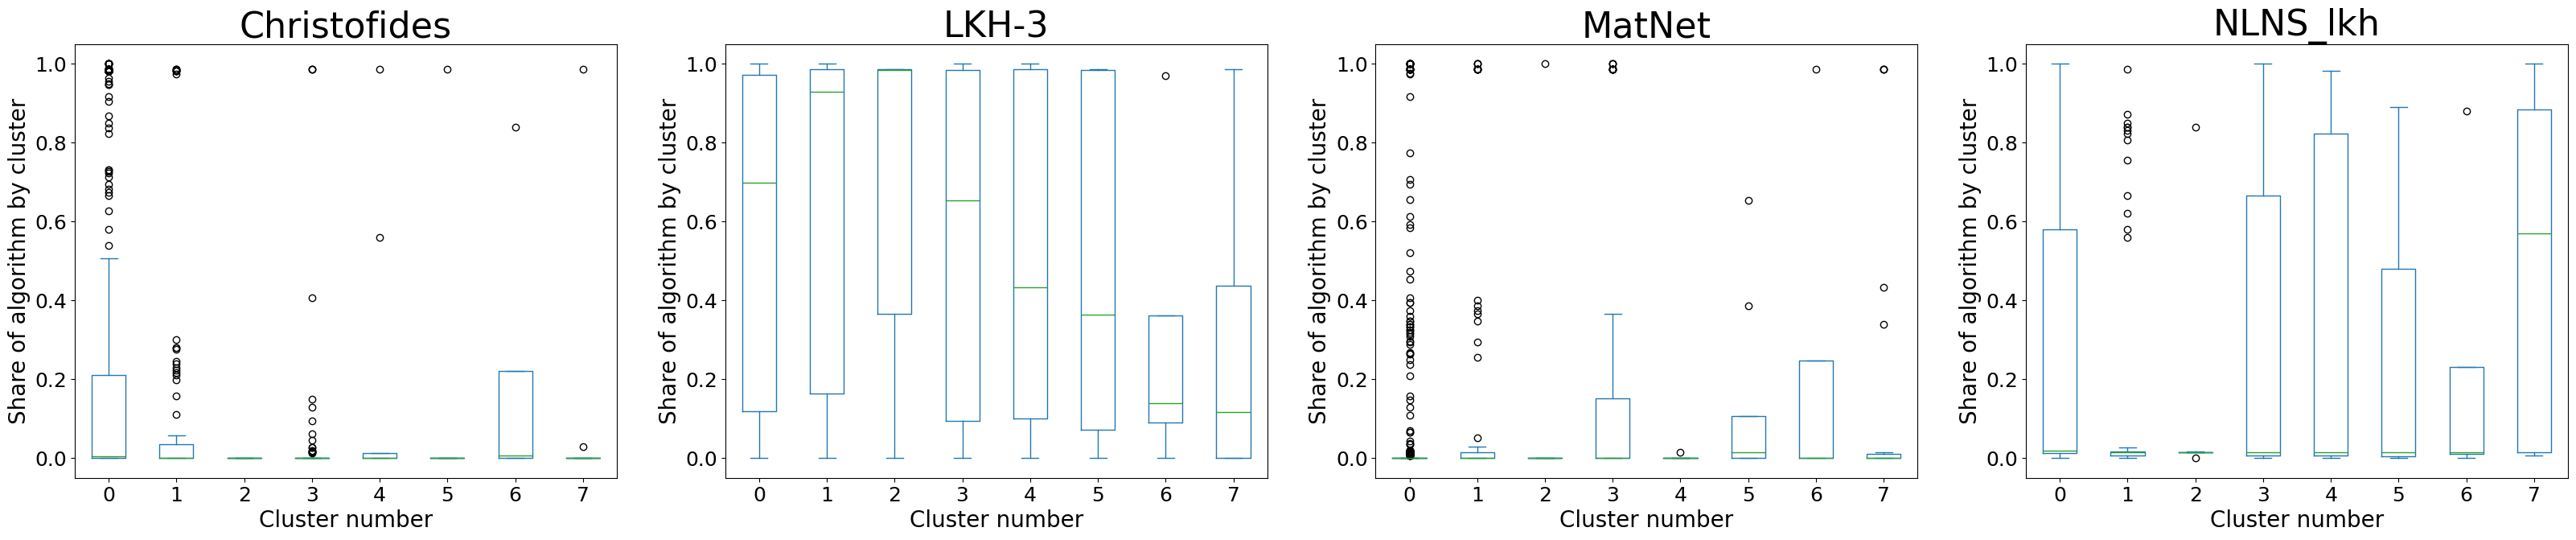

In [25]:
plt.rcParams['axes.titlesize'] = 32
plt.rcParams['axes.labelsize'] = 20

strat_df = pd.DataFrame(strat_data)
strat_df.plot.box(by = ['cluster id'], figsize = (40,7),
                 xlabel = 'Cluster number', ylabel = 'Share of algorithm by cluster',
                 fontsize = 18)

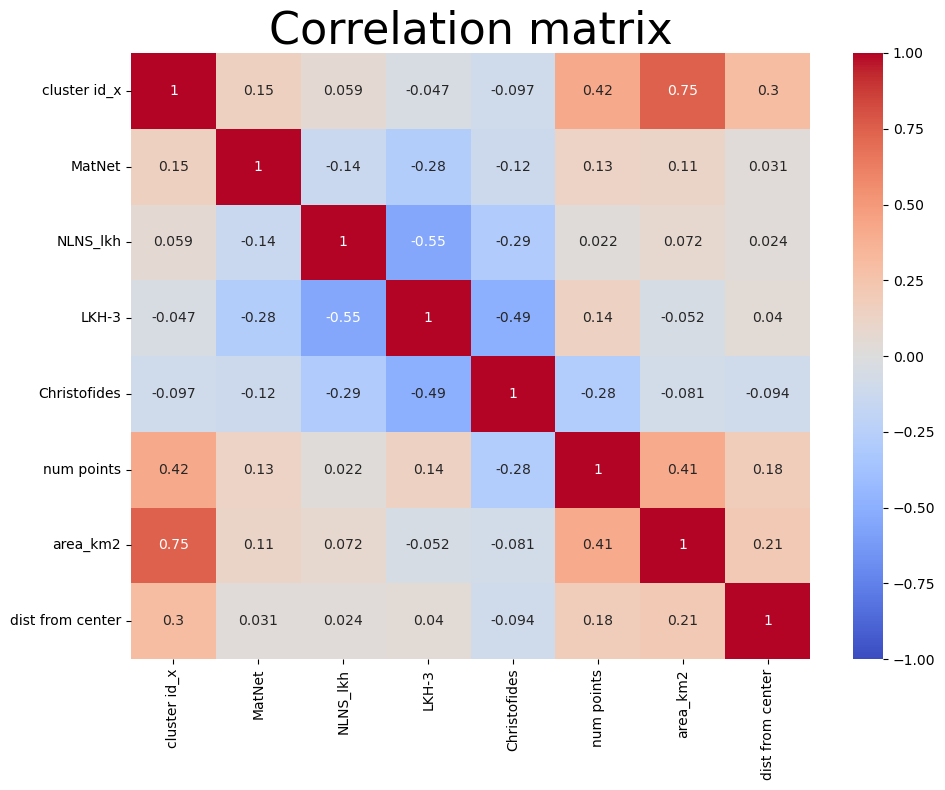

In [26]:
EPOS_df = pd.merge(strat_df, prop_df, on = ['polygon id'], how = 'inner')

feature_columns = ['cluster id_x', 'MatNet', 'NLNS_lkh', 'LKH-3', 'Christofides', 'num points', 'area_km2', 'dist from center']
correlation_matrix = EPOS_df[feature_columns].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1, center=0)
plt.title('Correlation matrix')
plt.tight_layout()
plt.show()

In [27]:
def build_repeated_sequence(polygon_list, max_repeats=50, 
                            frequency_weights=None, seed=42):
    """
    Create a sequence where polygons appear 1 to max_repeats times.
    High-activity polygons (larger, central) appear more often.
    """
    rng = np.random.RandomState(seed)
    sequence = []
    
    for poly in polygon_list:
        # Assign frequency: can be uniform or weighted by polygon activity
        if frequency_weights is not None:
            n_appearances = max(1, int(frequency_weights[poly] * max_repeats))
        else:
            n_appearances = rng.randint(1, max_repeats + 1)
        
        sequence.extend([poly] * n_appearances)
    
    rng.shuffle(sequence)  # Interleave to simulate real arrival order
    return sequence

In [28]:
with open('epos_cache.pkl', 'rb') as f:
    test_epos = pickle.load(f)

In [29]:
EPOS = get_elite_polygons(clusters)

C:\Users\Administrator\AppData\Local\Temp\ipykernel_101952\2165946696.py:11: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  new_polygon_idx = int(rng.integers(0,len(clusters[idx]),1))


In [30]:
raw_testing_sequence = []

for item, val in EPOS.items():
    raw_testing_sequence.extend(val)

In [31]:
#testing_sequence = build_repeated_sequence(list(test_epos.keys())[:100])
testing_seqence = build_repeated_sequence(raw_testing_sequence)
SLA_LKH_3 = {'time_window': {
        1800: [],
        3600: [],
        5400: [],
        7200: []},
                 'comp_time': {
        0.1: [],
        0.5: [],
        1: [],
        2: [],
        5: []}        
    }
SLA_TAPOCB = {'time_window': {
        1800: [],
        3600: [],
        5400: [],
        7200: []},
                 'comp_time': {
        0.1: [],
        0.5: [],
        1: [],
        2: [],
        5: []}
    }

def get_sota_solution(orders, start_point, cost_matrix, sota_alg):
    if sota_alg == 'lkh3':
        route, route_time = solve_lkh_atsp(orders, start_point, cost_matrix, runs=10)
    else:
        route, route_time = 5, 7200
    return route, route_time

def get_full_matrix_test(dist_matrix, orders, start_point, polygon_id):
    perfect_distances = copy.deepcopy(dist_matrix)
    
    basic_orders_IDs = [int(get_basic_order_ID(order)) for order in orders]
    zero_row = [int(get_distance(distance_array, idx_dict, start_point, order)) for order in basic_orders_IDs]

    if type(perfect_distances) == np.ndarray:
        zero_matrix = np.zeros((len(perfect_distances)+1, len(perfect_distances)+1))
        for i in range(n+1):
            for j in range (n+1):
                if i == 0:
                    if j == 0:
                        continue
                    else:
                        zero_matrix[i,j] = int(get_distance(distance_array, idx_dict, start_point, basic_orders_IDs[j-1]))
                elif j == 0:
                    zero_matrix[i,j] = int(get_distance(distance_array, idx_dict, basic_orders_IDs[i-1], start_point))
                else:
                    zero_matrix[i,j] = int(get_distance(distance_array, idx_dict, basic_orders_IDs[i-1], basic_orders_IDs[j-1]))
        return zero_matrix

    else:    
        perfect_distances.insert(0, zero_row)
        print(f'distances matrix len is {len(perfect_distances)} with {polygon_id} polygon ID')
        
        for i, row in enumerate(perfect_distances):
            if i > 0:
                j = i
                perfect_distances[i].insert(0, round(get_distance(distance_array, idx_dict, basic_orders_IDs[j-1], start_point)))
            elif i == 0:
                perfect_distances[i].insert(0, 0)

        return perfect_distances

def eval_client_reward(client_prefs, price, route_time, CT, client_config, polygon):
    #additional = properties[polygon]['num_points']*60
    U = client_config['U']
    CT_SA = client_config['CT_SA']
    client_tw = client_config['time_window']
    delta_tw = client_tw[1] - client_tw[0] - route_time # Убрал отсюда additional, только бесполезно ест перформанс TAPOCB-а
    delta_CT = CT_SA - CT
            
    client_score = 0 if delta_tw < 0 else (
        client_prefs['alpha'] * (U - price)/U +
        client_prefs['beta'] * delta_tw/(client_tw[1] - client_tw[0]) +
        client_prefs['gamma'] * delta_CT/CT_SA
    )
    return client_score
 
def eval_SOTA(polygon, sota_alg):

    agent_id = 318
    
    test_dynamic_config = {'U': 900,
                              'price': 500,
                              'CT_SA': 5, # Крутибельный параметр, влияет на вес параметра скорости вычислений
                              'time_window': (0.0,10800.0) # Крутибельный параметр, можно попробовать им отсекать конфиги, где BC - единственный вариант
                             }
    
    client_config = {
                'client_id': 92,
                'polygon_id': polygon,
                'orders': AUG_global_map[polygon]['full map'],
                'time_window': test_dynamic_config['time_window'],
                'U': test_dynamic_config['U'],
                'price': test_dynamic_config['price'],
                'CT_SA': test_dynamic_config['CT_SA']
                }
    test_config = TAPOCBConfig(
        learning_rate=0.02,
        eta=0.01,
        mu=1000.0,
        convergence_window=20,
        B=43200.0
    )
    
    
    test_tender = copy.copy(client_config) #one config per try
    
    ideal_matrix = AUG_global_map[polygon]['distance matrix'] #here we use AUG_global_map or analogue
    basic_polygon_id = get_basic_poly_ID(test_tender['polygon_id'])
    
    test_sumo = SUMOInterface(
            traffic_alpha=2,
            traffic_beta=2,
            ideal_matrix=ideal_matrix
        )
        
    test_optimizer = OptimizerInterface()
        
    test_agent = TAPOCBAgent(
            agent_id=agent_id,
            config=test_config,
            sumo_interface=test_sumo,
            optimizer_interface=test_optimizer,
            dynamic_threshold = 100
        ) # 0 default start

    courier_position = 0
    orders = [courier_position] + test_tender['orders']

    cost_matrix = np.array(get_full_matrix_test(test_sumo.ideal_matrix, test_tender['orders'], courier_position, polygon))
    
    client_prefs = GLOBAL_PREFERENCES_MAP[polygon]

    visit_counts[polygon] = visit_counts.get(polygon, 0) + 1
    visit_num = visit_counts[polygon]

    # 2. run TAPOCB
    start_t = time.time()

    mlp_policy = run_TAPOCB_NN_inference(
        polygon, mlp_model, metadata
    ).squeeze()

    refined_policy = memory.get_policy(polygon, mlp_policy, rng)
    
    alg_idx = rng.choice(4, p=refined_policy)
    chosen_alg = algorithms[alg_idx]

    # Run selected algorithm
    if chosen_alg == "MatNet":
        route, route_time = test_optimizer.solve_MatNet(orders, 0, cost_matrix)
    elif chosen_alg == "NLNS":
        route, route_time = test_optimizer.solve_NLNS(orders, 0, cost_matrix)
    elif chosen_alg == "lkh3":
        route, route_time = test_optimizer.solve_lkh3(orders, 0, cost_matrix)
    else:
        route, route_time = test_optimizer.solve_Christofides(orders, 0, cost_matrix)

    TAPOCB_ct = time.time() - start_t
    
    TAPOCB_reward = np.clip(eval_client_reward(
        client_prefs,
        client_config['price'],
        route_time,
        TAPOCB_ct,
        client_config,
        polygon
    ), 0, 5)

    for item in SLA_TAPOCB['time_window']:
        if route_time <= item:
            SLA_TAPOCB['time_window'][item].append(route_time)
    for item in SLA_TAPOCB['comp_time']:
        if TAPOCB_ct <= item:
            SLA_TAPOCB['comp_time'][item].append(TAPOCB_ct)

    test_log['polygon_id'].append(polygon)
    test_log['pts_number'].append(len(orders))
    test_log['chosen_alg'].append(chosen_alg)
    test_log['reward'].append(TAPOCB_reward)
    test_log['TAPOCB_ct'].append(TAPOCB_ct)

    # 4. Evaluate SOTA
    
    start_time = time.time()
    route, route_time = get_sota_solution(orders, orders[0], cost_matrix, 'lkh3')
    finish_time = time.time()

    CT = finish_time - start_time
    SOTA_reward = np.clip(eval_client_reward(
        client_prefs,
        client_config['price'],
        route_time,
        CT,
        client_config,
        polygon
    ), 0, 5)

    for item in SLA_LKH_3['time_window']:
        if route_time <= item:
            SLA_LKH_3['time_window'][item].append(route_time)
    for item in SLA_LKH_3['comp_time']:
        if CT <= item:
            SLA_LKH_3['comp_time'][item].append(CT)

    test_log['sota_ct'].append(CT)

    results_test['polygon_id'].append(polygon)
    results_test['chosen_alg'].append(chosen_alg)
    results_test['reward'].append(TAPOCB_reward)
    results_test['policy'].append(refined_policy)

    return TAPOCB_reward, SOTA_reward, chosen_alg, SLA_LKH_3, SLA_TAPOCB, alg_idx

# PIPELINE
TAPOCB_rewards_list = []
SOTA_rewards_list = []

test_log = {
    'polygon_id': [],
    'pts_number': [],
    'chosen_alg': [],
    'reward': [],
    'TAPOCB_ct': [],
    'sota_ct': []
}
test_log_wins = {
    'polygon_id': [],
    'chosen_alg': [],
    'TAPOCB_reward': [],
    'LKH-3_reward': []
}

mlp_model, metadata = load_grand_courier_model()
memory = TAPOCBMemory(gamma_explore=0.15)

rng = np.random.default_rng(42)
algorithms = ["MatNet", "NLNS", "lkh3", "Christofides"]
    
results_test = {
        'polygon_id': [], 'chosen_alg': [], 
        'reward': [], 'is_win': [],
        'policy': []
    }

visit_counts = {}

Loaded model (1600 samples, val_loss=0.8211)


In [ ]:
for polygon in tqdm(testing_seqence):
    try:
        TAPOCB_reward, SOTA_reward, chosen_alg, sla_sota, sla_TAPOCB, alg_index = eval_SOTA(polygon, 'lkh3')
        TAPOCB_rewards_list.append(TAPOCB_reward)
        SOTA_rewards_list.append(SOTA_reward)
    
        if TAPOCB_reward >= SOTA_reward:
            test_log_wins['polygon_id'].append(polygon)
            test_log_wins['chosen_alg'].append(chosen_alg)
            test_log_wins['TAPOCB_reward'].append(TAPOCB_reward)
            test_log_wins['LKH-3_reward'].append(SOTA_reward)
    
        is_win = TAPOCB_reward >= SOTA_reward
    
        results_test['is_win'].append(is_win)
    
        memory.record_outcome(polygon, alg_index, TAPOCB_reward, is_win)
    except Exception as e:
        brokens_list.append(polygon)
        continue

In [ ]:
avg_TAPOCB, std_TAPOCB = np.mean(TAPOCB_rewards_list), np.std(TAPOCB_rewards_list)
avg_SOTA, std_SOTA = np.mean(SOTA_rewards_list), np.std(SOTA_rewards_list)

In [ ]:
policy_test = run_TAPOCB_NN_inference(
        'AUG--AUG-G-344-9-225-7', mlp_model, metadata
    ).squeeze()

In [ ]:
policy_test

In [ ]:
test_epos['AUG--AUG-G-344-9-225-7']

In [ ]:
memory.get_policy('AUG--AUG-G-344-9-225-7', policy_test, rng)

In [ ]:
adf = pd.DataFrame(test_log['polygon_id'])

In [ ]:
adf.nunique()

In [ ]:
new_logic_test_df = pd.DataFrame(results_test)

In [ ]:
new_logic_test_df['polygon_id'].nunique()

In [ ]:
new_logic_test_df.to_excel('test_100_polygons_bandit_10800.xlsx')

In [ ]:
reward_diff = [TAPOCB_rewards_list[i] - SOTA_rewards_list[i] for i in range(len(SOTA_rewards_list))]

In [ ]:
for i in range(20):
    print(TAPOCB_rewards_list[i], SOTA_rewards_list[i])

In [ ]:
ct_diff = [test_log['TAPOCB_ct'][i] - test_log['sota_ct'][i] for i in range(len(test_log['TAPOCB_ct']))]

In [ ]:
np.mean(ct_diff)

In [ ]:
import numpy as np
import scipy.stats as stats

d = reward_diff
cl = 0.95 # confidence level

# confidence interval
ci = stats.t.interval(cl, df=len(d)-1, loc=np.mean(d), scale=np.std(d, ddof=1) / np.sqrt(len(d)))
print(ci)

In [ ]:
loss = []
parity = []
win = []

for i in range(len(d)):
    if d[i] < 0:
        loss.append(d[i])
    elif d[i] == 0:
        parity.append(d[i])
    else:
        win.append(d[i])

In [ ]:
print(f'loss average is {np.mean(loss):.4f} within {len(loss)} observations')
print(f'zero within {len(parity)} observations')
print(f'win average is {np.mean(win):.4f} within {len(win)} observations')

In [ ]:
distr = []
l_and_w = loss + win
uniques = np.unique(l_and_w)

for item in uniques:
    n = d.count(item)
    distr.append(n/len(d))

In [ ]:
len(distr)

In [ ]:
df = pd.DataFrame({"TAPOCB-NN reward": TAPOCB_rewards_list, 
                   "LKH-3 reward": SOTA_rewards_list})

In [ ]:
ax = df.plot.kde(fontsize = 20)
plt.xlabel("Client's satisfaction feedback")
plt.axvline(np.min(TAPOCB_rewards_list), linestyle="-.", color="blue", label="TAPOCB-NN min reward")
plt.axvline(np.max(TAPOCB_rewards_list), linestyle="--", color="blue", label="TAPOCB-NN max reward")
plt.axvline(np.min(SOTA_rewards_list), linestyle="-.", color="green", label="LKH-3 min reward")
plt.axvline(np.max(SOTA_rewards_list), linestyle="--", color="green", label="LKH-3 max reward")
plt.legend()

In [ ]:
for_kde = pd.Series(d)


for_kde.plot.kde()

In [ ]:
from scipy import stats

stats.describe(d)

In [ ]:
wins_per_polygon_ds = {
    'cluster': [],
    'pts_num': [],
    'area_km2': [],
    'distance_from_center_km': []
}

relative_gds = {
    'cluster': [],
    'pts_num': [],
    'area_km2': [],
    'distance_from_center_km': []
}

for pol in test_log_wins['polygon_id']:
    wins_per_polygon_ds['cluster'].append(AUG_global_map[pol]['cluster'])
    wins_per_polygon_ds['pts_num'].append(properties[pol]['num_points'])
    wins_per_polygon_ds['area_km2'].append(properties[pol]['area_km2'])
    wins_per_polygon_ds['distance_from_center_km'].append(properties[pol]['relative_position']['distance_from_center_km'])

for pol in test_log['polygon_id']:
    relative_gds['cluster'].append(AUG_global_map[pol]['cluster'])
    relative_gds['pts_num'].append(properties[pol]['num_points'])
    relative_gds['area_km2'].append(properties[pol]['area_km2'])
    relative_gds['distance_from_center_km'].append(properties[pol]['relative_position']['distance_from_center_km'])

In [ ]:
for item,val in test_log_wins.items():
    print(len(val))

In [ ]:
print(f'resulting values for TAPOCB are: mean - {avg_TAPOCB}, std - {std_TAPOCB}\n')
print(f'resulting values for SOTA lkh3 are: mean - {avg_SOTA}, std - {std_SOTA}\n')
print(f'relative difference is {-(avg_SOTA-avg_TAPOCB)/avg_TAPOCB*100:.5f}%')
print(f"winrate of TAPOCB is {len(test_log_wins['polygon_id'])/len(TAPOCB_rewards_list)*100}%\n")
print(f"average win in winning position is {np.mean(test_log_wins['TAPOCB_reward']):.7f} against {np.mean(test_log_wins['LKH-3_reward']):.7f}\n")

# Вот это дело должно показать relative difference is >0.00%. У меня лучший результат -0.27% на глобальном датасете (1000 полигонов)
# Надо задоминировать LKH-3 на полной выборке

In [ ]:
SOTA_rewards_list_df = pd.DataFrame(SOTA_rewards_list)

In [ ]:
test_log_df = pd.DataFrame(test_log)

In [ ]:
test_log_df['sota compare'] = SOTA_rewards_list_df

In [ ]:
test_log_df['relative diff'] = test_log_df['reward']-test_log_df['sota compare']

In [ ]:
test_log_df.groupby('chosen_alg')['relative diff'].plot.kde(legend = True, title="DataFrame Plot")

In [ ]:
mask = test_log_df['chosen_alg'] != 'lkh3'

reward_diff_df_noLKH = test_log_df[mask]

reward_diff_df_noLKH.groupby('chosen_alg')['relative diff'].plot.kde(legend = True, title="DataFrame Plot")

In [ ]:
test_log_df['relative diff'].describe()

In [ ]:
test_log_df['relative diff'].median()

In [ ]:
test_log_df = pd.DataFrame(test_log)
wins_per_polygon_df = pd.DataFrame(wins_per_polygon_ds)
relative_test_df = pd.DataFrame(relative_gds)

test_log_df.plot.box(by = ['chosen_alg'], figsize = (35,7),
                 xlabel = 'Algorithm', ylabel = 'Share of reward',
                 fontsize = 18)

wins_per_cluster = wins_per_polygon_df.groupby('cluster').size()
wins_per_pts = wins_per_polygon_df.groupby('pts_num').size()
wins_per_area = wins_per_polygon_df.groupby('area_km2').size()
wins_per_rdfc = wins_per_polygon_df.groupby('distance_from_center_km').size()

total_per_cluster = relative_test_df.groupby('cluster').size()
total_per_pts = relative_test_df.groupby('pts_num').size()
total_per_area = relative_test_df.groupby('area_km2').size()
total_per_rdfc = relative_test_df.groupby('distance_from_center_km').size()

In [ ]:
wins_per_cluster

In [ ]:
from itertools import zip_longest
import matplotlib.pyplot as plt

fig, axes = plt.subplots(4, 2, figsize=(15, 10))

# === ROW 0: Cluster ===
# Left: Absolute wins
axes[0, 0].bar(wins_per_cluster.index, wins_per_cluster.values, 
               color='skyblue', edgecolor='black', label='Wins')
axes[0, 0].set_xlabel('Cluster', fontsize=18)
axes[0, 0].set_ylabel('Number of Wins', fontsize=18, color='skyblue')
axes[0, 0].set_title('Wins per Cluster', fontsize=20)
axes[0, 0].set_xticks(range(8))
axes[0, 0].grid(axis='y', alpha=0.3)
axes[0, 0].tick_params(axis='y', labelcolor='skyblue', length = 5)

# Right: Win rate (%) - TWIN AXIS
win_rates_cluster = [w / total_per_cluster.get(i, 1) * 100 
                     for i, w in wins_per_cluster.items()]
axes[0, 1].bar(wins_per_cluster.index, win_rates_cluster, 
               color='navy', edgecolor='black', alpha=0.6, label='Win Rate')
axes[0, 1].set_ylabel('Win Rate (%)', fontsize=18, color='navy')
axes[0, 1].set_xticks(range(8))
axes[0, 1].set_yticks([0, 50, 100])
axes[0, 1].tick_params(axis='y', labelcolor='navy')
axes[0, 1].grid(axis='y', alpha=0.3, linestyle='--')

# === ROW 1: Points Number ===
axes[1, 0].bar(wins_per_pts.index, wins_per_pts.values, 
               color='lightcoral', edgecolor='black')
axes[1, 0].set_xlabel('Mean Points Number', fontsize=18)
axes[1, 0].set_ylabel('Number of Wins', fontsize=18, color='lightcoral')
axes[1, 0].set_title('Wins per Points Number', fontsize=20)
axes[1, 0].set_xticks([15, 30, 45, 60, 75, 90, 110])
axes[1, 0].grid(axis='y', alpha=0.3)
axes[1, 0].tick_params(axis='y', labelcolor='lightcoral')

win_rates_pts = [wins_per_pts.get(pts, 0) / total_per_pts.get(pts, 1) * 100 
                 for pts in wins_per_pts.index]
axes[1, 1].bar(wins_per_pts.index, win_rates_pts, 
               color='darkred', edgecolor='black', alpha=0.6)
axes[1, 1].set_ylabel('Win Rate (%)', fontsize=18, color='darkred')
axes[1, 1].set_xticks([15, 30, 45, 60, 75, 90, 110])
axes[1, 1].set_yticks([0, 50, 100])
axes[1, 1].tick_params(axis='y', labelcolor='darkred')
axes[1, 1].grid(axis='y', alpha=0.3, linestyle='--')

# === ROW 2: Area (histogram) ===
axes[2, 0].hist(wins_per_polygon_df['area_km2'], 
                color='lightgreen', edgecolor='black', bins=20)
axes[2, 0].set_xlabel('Area (km²)', fontsize=18)
axes[2, 0].set_ylabel('Number of Wins', fontsize=18, color='green')
axes[2, 0].set_title('Wins per Area', fontsize=20)
axes[2, 0].grid(axis='y', alpha=0.3)
axes[2, 0].tick_params(axis='y', labelcolor='green')

axes[2, 1].hist(wins_per_polygon_df['area_km2'], 
                weights=[100/len(wins_per_polygon_df)]*len(wins_per_polygon_df),
                color='darkgreen', edgecolor='black', bins=20, alpha=0.6)
axes[2, 1].set_ylabel('WR Density (%)', fontsize=18, color='darkgreen')
axes[2, 1].tick_params(axis='y', labelcolor='darkgreen')
axes[2, 1].grid(axis='y', alpha=0.3, linestyle='--')

# === ROW 3: Distance from Center ===
axes[3, 0].hist(wins_per_polygon_df['distance_from_center_km'], 
                color='orange', edgecolor='black', bins=20, alpha = 0.5)
axes[3, 0].set_xlabel('Distance from Center (km)', fontsize=18)
axes[3, 0].set_ylabel('Number of Wins', fontsize=18, color='orange')
axes[3, 0].set_title('Wins per Distance from Center', fontsize=20)
axes[3, 0].grid(axis='y', alpha=0.3)
axes[3, 0].tick_params(axis='y', labelcolor='orange')

axes[3, 1].hist(wins_per_polygon_df['distance_from_center_km'], 
                weights=[100/len(wins_per_polygon_df)]*len(wins_per_polygon_df),
                color='red', edgecolor='black', bins=20, alpha=0.6)
axes[3, 1].set_ylabel('WR Density (%)', fontsize=18, color='red')
axes[3, 1].tick_params(axis='y', labelcolor='red')
axes[3, 1].grid(axis='y', alpha=0.3, linestyle='--')

# === Global Formatting ===
plt.rcParams['xtick.labelsize'] = 18
plt.rcParams['ytick.labelsize'] = 18
plt.tight_layout()
plt.savefig('TAPOCB_vs_LKH3_wins_plot.png', dpi=300, transparent=True, bbox_inches='tight')
plt.show()

In [32]:
def eval_MATNET_vs_TAPOCB(polygon_id: str,
                        model: MatNet,
                        AUG_global_map: dict,
                        properties: dict,
                        device: str = 'cuda') -> dict:

    orders = AUG_global_map[polygon_id]['full map']
    ideal_matrix = AUG_global_map[polygon_id]['distance matrix']
    dist_matrix = np.array(get_full_matrix_test(ideal_matrix, orders, 0, polygon_id))

    print(f'actual len of dist matrix is {len(dist_matrix)}')
    
    # Generate client preferences
    client_prefs = generate_polygon_config(polygon_id, AUG_global_map, n_clusters=8)
    
    # Client config for welfare calculation
    client_config = {
        'client_id': 92,
        'polygon_id': polygon_id,
        'orders': AUG_global_map[polygon_id]['full map'],
        'time_window': (0.0, 7200.0),
        'U': 900,
        'price': 500,
        'CT_SA': 5
    }
    
    # Build cost matrix (your existing function)
    cost_matrix = np.array(get_full_matrix_test(ideal_matrix, client_config['orders'], 0, polygon_id))

    orders = [0]+client_config['orders']

    test_optimizer = OptimizerInterface()
    
    # === MATNET INFERENCE ===
    start_t = time.time()
    matnet_tour, matnet_route_time = run_matnet_inference(cost_matrix, model, device) # Working correctly
    matnet_ct = time.time() - start_t
    
    # Compute welfare for MatNet solution
    matnet_reward = eval_client_reward(
        client_prefs,
        client_config['price'],
        matnet_route_time,
        matnet_ct,
        client_config,
        polygon_id
    )

    if matnet_reward == 0:
        print(f'POMO reward is {matnet_reward}, debug!\n')
        print(f'matnet route time is {matnet_route_time} and \n')
        print(f'the inference time is {matnet_ct}')
    
    # === TAPOCB INFERENCE (sample from learned policy) ===
    start_t = time.time()
    
    # Sample algorithm from TAPOCB policy
    algorithm = rng.choice(["MatNet", "NLNS", "lkh3", "Christofides"],
                           p=test_epos[polygon_id]['policy'])
    
    # Run selected algorithm
    if algorithm == "MatNet":
        route, route_time = run_matnet_inference(cost_matrix, model, device)
    elif algorithm == "NLNS":
        route, route_time = test_optimizer.solve_NLNS(orders, 0, cost_matrix)
    elif algorithm == "lkh3":
        route, route_time = test_optimizer.solve_lkh3(orders, 0, cost_matrix)
    else:
        route, route_time = test_optimizer.solve_Christofides(orders, 0, cost_matrix)
    
    TAPOCB_ct = time.time() - start_t
    
    # Compute welfare for TAPOCB solution
    TAPOCB_reward = eval_client_reward(
        client_prefs,
        client_config['price'],
        route_time,
        TAPOCB_ct,
        client_config,
        polygon_id
    )
    
    return {
        'polygon_id': polygon_id,
        'matnet_reward': matnet_reward,
        'matnet_time': matnet_route_time,
        'matnet_ct': matnet_ct,
        'TAPOCB_reward': TAPOCB_reward,
        'TAPOCB_time': route_time,
        'TAPOCB_ct': TAPOCB_ct,
        'TAPOCB_algorithm': algorithm,
        'matnet_tour': matnet_tour.tolist()
    }

In [33]:
def eval_MATNET_vs_TAPOCB_NN(polygon_id: str,
                        model: MatNet,
                        AUG_global_map: dict,
                        properties: dict,
                        device: str = 'cuda') -> dict:

    orders = AUG_global_map[polygon_id]['full map']
    ideal_matrix = AUG_global_map[polygon_id]['distance matrix']

    test_optimizer = OptimizerInterface()
    
    # Generate client preferences
    client_prefs = GLOBAL_PREFERENCES_MAP[polygon_id]
    
    # Client config for welfare calculation
    client_config = {
        'client_id': 92,
        'polygon_id': polygon_id,
        'orders': AUG_global_map[polygon_id]['full map'],
        'time_window': (0.0, 43200.0),
        'U': 900,
        'price': 500,
        'CT_SA': 5
    }

    orders = [0]+orders
    cost_matrix = np.array(get_full_matrix_test(ideal_matrix, client_config['orders'], 0, polygon_id))
    
    # === MATNET INFERENCE ===
    start_t = time.time()
    matnet_tour, matnet_route_time = run_matnet_inference(cost_matrix, model, device) # Working correctly
    matnet_ct = time.time() - start_t
    
    # Compute welfare for MatNet solution
    matnet_reward = np.clip(eval_client_reward(
        client_prefs,
        client_config['price'],
        matnet_route_time,
        matnet_ct,
        client_config,
        polygon_id
    ), 0, 5)

    if matnet_reward == 0:
        print(f'POMO reward is {matnet_reward}, debug!\n')
        print(f'matnet route time is {matnet_route_time} and \n')
        print(f'the inference time is {matnet_ct}')
    
    # === TAPOCB INFERENCE (sample from learned policy) ===
    start_t = time.time()

    mlp_policy = run_TAPOCB_NN_inference(
        test_polygon_id, mlp_model, metadata
    ).squeeze()

    refined_policy = memory.get_policy(polygon, mlp_policy, rng)
    
    alg_idx = rng.choice(4, p=refined_policy)
    chosen_alg = algorithms[alg_idx]

    # Run selected algorithm
    if chosen_alg == "MatNet":
        route, route_time = test_optimizer.solve_MatNet(orders, 0, cost_matrix)
    elif chosen_alg == "NLNS":
        route, route_time = test_optimizer.solve_NLNS(orders, 0, cost_matrix)
    elif chosen_alg == "lkh3":
        route, route_time = test_optimizer.solve_lkh3(orders, 0, cost_matrix)
    else:
        route, route_time = test_optimizer.solve_Christofides(orders, 0, cost_matrix)

    TAPOCB_ct = time.time() - start_t
    
    TAPOCB_reward = np.clip(eval_client_reward(
        client_prefs,
        client_config['price'],
        route_time,
        TAPOCB_ct,
        client_config,
        polygon
    ), 0, 5)
    
    return {
        'polygon_id': polygon_id,
        'matnet_reward': matnet_reward,
        'matnet_time': matnet_route_time,
        'matnet_ct': matnet_ct,
        'TAPOCB_reward': TAPOCB_reward,
        'TAPOCB_time': route_time,
        'TAPOCB_ct': TAPOCB_ct,
        'TAPOCB_algorithm': chosen_alg,
        'matnet_tour': matnet_tour.tolist(),
        'policy': refined_policy
    }
    

# ==========================================
# BATCH COMPARISON PIPELINE
# ==========================================

def run_matnet_comparison_pipeline(test_polygons: List[str],
                                   model: MatNet,
                                   AUG_global_map: dict,
                                   properties: dict,
                                   device: str = 'cuda') -> Optional[List[dict]]:
    """
    Run comparison across multiple polygons and return summary results.
    """
    results = []
    TAPOCB_rewards_list = []
    SOTA_rewards_list = []

    mlp_model, metadata = load_grand_courier_model()
    memory = TAPOCBMemory(gamma_explore=0.15)
    
    rng = np.random.default_rng(42)
    algorithms = ["MatNet", "NLNS", "lkh3", "Christofides"]
        
    results_test = {
            'polygon_id': [], 'chosen_alg': [], 
            'reward': [], 'is_win': [],
            'policy': []
        }
    
    visit_counts = {}
            
    avg_TAPOCB, std_TAPOCB = np.mean(TAPOCB_rewards_list), np.std(TAPOCB_rewards_list)
    avg_SOTA, std_SOTA = np.mean(SOTA_rewards_list), np.std(SOTA_rewards_list)
    
    for poly in test_polygons:
        try:
            visit_counts[poly] = visit_counts.get(poly, 0) + 1
            visit_num = visit_counts[poly]
            res = eval_MATNET_vs_TAPOCB_NN(poly, model, AUG_global_map, properties, device)
            results.append(res)
            if res['TAPOCB_reward'] >= res['matnet_reward']:
                test_mn_log_wins['polygon_id'].append(poly)
                test_mn_log_wins['chosen_alg'].append(res['TAPOCB_algorithm'])
                test_mn_log_wins['TAPOCB_reward'].append(res['TAPOCB_reward'])
                test_mn_log_wins['LKH-3_reward'].append(res['matnet_reward'])
    
            results_test['polygon_id'].append(poly)
            results_test['chosen_alg'].append(res['TAPOCB_algorithm'])
            results_test['reward'].append(res['TAPOCB_reward'])
            results_test['policy'].append(res['policy'])
    
            test_log_mn['polygon_id'].append(poly)
            test_log_mn['pts_number'].append(properties[poly]['num_points'])
            test_log_mn['chosen_alg'].append(res['TAPOCB_algorithm'])
            test_log_mn['reward'].append(res['TAPOCB_reward'])
            print(f"✓ Processed {poly}")
        except Exception as e:
            brokens_list.append(poly)
            continue
    
    if not results:
        print("No successful comparisons.")
        return None
    
    # Summary statistics
    matnet_rewards = [r['matnet_reward'] for r in results if r['matnet_reward'] != 0]
    TAPOCB_rewards = [r['TAPOCB_reward'] for r in results if r['matnet_reward'] != 0]
    matnet_wins = sum(1 for m, t in zip(matnet_rewards, TAPOCB_rewards) if m > t)
    
    print("\n"+"="*60)
    print("SIMPLIFIED MATNET vs TAPOCB_NN COMPARISON RESULTS")
    print("="*60)
    print(f"Polygons evaluated: {len(results)}")
    print(f"MATNET avg reward : {np.mean(matnet_rewards):.4f} ± {np.std(matnet_rewards):.4f}")
    print(f"TAPOCB   avg reward : {np.mean(TAPOCB_rewards):.4f} ± {np.std(TAPOCB_rewards):.4f}")
    print(f"MATNET wins      : {matnet_wins}/{len(results)} ({matnet_wins/len(results)*100:.1f}%)")
    if abs(np.mean(TAPOCB_rewards)) > 1e-8:
        rel_diff = (np.mean(matnet_rewards) - np.mean(TAPOCB_rewards)) / abs(np.mean(TAPOCB_rewards)) * 100
        print(f"Relative diff    : {rel_diff:+.2f}%")
    print("="*60)
    
    return results, results_test, visit_counts

In [34]:
if __name__ == '__main__':
    test_log_mn = {
        'polygon_id': [],
        'pts_number': [],
        'chosen_alg': [],
        'reward': []
    }
    test_mn_log_wins = {
        'polygon_id': [],
        'chosen_alg': [],
        'TAPOCB_reward': [],
        'LKH-3_reward': []
    }    

    comparison_results, debug, visits = run_matnet_comparison_pipeline(testing_seqence, MATNET_MODEL, AUG_global_map, properties, device)

    wins_per_polygon_ds_mn = {
    'cluster': [],
    'pts_num': [],
    'area_km2': [],
    'distance_from_center_km': []
    }
    
    relative_gds_mn = {
        'cluster': [],
        'pts_num': [],
        'area_km2': [],
        'distance_from_center_km': []
    }

Loaded model (1600 samples, val_loss=0.8211)
distances matrix len is 61 with AUG--G-373-2-306 polygon ID


C:\Users\Administrator\.conda\envs\ml_env\lib\site-packages\numpy\_core\fromnumeric.py:3860: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
C:\Users\Administrator\.conda\envs\ml_env\lib\site-packages\numpy\_core\_methods.py:145: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
C:\Users\Administrator\.conda\envs\ml_env\lib\site-packages\numpy\_core\_methods.py:223: RuntimeWarning: Degrees of freedom <= 0 for slice
  ret = _var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
C:\Users\Administrator\.conda\envs\ml_env\lib\site-packages\numpy\_core\_methods.py:181: RuntimeWarning: invalid value encountered in divide
  arrmean = um.true_divide(arrmean, div, out=arrmean,
C:\Users\Administrator\.conda\envs\ml_env\lib\site-packages\numpy\_core\_methods.py:215: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


distances matrix len is 16 with AUG--G-328-1-210 polygon ID
distances matrix len is 61 with AUG--G-92-1-6 polygon ID
distances matrix len is 16 with AUG--AUG-G-253-7-320-3 polygon ID
distances matrix len is 58 with AUG--AUG-G-252-1-186-5 polygon ID
distances matrix len is 61 with AUG--AUG-G-218-1-24-3 polygon ID
distances matrix len is 26 with AUG--AUG-G-79-6-40-3 polygon ID
distances matrix len is 44 with AUG--AUG-G-28-1-334-4 polygon ID
distances matrix len is 16 with AUG--AUG-G-334-1-214-3 polygon ID
distances matrix len is 16 with AUG--AUG-G-328-2-211-4 polygon ID
distances matrix len is 61 with AUG--AUG-G-351-1-229-7 polygon ID
distances matrix len is 61 with AUG--AUG-G-442-1-290-2 polygon ID
distances matrix len is 31 with AUG--AUG-G-315-1-202-8 polygon ID
distances matrix len is 76 with AUG--AUG-G-209-1-179-3 polygon ID
distances matrix len is 60 with AUG--AUG-G-428-1-283-6 polygon ID
distances matrix len is 31 with AUG--AUG-G-77-3-352-6 polygon ID
distances matrix len is 46 wit

TypeError: cannot unpack non-iterable NoneType object

In [ ]:
comparison_results

In [60]:
len(comparison_results)

2405

In [333]:
count_z = 0
for item in comparison_results:
    if item['matnet_reward'] == 0:
        count_z+=1

print(count_z/len(comparison_results))

0.0


In [108]:
for pol in test_mn_log_wins['polygon_id']:
        wins_per_polygon_ds_mn['cluster'].append(AUG_global_map[pol]['cluster'])
        wins_per_polygon_ds_mn['pts_num'].append(properties[pol]['num_points'])
        wins_per_polygon_ds_mn['area_km2'].append(properties[pol]['area_km2'])
        wins_per_polygon_ds_mn['distance_from_center_km'].append(properties[pol]['relative_position']['distance_from_center_km'])
    
for pol in test_log_mn['polygon_id']:
        relative_gds_mn['cluster'].append(AUG_global_map[pol]['cluster'])
        relative_gds_mn['pts_num'].append(properties[pol]['num_points'])
        relative_gds_mn['area_km2'].append(properties[pol]['area_km2'])
        relative_gds_mn['distance_from_center_km'].append(properties[pol]['relative_position']['distance_from_center_km'])

In [110]:
tapoc_diff = []
tapoc_loss = []
tapoc_parity = []
tapoc_win = []
winners_sequence_tapoc = []
winners_sequence_matnet = []

for item in comparison_results:
    tapoc_diff.append(item['TAPOCB_reward'] - item['matnet_reward'])
    if item['matnet_reward'] > item['TAPOCB_reward']:
        tapoc_loss.append(item['TAPOCB_reward'] - item['matnet_reward'])
    elif item['matnet_reward'] == item['TAPOCB_reward']:
        tapoc_parity.append(0)
    else:
        tapoc_win.append(item['TAPOCB_reward'] - item['matnet_reward'])

In [111]:
np.mean(tapoc_diff)

np.float64(-0.012991218256073257)

In [133]:
winners_sequence_tapoc = []
winners_sequence_matnet = []

for item in tapoc_diff:
    if item > 0:
        winners_sequence_tapoc.append(1)
        winners_sequence_matnet.append(0)
    elif item == 0:
        winners_sequence_matnet.append(0)
        winners_sequence_tapoc.append(0)
    else:
        winners_sequence_matnet.append(1)
        winners_sequence_tapoc.append(0)

cs_winners_sequence_tapoc = np.cumsum(winners_sequence_tapoc)
cs_winners_sequence_matnet = np.cumsum(winners_sequence_matnet)

In [112]:
print(f'loss average is {np.mean(tapoc_loss):.2f} within {len(tapoc_loss)} observations')
print(f'zero within {len(tapoc_parity)} observations')
print(f'win average is {np.mean(tapoc_win):.2f} within {len(tapoc_win)} observations')

loss average is -0.05 within 1419 observations
zero within 267 observations
win average is 0.01 within 1800 observations


In [113]:
l_and_w = tapoc_loss+tapoc_parity+tapoc_win
tapocB_rewards = []
MatNet_rewards = []
MN2MN_compare = []


for item in comparison_results:
    tapocB_rewards.append(item['TAPOCB_reward'])
    MatNet_rewards.append(item['matnet_reward'])
    if item['TAPOCB_algorithm'] == 'MatNet':
        MN2MN_compare.append(item['TAPOCB_reward']-item['matnet_reward'])

MN2MN_df = pd.DataFrame(MN2MN_compare)

In [144]:
pd.DataFrame(tapoc_diff).describe()

,0
count,3486.000000
mean,-0.012991
std,0.060202
min,-0.742317
25%,-0.005483
50%,0.000054
75%,0.009125
max,0.057641


array([<Axes: >, <Axes: >], dtype=object)

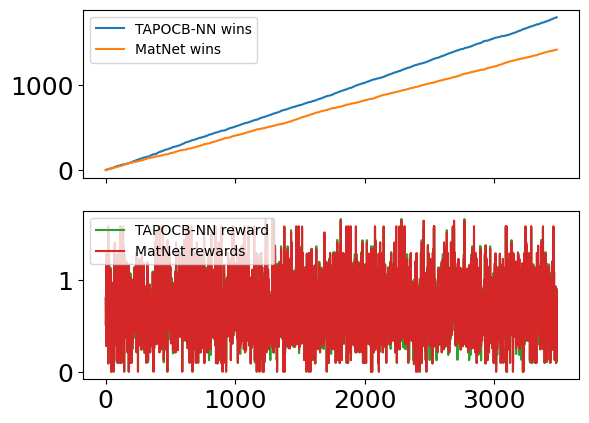

In [139]:
df_cs_wins = pd.DataFrame({'TAPOCB-NN wins': cs_winners_sequence_tapoc,
                           'MatNet wins': cs_winners_sequence_matnet,
                           'TAPOCB-NN reward': tapocB_rewards,
                          'MatNet rewards': MatNet_rewards})

df_cs_wins.plot(subplots = [('TAPOCB-NN wins', 'MatNet wins'),('TAPOCB-NN reward','MatNet rewards')])

In [140]:
df_matnet = pd.DataFrame({"TAPOCB-NN reward": tapocB_rewards, 
                   "MatNet reward": MatNet_rewards})

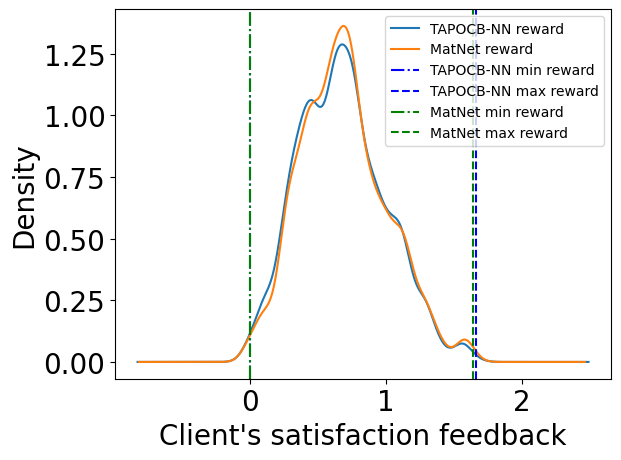

In [141]:
ax = df_matnet.plot.kde(fontsize = 20)
plt.xlabel("Client's satisfaction feedback")
plt.axvline(np.min(tapocB_rewards), linestyle="-.", color="blue", label="TAPOCB-NN min reward")
plt.axvline(np.max(tapocB_rewards), linestyle="--", color="blue", label="TAPOCB-NN max reward")
plt.axvline(np.min(MatNet_rewards), linestyle="-.", color="green", label="MatNet min reward")
plt.axvline(np.max(MatNet_rewards), linestyle="--", color="green", label="MatNet max reward")
plt.legend()

<Axes: ylabel='Density'>

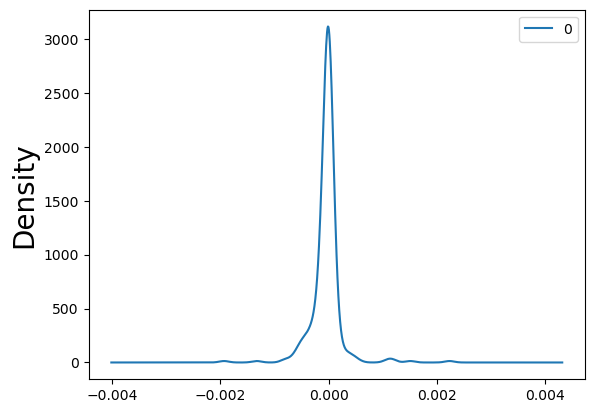

In [116]:
MN2MN_df.plot.kde()

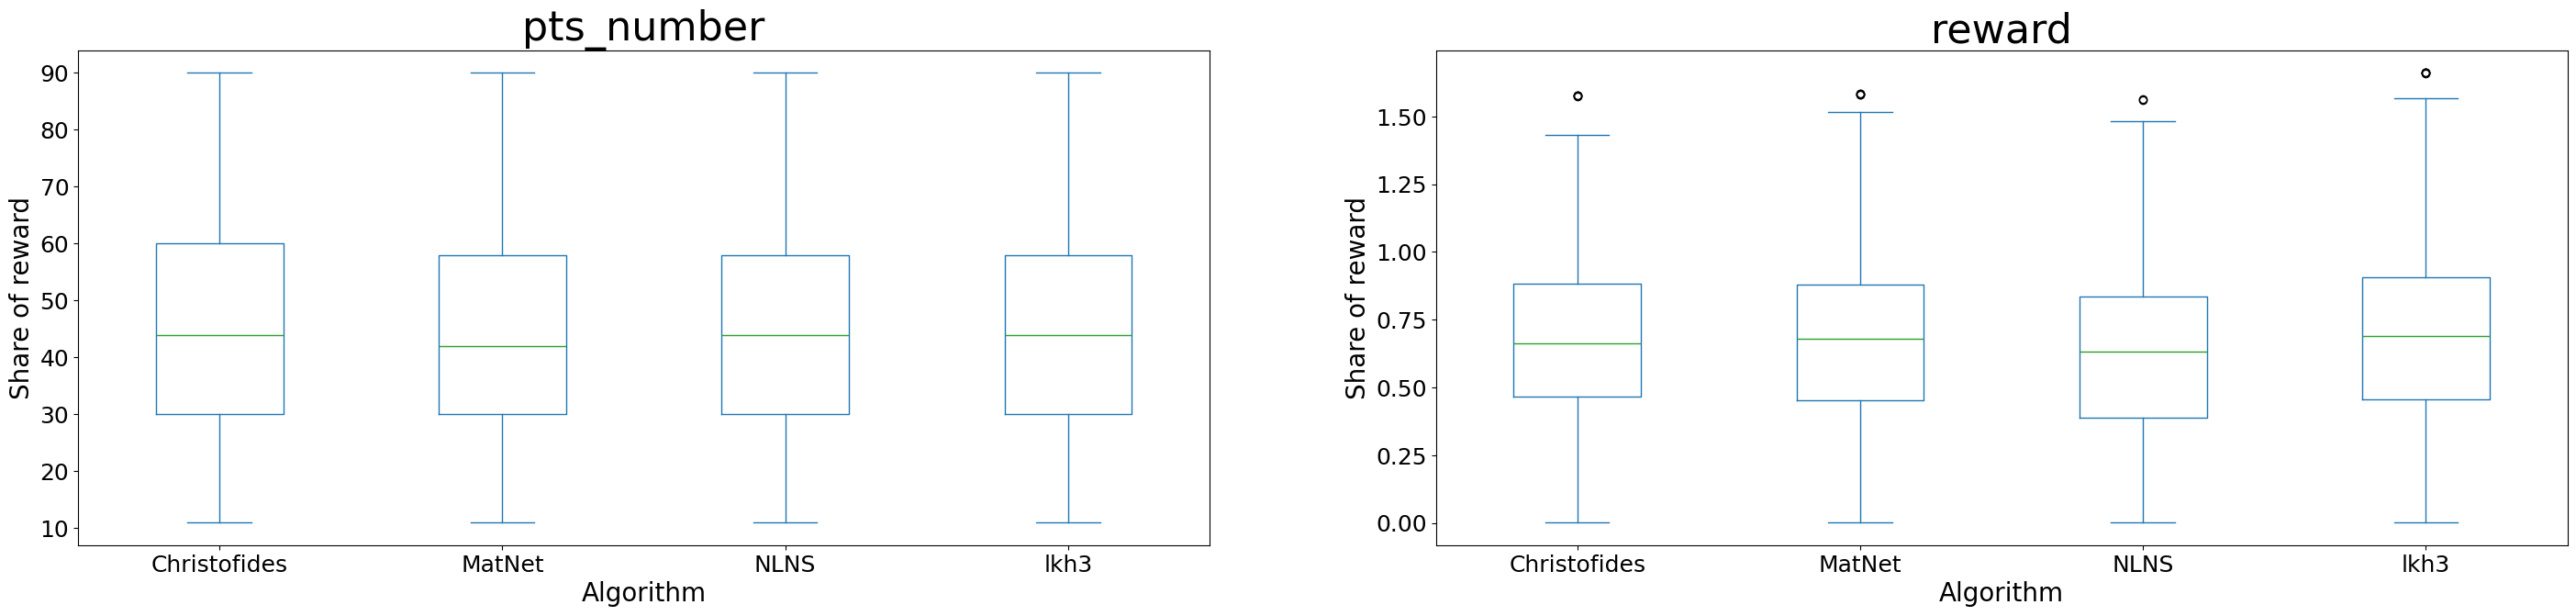

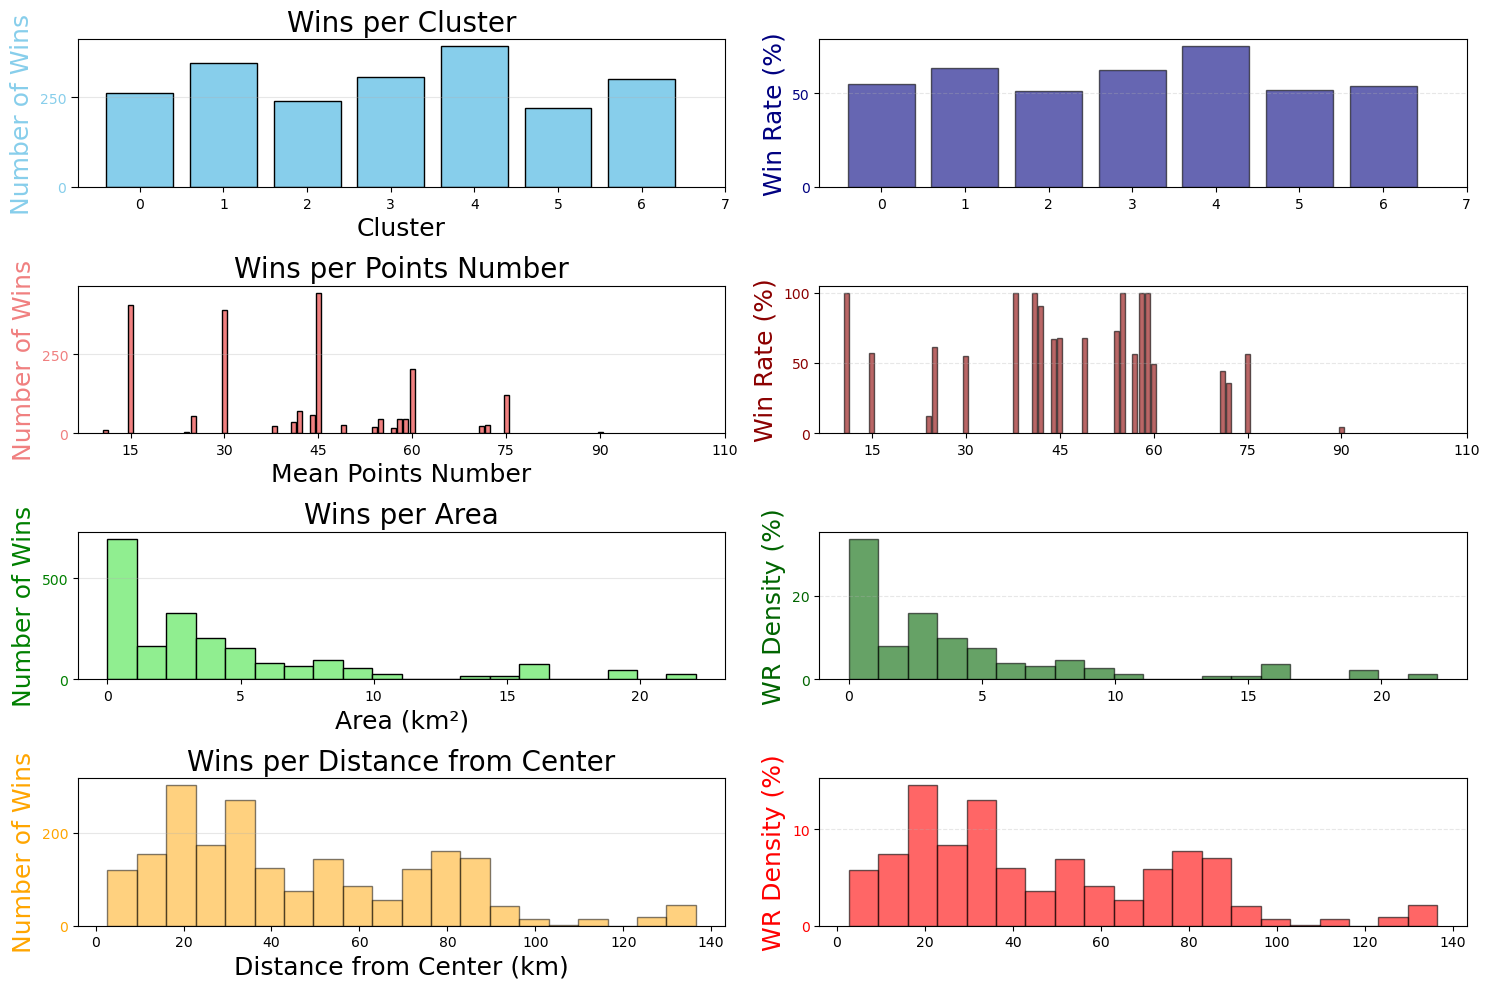

In [120]:
    test_log_df = pd.DataFrame(test_log_mn)
    wins_per_polygon_df = pd.DataFrame(wins_per_polygon_ds_mn)
    relative_test_df = pd.DataFrame(relative_gds_mn)
    
    test_log_df.plot.box(by = ['chosen_alg'], figsize = (35,7),
                     xlabel = 'Algorithm', ylabel = 'Share of reward',
                     fontsize = 18)
    
    wins_per_cluster = wins_per_polygon_df.groupby('cluster').size()
    wins_per_pts = wins_per_polygon_df.groupby('pts_num').size()
    wins_per_area = wins_per_polygon_df.groupby('area_km2').size()
    wins_per_rdfc = wins_per_polygon_df.groupby('distance_from_center_km').size()
    
    total_per_cluster = relative_test_df.groupby('cluster').size()
    total_per_pts = relative_test_df.groupby('pts_num').size()
    total_per_area = relative_test_df.groupby('area_km2').size()
    total_per_rdfc = relative_test_df.groupby('distance_from_center_km').size()

    from itertools import zip_longest
    import matplotlib.pyplot as plt
    
    fig, axes = plt.subplots(4, 2, figsize=(15, 10))
    
    # === ROW 0: Cluster ===
    # Left: Absolute wins
    axes[0, 0].bar(wins_per_cluster.index, wins_per_cluster.values, 
                   color='skyblue', edgecolor='black', label='Wins')
    axes[0, 0].set_xlabel('Cluster', fontsize=18)
    axes[0, 0].set_ylabel('Number of Wins', fontsize=18, color='skyblue')
    axes[0, 0].set_title('Wins per Cluster', fontsize=20)
    axes[0, 0].set_xticks(range(8))
    axes[0, 0].grid(axis='y', alpha=0.3)
    axes[0, 0].tick_params(axis='y', labelcolor='skyblue', length = 5)
    
    # Right: Win rate (%) - TWIN AXIS
    win_rates_cluster = [w / total_per_cluster.get(i, 1) * 100 
                         for i, w in wins_per_cluster.items()]
    axes[0, 1].bar(wins_per_cluster.index, win_rates_cluster, 
                   color='navy', edgecolor='black', alpha=0.6, label='Win Rate')
    axes[0, 1].set_ylabel('Win Rate (%)', fontsize=18, color='navy')
    axes[0, 1].set_xticks(range(8))
    axes[0, 1].tick_params(axis='y', labelcolor='navy')
    axes[0, 1].grid(axis='y', alpha=0.3, linestyle='--')
    
    # === ROW 1: Points Number ===
    axes[1, 0].bar(wins_per_pts.index, wins_per_pts.values, 
                   color='lightcoral', edgecolor='black')
    axes[1, 0].set_xlabel('Mean Points Number', fontsize=18)
    axes[1, 0].set_ylabel('Number of Wins', fontsize=18, color='lightcoral')
    axes[1, 0].set_title('Wins per Points Number', fontsize=20)
    axes[1, 0].set_xticks([15, 30, 45, 60, 75, 90, 110])
    axes[1, 0].grid(axis='y', alpha=0.3)
    axes[1, 0].tick_params(axis='y', labelcolor='lightcoral')
    
    win_rates_pts = [wins_per_pts.get(pts, 0) / total_per_pts.get(pts, 1) * 100 
                     for pts in wins_per_pts.index]
    axes[1, 1].bar(wins_per_pts.index, win_rates_pts, 
                   color='darkred', edgecolor='black', alpha=0.6)
    axes[1, 1].set_ylabel('Win Rate (%)', fontsize=18, color='darkred')
    axes[1, 1].set_xticks([15, 30, 45, 60, 75, 90, 110])
    axes[1, 1].set_yticks([0, 50, 100])    
    axes[1, 1].tick_params(axis='y', labelcolor='darkred')
    axes[1, 1].grid(axis='y', alpha=0.3, linestyle='--')
    
    # === ROW 2: Area (histogram) ===
    axes[2, 0].hist(wins_per_polygon_df['area_km2'], 
                    color='lightgreen', edgecolor='black', bins=20)
    axes[2, 0].set_xlabel('Area (km²)', fontsize=18)
    axes[2, 0].set_ylabel('Number of Wins', fontsize=18, color='green')
    axes[2, 0].set_title('Wins per Area', fontsize=20)
    axes[2, 0].grid(axis='y', alpha=0.3)
    axes[2, 0].tick_params(axis='y', labelcolor='green')
    
    axes[2, 1].hist(wins_per_polygon_df['area_km2'], 
                    weights=[100/len(wins_per_polygon_df)]*len(wins_per_polygon_df),
                    color='darkgreen', edgecolor='black', bins=20, alpha=0.6)
    axes[2, 1].set_ylabel('WR Density (%)', fontsize=18, color='darkgreen')
    axes[2, 1].tick_params(axis='y', labelcolor='darkgreen')
    axes[2, 1].grid(axis='y', alpha=0.3, linestyle='--')
    
    # === ROW 3: Distance from Center ===
    axes[3, 0].hist(wins_per_polygon_df['distance_from_center_km'], 
                    color='orange', edgecolor='black', bins=20, alpha = 0.5)
    axes[3, 0].set_xlabel('Distance from Center (km)', fontsize=18)
    axes[3, 0].set_ylabel('Number of Wins', fontsize=18, color='orange')
    axes[3, 0].set_title('Wins per Distance from Center', fontsize=20)
    axes[3, 0].grid(axis='y', alpha=0.3)
    axes[3, 0].tick_params(axis='y', labelcolor='orange')
    
    axes[3, 1].hist(wins_per_polygon_df['distance_from_center_km'], 
                    weights=[100/len(wins_per_polygon_df)]*len(wins_per_polygon_df),
                    color='red', edgecolor='black', bins=20, alpha=0.6)
    axes[3, 1].set_ylabel('WR Density (%)', fontsize=18, color='red')
    axes[3, 1].tick_params(axis='y', labelcolor='red')
    axes[3, 1].grid(axis='y', alpha=0.3, linestyle='--')
    
    # === Global Formatting ===
    plt.rcParams['xtick.labelsize'] = 18
    plt.rcParams['ytick.labelsize'] = 18
    plt.tight_layout()
    plt.savefig('TAPOCB_vs_LKH3_wins_plot.png', dpi=300, transparent=True, bbox_inches='tight')
    plt.show()

In [147]:
!pip install vrplib


[notice] A new release of pip is available: 26.1.1 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [37]:
import numpy as np
import re

def load_tsplib_atsp(file_path):
    """
    Robust parser for TSPLIB ATSP instances (FULL_MATRIX format).
    Bypasses vrplib's line-break formatting issues.
    """
    with open(file_path, 'r') as f:
        text = f.read()
    
    # 1. Extract the Dimension (N)
    dim_match = re.search(r'DIMENSION\s*:\s*(\d+)', text, re.IGNORECASE)
    if not dim_match:
        raise ValueError("Could not find DIMENSION in the file.")
    n = int(dim_match.group(1))
    
    # 2. Extract everything between EDGE_WEIGHT_SECTION and EOF
    section_match = re.search(r'EDGE_WEIGHT_SECTION(.*?)(?:EOF|$)', text, re.IGNORECASE | re.DOTALL)
    if not section_match:
        raise ValueError("Could not find EDGE_WEIGHT_SECTION in the file.")
    
    weights_str = section_match.group(1)
    
    # 3. Extract ALL integers (ignores spaces, newlines, tabs)
    weights = [int(x) for x in re.findall(r'-?\d+', weights_str)]
    
    # 4. Validate and Reshape into (N, N)
    expected_size = n * n
    if len(weights) != expected_size:
        raise ValueError(f"Data mismatch: Expected {expected_size} values for a {n}x{n} matrix, but found {len(weights)}.")
        
    matrix = np.array(weights, dtype=np.float32).reshape((n, n))

    for i in range(n):
        matrix[i,0] = 1e-3
    
    # 5. CRITICAL FIX: TSPLIB puts massive numbers (e.g., 99999) on the diagonal 
    # to prevent solvers from staying in place. We must force them to 0.
    np.fill_diagonal(matrix, 0)
    
    print(f"✅ Successfully loaded {file_path}")
    print(f"   Matrix shape: {matrix.shape}")
    print(f"   Min distance: {matrix[matrix > 0].min():.2f} | Max distance: {matrix.max():.2f}")
    
    return matrix

# ==========================================
# Usage for your TAPOCB-NN Benchmark
# ==========================================
file_path = 'courier_models/ft53.atsp'
dist_matrix = load_tsplib_atsp(file_path)

# Now dist_matrix is a clean (53, 53) numpy array ready for MatNet / LKH-3 / TAPOCB!

✅ Successfully loaded courier_models/ft53.atsp
   Matrix shape: (53, 53)
   Min distance: 0.00 | Max distance: 1834.00


In [38]:
benchmark_validation_set = defaultdict()

ATSP_INSTANCES = ['courier_models/br17.atsp',
                  'courier_models/ft53.atsp',
                  'courier_models/ft70.atsp',
                  'courier_models/ftv33.atsp',
                  'courier_models/ftv38.atsp',
                  'courier_models/ftv35.atsp',
                  'courier_models/ftv44.atsp',
                  'courier_models/ftv47.atsp',
                  'courier_models/ftv55.atsp',
                  'courier_models/ftv64.atsp',
                  'courier_models/ftv70.atsp',
                  'courier_models/kro124p.atsp',
                  'courier_models/p43.atsp',
                  'courier_models/ry48p.atsp']

for instance in ATSP_INSTANCES:

    pid = 'ATSP_IN'+str(ATSP_INSTANCES.index(instance))

    matrix = load_tsplib_atsp(instance)

    orders = [pid+str(i) for i,_ in enumerate(matrix[0])]

    prefs = {'alpha': np.clip(rng.normal(0.5, 0.5), 0.01, 0.99),
             'beta': np.clip(rng.normal(0.5, 0.5), 0.01, 0.99),
             'gamma': np.clip(rng.normal(0.5, 0.5), 0.01, 0.99)}
    
    supp_dict = {'distance matrix': matrix,
                 'preferences': prefs,
                 'full map': orders,
                 'num_points': len(orders)
                }

    benchmark_validation_set[pid] = supp_dict

✅ Successfully loaded courier_models/br17.atsp
   Matrix shape: (17, 17)
   Min distance: 0.00 | Max distance: 74.00
✅ Successfully loaded courier_models/ft53.atsp
   Matrix shape: (53, 53)
   Min distance: 0.00 | Max distance: 1834.00
✅ Successfully loaded courier_models/ft70.atsp
   Matrix shape: (70, 70)
   Min distance: 0.00 | Max distance: 2588.00
✅ Successfully loaded courier_models/ftv33.atsp
   Matrix shape: (34, 34)
   Min distance: 0.00 | Max distance: 332.00
✅ Successfully loaded courier_models/ftv38.atsp
   Matrix shape: (39, 39)
   Min distance: 0.00 | Max distance: 332.00
✅ Successfully loaded courier_models/ftv35.atsp
   Matrix shape: (36, 36)
   Min distance: 0.00 | Max distance: 332.00
✅ Successfully loaded courier_models/ftv44.atsp
   Matrix shape: (45, 45)
   Min distance: 0.00 | Max distance: 332.00
✅ Successfully loaded courier_models/ftv47.atsp
   Matrix shape: (48, 48)
   Min distance: 0.00 | Max distance: 348.00
✅ Successfully loaded courier_models/ftv55.atsp
  

In [58]:
matnet_tour, matnet_route_time = run_matnet_inference(benchmark_validation_set['ATSP_IN2']['distance matrix'], MATNET_MODEL, device)

In [59]:
matnet_tour

array([ 0, 36, 15, 37, 38, 20, 39, 40, 11, 42, 43, 48, 49, 57,  1,  2,  3,
        4,  5,  7,  8,  9, 10, 12, 13, 14, 16, 17, 18, 19, 21, 22, 23, 24,
       25, 26, 27, 28, 29, 30, 31, 32, 41, 51, 44,  6, 33, 34, 45, 46, 47,
       50, 52, 53, 54, 55, 56, 62, 65, 61, 63, 58, 59, 60, 68, 67, 64, 66,
       69, 35])

In [60]:
matnet_route_time

61823.0

In [61]:
route, route_time = get_sota_solution(benchmark_validation_set['ATSP_IN2']['full map'], 0, benchmark_validation_set['ATSP_IN2']['distance matrix'], 'lkh3')

In [62]:
route_time

np.float32(37230.0)

In [63]:
benchmark_list = build_repeated_sequence(benchmark_validation_set.keys(), max_repeats = 500)

In [64]:
len(benchmark_list)

3245

In [65]:
def eval_benchmark(polygon, properties):
    
    agent_id = 318
    
    test_dynamic_config = {'U': 900,
                              'price': 500,
                              'CT_SA': 10, # Крутибельный параметр, влияет на вес параметра скорости вычислений
                              'time_window': (0.0,43200.0) # Крутибельный параметр, можно попробовать им отсекать конфиги, где BC - единственный вариант
                             }
    
    client_config = {
                'client_id': 92,
                'polygon_id': polygon,
                'orders': properties[polygon]['full map'],
                'time_window': test_dynamic_config['time_window'],
                'U': test_dynamic_config['U'],
                'price': test_dynamic_config['price'],
                'CT_SA': test_dynamic_config['CT_SA']
                }
    test_config = TAPOCBConfig(
        learning_rate=0.02,
        eta=0.01,
        mu=1000.0,
        convergence_window=20,
        B=43200.0
    )
    
    
    test_tender = copy.copy(client_config) #one config per try
    
    ideal_matrix = properties[polygon]['distance matrix'] #here we use AUG_global_map or analogue
    
    test_sumo = SUMOInterface(
            traffic_alpha=2,
            traffic_beta=2,
            ideal_matrix=ideal_matrix
        )
        
    test_optimizer = OptimizerInterface()
        
    test_agent = TAPOCBAgent(
            agent_id=agent_id,
            config=test_config,
            sumo_interface=test_sumo,
            optimizer_interface=test_optimizer,
            dynamic_threshold = 100
        ) # 0 default start

    orders = properties[polygon]['full map']

    cost_matrix = ideal_matrix
    
    client_prefs = properties[polygon]['preferences']

    visit_counts[polygon] = visit_counts.get(polygon, 0) + 1
    visit_num = visit_counts[polygon]

    # 2. run TAPOCB
    start_t = time.time()

    mlp_policy = run_TAPOCB_NN_inference(
        polygon, mlp_model, metadata, 0, 0
    ).squeeze()

    refined_policy = memory.get_policy(polygon, mlp_policy, rng)
    
    alg_idx = rng.choice(4, p=refined_policy)
    chosen_alg = algorithms[alg_idx]

    # Run selected algorithm
    if chosen_alg == "MatNet":
        route, route_time = test_optimizer.solve_MatNet(orders, 0, cost_matrix)
    elif chosen_alg == "NLNS":
        route, route_time = test_optimizer.solve_NLNS(orders, 0, cost_matrix)
    elif chosen_alg == "lkh3":
        route, route_time = test_optimizer.solve_lkh3(orders, 0, cost_matrix)
    else:
        route, route_time = test_optimizer.solve_Christofides(orders, 0, cost_matrix)

    TAPOCB_ct = time.time() - start_t
    
    TAPOCB_reward = np.clip(eval_client_reward(
        client_prefs,
        client_config['price'],
        route_time,
        TAPOCB_ct,
        client_config,
        polygon
    ), 0, 5)

    # 4. Evaluate LKH-3
    
    start_time = time.time()
    route, route_time = get_sota_solution(orders, 0, cost_matrix, 'lkh3')
    finish_time = time.time()

    CT = finish_time - start_time
    LKH_reward = np.clip(eval_client_reward(
        client_prefs,
        client_config['price'],
        route_time,
        CT,
        client_config,
        polygon
    ), 0, 5)

    # Evaluate MatNet

    start_t = time.time()
    matnet_tour, matnet_route_time = run_matnet_inference(cost_matrix, MATNET_MODEL, device) # Working correctly
    matnet_ct = time.time() - start_t
    
    # Compute welfare for MatNet solution
    matnet_reward = np.clip(eval_client_reward(
        client_prefs,
        client_config['price'],
        matnet_route_time,
        matnet_ct,
        client_config,
        polygon_id
    ), 0, 5)

    return TAPOCB_reward, LKH_reward, matnet_reward, chosen_alg, alg_idx

In [66]:
def test_benchmark(test_list, global_dataset):
    
    brokens_bench = []
    rng = np.random.default_rng(43)
    algorithms = ["MatNet", "NLNS", "lkh3", "Christofides"]
    memory_bench = TAPOCBMemory(gamma_explore=0.15)
    res = {}
    
    visit_counts = {}
            
    avg_TAPOCB, std_TAPOCB = np.mean(TAPOCB_rewards_list), np.std(TAPOCB_rewards_list)
    avg_SOTA, std_SOTA = np.mean(SOTA_rewards_list), np.std(SOTA_rewards_list)

    results = {'polygon_id': [],
               'chosen_alg': [],
               'TAPOCB-NN reward': [],
               'LKH-3 reward': [],
               'MatNet reward': []
              }

    for poly_id in tqdm(test_list):
        #try:
        TAPOCB_reward, LKH_reward, matnet_reward, chosen_alg, alg_idx = eval_benchmark(poly_id, global_dataset)
    
        results['polygon_id'].append(poly_id)
        results['chosen_alg'].append(chosen_alg)
        results['TAPOCB-NN reward'].append(TAPOCB_reward)
        results['LKH-3 reward'].append(LKH_reward)
        results['MatNet reward'].append(matnet_reward)
        
        is_win = (TAPOCB_reward >= LKH_reward) and (TAPOCB_reward >= matnet_reward)
        
        memory_bench.record_outcome(poly_id, alg_idx, TAPOCB_reward, is_win)
        #except Exception as e:
            #print(e)
            #brokens_bench.append(poly_id)
            #continue
    
    if not results:
        print("No successful comparisons.")
        return None

    return results, brokens_bench

In [67]:
resulting_set, broken_bench_pids = test_benchmark(benchmark_list, benchmark_validation_set)

C:\Users\Administrator\.conda\envs\ml_env\lib\site-packages\numpy\_core\fromnumeric.py:3860: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
C:\Users\Administrator\.conda\envs\ml_env\lib\site-packages\numpy\_core\_methods.py:145: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
C:\Users\Administrator\.conda\envs\ml_env\lib\site-packages\numpy\_core\_methods.py:223: RuntimeWarning: Degrees of freedom <= 0 for slice
  ret = _var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
C:\Users\Administrator\.conda\envs\ml_env\lib\site-packages\numpy\_core\_methods.py:181: RuntimeWarning: invalid value encountered in divide
  arrmean = um.true_divide(arrmean, div, out=arrmean,
C:\Users\Administrator\.conda\envs\ml_env\lib\site-packages\numpy\_core\_methods.py:215: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
100%|██████████| 3245/3245 [35:39<00:00,  1.52it/s] 


In [68]:
for pid in resulting_set['polygon_id']:
    idx = resulting_set['polygon_id'].index(pid)
    

In [69]:
resulting_set_df = pd.DataFrame(resulting_set)

In [70]:
resulting_set_df

,polygon_id,chosen_alg,TAPOCB-NN reward,LKH-3 reward,MatNet reward
0,ATSP_IN13,MatNet,0.000000,1.720827,0.000000
1,ATSP_IN1,lkh3,0.449766,0.449726,0.447507
2,ATSP_IN11,MatNet,0.000000,1.143971,0.000000
3,ATSP_IN8,lkh3,1.196650,1.192022,1.173798
4,ATSP_IN3,Christofides,1.829983,1.829380,1.782312
...,...,...,...,...,...
3240,ATSP_IN9,lkh3,1.691725,1.689490,1.614480
3241,ATSP_IN1,lkh3,0.449762,0.449740,0.447011
3242,ATSP_IN13,MatNet,0.000000,1.721363,0.000000
3243,ATSP_IN13,Christofides,1.716578,1.720964,0.000000


In [71]:
count_zeros = 0

for item in resulting_set_df['MatNet reward']:
    if item == 0:
        count_zeros+=1

print(count_zeros/len(resulting_set_df['MatNet reward']))

0.3087827426810478


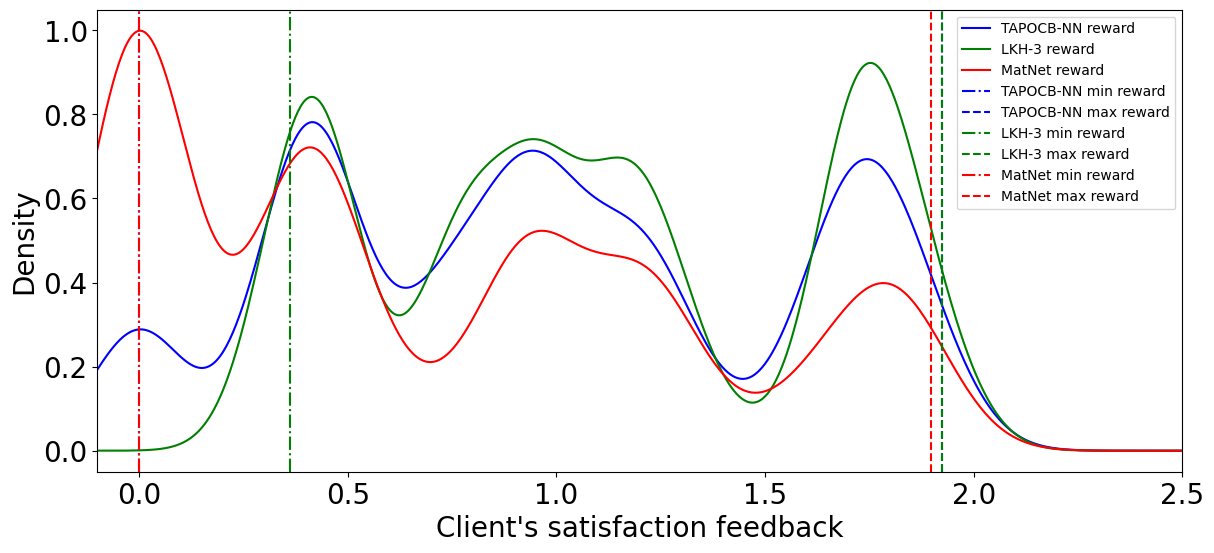

In [94]:
resulting_set_df.plot.kde(fontsize = 20, color = ['blue', 'green', 'red'], figsize = (14,6), xlim=(-0.1,2.5))
plt.xlabel("Client's satisfaction feedback")
plt.axvline(np.min(resulting_set_df['TAPOCB-NN reward']), linestyle="-.", color="blue", label="TAPOCB-NN min reward")
plt.axvline(np.max(resulting_set_df['TAPOCB-NN reward']), linestyle="--", color="blue", label="TAPOCB-NN max reward")
plt.axvline(np.min(resulting_set_df['LKH-3 reward']), linestyle="-.", color="green", label="LKH-3 min reward")
plt.axvline(np.max(resulting_set_df['LKH-3 reward']), linestyle="--", color="green", label="LKH-3 max reward")
plt.axvline(np.min(resulting_set_df['MatNet reward']), linestyle="-.", color="red", label="MatNet min reward")
plt.axvline(np.max(resulting_set_df['MatNet reward']), linestyle="--", color="red", label="MatNet max reward")
plt.legend()

In [73]:
wincount = defaultdict()

wins = {'TAPOCB-NN': 0,
        'LKH': 0,
        'MatNet': 0
       }
wins_keylist = list(wins.keys())

top_1 = {'TAPOCB-NN': 0,
        'LKH': 0,
        'MatNet': 0
       }



for i,pid in enumerate(resulting_set['polygon_id']):
    if pid not in wincount.keys():
        wincount[pid] = {'TAPOCB-NN': 0,
                         'LKH': 0,
                         'MatNet': 0,
                         'relative prefs': benchmark_validation_set[pid]['preferences'],
                         'count': 0,
                         'алярма': 0                        
                        }    
    wincount[pid]['count']+=1
    mapping = {resulting_set['TAPOCB-NN reward'][i]: 0,
               resulting_set['LKH-3 reward'][i]: 1,
               resulting_set['MatNet reward'][i]: 2
              }
    perf_list = [resulting_set['TAPOCB-NN reward'][i], resulting_set['LKH-3 reward'][i], resulting_set['MatNet reward'][i]]
    sort_perf = sorted(perf_list, reverse=True)
    original_idxs = [mapping[i] for i in sort_perf]
    for place,index in enumerate(original_idxs):
        candidate = wins_keylist[index]
        if place == 0:
            wins[candidate]+=2
            top_1[candidate]+=1
            wincount[pid][candidate]+=1
        elif place == 1:
            wins[candidate]+=1
        else:
            wins[candidate]+=0
    if resulting_set['MatNet reward'][i] == 0:
        wincount[pid]['алярма']+=1

In [74]:
wincount

defaultdict(None,
            {'ATSP_IN13': {'TAPOCB-NN': 108,
              'LKH': 351,
              'MatNet': 0,
              'relative prefs': {'alpha': np.float64(0.8252963939123505),
               'beta': np.float64(0.8716270856017212),
               'gamma': np.float64(0.7715771341525974)},
              'count': 459,
              'алярма': 438},
             'ATSP_IN1': {'TAPOCB-NN': 113,
              'LKH': 323,
              'MatNet': 0,
              'relative prefs': {'alpha': np.float64(0.9702823581956069),
               'beta': np.float64(0.01),
               'gamma': np.float64(0.01)},
              'count': 436,
              'алярма': 0},
             'ATSP_IN11': {'TAPOCB-NN': 58,
              'LKH': 157,
              'MatNet': 0,
              'relative prefs': {'alpha': np.float64(0.09311363587606114),
               'beta': np.float64(0.8079897112877479),
               'gamma': np.float64(0.99)},
              'count': 215,
              'алярма': 215},
 

In [84]:
for item,val in wincount.items():
    print(item, val)

ATSP_IN13 {'TAPOCB-NN': 108, 'LKH': 351, 'MatNet': 0, 'relative prefs': {'alpha': np.float64(0.8252963939123505), 'beta': np.float64(0.8716270856017212), 'gamma': np.float64(0.7715771341525974)}, 'count': 459, 'алярма': 438}
ATSP_IN1 {'TAPOCB-NN': 113, 'LKH': 323, 'MatNet': 0, 'relative prefs': {'alpha': np.float64(0.9702823581956069), 'beta': np.float64(0.01), 'gamma': np.float64(0.01)}, 'count': 436, 'алярма': 0}
ATSP_IN11 {'TAPOCB-NN': 58, 'LKH': 157, 'MatNet': 0, 'relative prefs': {'alpha': np.float64(0.09311363587606114), 'beta': np.float64(0.8079897112877479), 'gamma': np.float64(0.99)}, 'count': 215, 'алярма': 215}
ATSP_IN8 {'TAPOCB-NN': 54, 'LKH': 49, 'MatNet': 0, 'relative prefs': {'alpha': np.float64(0.28583608891844636), 'beta': np.float64(0.3239332247558852), 'gamma': np.float64(0.7661545927766744)}, 'count': 103, 'алярма': 0}
ATSP_IN3 {'TAPOCB-NN': 125, 'LKH': 146, 'MatNet': 0, 'relative prefs': {'alpha': np.float64(0.07347803621320997), 'beta': np.float64(0.93969898743141

In [76]:
top_1

{'TAPOCB-NN': 1056, 'LKH': 2048, 'MatNet': 141}

In [77]:
wins

{'TAPOCB-NN': 3641, 'LKH': 5040, 'MatNet': 1054}

In [78]:
descr = [pd.DataFrame(resulting_set_df['TAPOCB-NN reward']).describe(), pd.DataFrame(resulting_set['LKH-3 reward']).describe(), pd.DataFrame(resulting_set['MatNet reward']).describe()]

In [79]:
descr

[       TAPOCB-NN reward
 count       3245.000000
 mean           0.969261
 std            0.569394
 min            0.000000
 25%            0.448498
 50%            0.945650
 75%            1.573868
 max            1.924876,
                  0
 count  3245.000000
 mean      1.093583
 std       0.516549
 min       0.361093
 25%       0.714498
 50%       0.961524
 75%       1.719435
 max       1.924082,
                  0
 count  3245.000000
 mean      0.681007
 std       0.625168
 min       0.000000
 25%       0.000000
 50%       0.447502
 75%       1.171872
 max       1.898639]

In [80]:
descr_by_poly = resulting_set_df.groupby('polygon_id').describe()

In [90]:
descr_by_poly['TAPOCB-NN reward']

,count,mean,std,min,25%,50%,75%,max
polygon_id,,,,,,,,
ATSP_IN0,103.0,1.162287,0.019429,1.119525,1.170881,1.172126,1.173151,1.174806
ATSP_IN1,436.0,0.448966,0.000658,0.448242,0.448291,0.448500,0.449750,0.449769
ATSP_IN10,467.0,0.947323,0.016461,0.913667,0.944987,0.945789,0.960458,0.964044
ATSP_IN11,215.0,0.826957,0.453523,0.000000,0.906397,1.103835,1.155645,1.157886
ATSP_IN12,331.0,0.360259,0.004109,0.351615,0.361784,0.362249,0.363194,0.363400
ATSP_IN13,459.0,1.217401,0.762771,0.000000,0.000000,1.713401,1.716716,1.724698
ATSP_IN2,349.0,0.565317,0.325300,0.000000,0.685793,0.764030,0.766212,0.786308
ATSP_IN3,271.0,1.805810,0.031296,1.744942,1.806924,1.810092,1.830750,1.832330
ATSP_IN4,107.0,1.903390,0.027650,1.848711,1.899919,1.921449,1.923801,1.924876


In [55]:
import numpy as np
import random
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from typing import Dict, List, Tuple, Optional
from collections import defaultdict, deque
from scipy import stats

RANGE = 0.9
AGENT_IDS = [318, 434]
LEARNING_RATE_ACTOR = 1e-4
LEARNING_RATE_CRITIC = 1e-3
GAMMA = 0.99
TAU = 0.005
BATCH_SIZE = 64
CLIP_GRAD = 1.0

BETA_TEMPERATURE = 2.0
ENTROPY_COEF = 0.05
BETA_MAX = 20.0
ON_POLICY_BUFFER_SIZE = 128

agent_config = {318: ('marl', 'TAPOCB'),
                434: ('marl', 'non-TAPOCB')
               }
TENDER_POLYGONS = ['AUG--AUG-G-253-6-319-1']

STATIC_BR = {
    318: 0.2,
    434: 0.25
}

STATIC_V = 1 - sum(STATIC_BR.values())
U_GLOBAL = 900 

def set_seeds(seed: int = 42):
    """Set all random seeds for reproducibility."""
    import os
    import random
    import numpy as np
    import torch
    
    os.environ['PYTHONHASHSEED'] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

class TheoreticalBidDistribution:
    def __init__(self, br_1: float, br_2: float, U: float):
        self.br_i = max(br_1, br_2)
        self.br_j = min(br_1, br_2)
        self.U = U
        self.V = STATIC_V
        self.P_lower = (self.br_i * self.U) / (self.br_i + self.V)
    
    def get_theoretical_cdf(self, P: float, agent_type: str) -> float:
        if P < self.P_lower:
            return 0.0
        elif P >= self.U:
            return 1.0
        else:
            if agent_type == 'i':
                if P == self.U:
                    return (self.br_i-self.br_j)/(self.br_i+self.V)
                return (1.0 + self.br_j / self.V - 
                       self.br_i * self.U * (self.br_j + self.V) / 
                       (self.br_i + self.V) / self.V / P)
            else:
                return 1.0 - self.br_i * (self.U - P) / self.V / P
    
    def generate_theoretical_sample(self, n_samples: int = 1000, 
                                    agent_type: str = 'i') -> np.ndarray:
        u = np.random.uniform(0, 1, n_samples)
        
        if agent_type == 'j':
            # F_j(P) = 1 - br_i*(U - P) / (V * P)  =>  P = (br_i * U) / (V*(1 - u) + br_i)
            samples = (self.br_i * self.U) / (self.V * (1.0 - u) + self.br_i)
        else:
            # F_i(P) = A - B/P  =>  P = B / (A - u)
            # where A = 1 + br_j/V, B = [br_i * U * (br_j + V)] / [(br_i + V) * V]
            A = 1.0 + self.br_j / self.V
            B = (self.br_i * self.U * (self.br_j + self.V)) / ((self.br_i + self.V) * self.V)
            samples = B / (A - u)
        
        samples = np.clip(samples, self.P_lower, self.U)
        
        return samples
    
    def ks_test_convergence(self, empirical_samples, agent_type):
        xs = np.sort(empirical_samples)
        F_emp = np.arange(1, len(xs)+1) / len(xs)
        F_th = np.array([self.get_theoretical_cdf(x, agent_type) for x in xs])
    
        ks_statistic = np.max(np.abs(F_emp - F_th))
    
        n = len(xs)
        p_value = stats.kstwo.sf(ks_statistic, n)
    
        return {
            "ks_statistic": float(ks_statistic),
            "p_value": float(p_value),
            "converged": bool(p_value > 0.8),
            "sample_size": n
        }
        
class Courier:
    def __init__(self, id: int):
        self.id = id
        self.trust_score: float = 0.5
        self.br: float = STATIC_BR.get(id)

class ActorNetwork(nn.Module):
    def __init__(self, state_dim: int = 5):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(state_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 128),
            nn.ReLU()
        )
        
        self.alpha_head = nn.Linear(128, 1)
        self.beta_head = nn.Linear(128, 1)

    def forward(self, state):
        x = self.net(state)
        
        alpha = F.softplus(self.alpha_head(x)) + 1e-3
        alpha = torch.clamp(alpha, max=BETA_MAX)
        
        beta = F.softplus(self.beta_head(x)) + 1e-3
        beta = torch.clamp(beta, max=BETA_MAX)
        
        return alpha, beta

class CriticNetwork(nn.Module):
    def __init__(self, state_dim: int = 5):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(state_dim + 1, 128),
            nn.ReLU(),
            nn.Linear(128, 128),
            nn.ReLU(),
            nn.Linear(128, 1)
        )
    
    def forward(self, state: torch.Tensor, action: torch.Tensor) -> torch.Tensor:
        x = torch.cat([state, action], dim=-1)
        return self.network(x)

class DCMABAgent:
    def __init__(self, agent_id: int, state_dim: int = 5, optimizer = 'TAPOCB'):
        self.agent_id = agent_id
        self.optimizer = optimizer
        
        self.actor = ActorNetwork(state_dim)
        self.actor_target = ActorNetwork(state_dim)
        self.actor_target.load_state_dict(self.actor.state_dict())
        self.actor_optimizer = optim.Adam(self.actor.parameters(), lr=LEARNING_RATE_ACTOR)
        
        self.critic = CriticNetwork(state_dim)
        self.critic_target = CriticNetwork(state_dim)
        self.critic_target.load_state_dict(self.critic.state_dict())
        self.critic_optimizer = optim.Adam(self.critic.parameters(), lr=LEARNING_RATE_CRITIC)
        
        self.on_policy_buffer = deque(maxlen=ON_POLICY_BUFFER_SIZE)
        
        self.bid_history: List[float] = []
        self.reward_history: List[float] = []
        
        self.wins = 0
        self.total_games = 0
        self.win_rate = 0.0

        self.action_history_window = deque(maxlen=20)
        self.log_prob_history = deque(maxlen=20)
        
        self.current_br = 0.0
        
        self.reward_baseline = 0.0
        self.baseline_momentum = 0.9
    
    def sample_policy_bids(self, state, P_lower, U, n_samples=1000):
        self.actor.eval()
        
        with torch.no_grad():
            alpha, beta = self.actor(state)
            dist = torch.distributions.Beta(alpha, beta)
            
            samples = dist.sample((n_samples,))
            samples = samples.squeeze().cuda().numpy()
        
        bids = P_lower + samples * (U - P_lower)
        return bids

    def estimate_opponent_cdf(self, bid, opponent_bid_history):
        if len(opponent_bid_history) < 10:
            return 0.5
        
        opp = np.array(opponent_bid_history[-8:])
        return float(np.mean(opp <= bid))
    
    def get_state(self, my_br: float, opp_br: float, P_lower: float, U: float, opp_last_bid: float) -> torch.Tensor:
        opp_last_bid_norm = (opp_last_bid - P_lower) / (U - P_lower) if U > P_lower else 0.0
        
        state = np.array([
            P_lower / U,
            my_br,
            opp_br,
            float(my_br > opp_br),
            opp_last_bid_norm  # NEW: Opponent's last bid (Memory)
        ], dtype=np.float32)
        
        return torch.FloatTensor(state)
    
    def act(self, state: torch.Tensor, training: bool = True) -> Tuple[float, torch.Tensor, torch.Tensor]:
        alpha, beta = self.actor(state)
        
        if training:
            dist = torch.distributions.Beta(alpha / BETA_TEMPERATURE, beta / BETA_TEMPERATURE)
            action = dist.sample()
        else:
            dist = torch.distributions.Beta(alpha, beta)
            action = dist.mean
        
        log_prob = dist.log_prob(action)
        
        self.action_history_window.append(action.item())
        self.log_prob_history.append(log_prob.item())
        
        return action.item(), action, log_prob

    def compute_logistics_costs(self, polygon_id):
        GRAND_MODEL_PATH = 'courier_models/courier_35_model.pth'
        orders = AUG_global_map[polygon_id]['full map']
        ideal_matrix = AUG_global_map[polygon_id]['distance matrix']
        
        if self.optimizer == 'TAPOCB':
            start_t = time.time()
        
            pred_portfolio = run_TAPOCB_NN_inference(polygon_id, GRAND_MODEL_PATH).squeeze().numpy()
            
            algorithm = rng.choice(["MatNet", "NLNS", "lkh3", "Christofides"],
                                   p=pred_portfolio)
            
            cost_matrix = np.array(get_full_matrix_test(ideal_matrix, orders, 0, polygon_id))
        
            orders = [0]+orders
        
            test_optimizer = OptimizerInterface()
            
            if algorithm == "MatNet":
                route, route_time = test_optimizer.solve_MatNet(orders, 0, cost_matrix)
            elif algorithm == "NLNS":
                route, route_time = test_optimizer.solve_NLNS(orders, 0, cost_matrix)
            elif algorithm == "lkh3":
                route, route_time = test_optimizer.solve_lkh3(orders, 0, cost_matrix)
            else:
                route, route_time = test_optimizer.solve_Christofides(orders, 0, cost_matrix)
            
            TAPOCB_ct = time.time() - start_t
            
            return route_time, TAPOCB_ct
        
        else:
            start_t = time.time()

            cost_matrix = np.array(get_full_matrix_test(ideal_matrix, orders, 0, polygon_id))
            orders = [0]+orders
            test_optimizer = OptimizerInterface()

            route, route_time = test_optimizer.solve_MatNet(orders, 0, cost_matrix)
            response_time = time.time() - start_t

            return route_time, response_time
    
    def compute_reward(self, bid: float, br: float, U: float, opponent_bid_history: List[float],
                       won: bool, P_lower: float, tie: bool, logistics_cost: float) -> float:
        if not won:
            reward = -br
        else:
            F_opp = self.estimate_opponent_cdf(bid, opponent_bid_history)
            reward = (bid - logistics_cost) / U
            if tie:
                reward *= 0.5
        reward = max(0.0, min(reward, 1.0))    
        self.reward_history.append(reward)
        
        self.reward_baseline = (self.baseline_momentum * self.reward_baseline + 
                                (1 - self.baseline_momentum) * (reward+logistics_cost*U))
        
        return reward

    def store_experience(self, experience: Dict):
        self.on_policy_buffer.append(experience)
    
    def update_statistics(self, won: bool):
        self.total_games += 1
        if won:
            self.wins += 1
        self.win_rate = self.wins / max(self.total_games, 1)
    
    def get_bid_statistics(self, window: int = 100) -> Dict:
        if len(self.bid_history) == 0:
            return {
                'mean': 0.0,
                'std': 0.0,
                'min': 0.0,
                'max': 0.0,
                'count': 0
            }
        
        recent_bids = (self.bid_history[-window:] 
               if len(self.bid_history) > window 
               else self.bid_history)
        
        return {
            'mean': float(np.mean(recent_bids)),
            'std': float(np.std(recent_bids)),
            'min': float(np.min(recent_bids)),
            'max': float(np.max(recent_bids)),
            'count': len(recent_bids)
        }
    
    def learn(self, other_agent_frozen: bool = True) -> Tuple[float, float]:
        if len(self.on_policy_buffer) < BATCH_SIZE:
            return 0.0, 0.0
        
        batch = list(self.on_policy_buffer)[-BATCH_SIZE:]
        
        states = torch.stack([exp['state'] for exp in batch])
        actions = torch.stack([exp['action'] for exp in batch])
        rewards = torch.FloatTensor([exp['reward'] for exp in batch]).unsqueeze(1)
        next_states = torch.stack([exp['next_state'] for exp in batch])
        dones = torch.FloatTensor([exp['done'] for exp in batch]).unsqueeze(1)
        log_probs = torch.stack([exp['log_prob'] for exp in batch])
        
        with torch.no_grad():
            alpha, beta = self.actor_target(next_states)
            next_action = alpha / (alpha + beta)
            Q_target = self.critic_target(next_states, next_action)
            target_q = rewards + GAMMA * (1 - dones) * Q_target
        
        current_q = self.critic(states, actions)
        critic_loss = nn.MSELoss()(current_q, target_q)
        
        self.critic_optimizer.zero_grad()
        critic_loss.backward()
        torch.nn.utils.clip_grad_norm_(self.critic.parameters(), CLIP_GRAD)
        self.critic_optimizer.step()
        
        alpha, beta = self.actor(states)
        dist = torch.distributions.Beta(alpha / BETA_TEMPERATURE, beta / BETA_TEMPERATURE)
        new_actions = dist.rsample()
        new_log_probs = dist.log_prob(new_actions)
        
        with torch.no_grad():
            q_values = self.critic(states, new_actions)
            
            q_values = (q_values - q_values.mean()) / (q_values.std() + 1e-6)
            
            advantage = q_values - self.reward_baseline
        
        actor_loss = -(new_log_probs * advantage).mean()
        
        entropy = dist.entropy().mean()
        actor_loss = actor_loss - ENTROPY_COEF * entropy
        
        self.actor_optimizer.zero_grad()
        actor_loss.backward()
        torch.nn.utils.clip_grad_norm_(self.actor.parameters(), CLIP_GRAD)
        self.actor_optimizer.step()
        
        for target_param, param in zip(self.actor_target.parameters(), self.actor.parameters()):
            target_param.data.copy_(TAU * param.data + (1 - TAU) * target_param.data)
        
        for target_param, param in zip(self.critic_target.parameters(), self.critic.parameters()):
            target_param.data.copy_(TAU * param.data + (1 - TAU) * target_param.data)
        
        return critic_loss.item(), actor_loss.item()

class StaticBidder:
    """
    Static Bidder: Bids a fixed price regardless of the game state or training.
    """
    def __init__(self, agent_id, fixed_price):
        self.agent_id = agent_id
        self.fixed_price = fixed_price
        self.bid_history = []
        self.reward_history = []
        self.wins = 0
        self.total_games = 0
        self.win_rate = 0.0
        self.current_br = 0.0
        self.state_dim = 4
        self.action_history_window = deque(maxlen=20)
        
        # Compatibility placeholders for DCMABSystem
        self.actor = None
        self.actor_target = None
        self.opponent_model = None
        self.memory = deque(maxlen=10000)
        self.current_br_ratio = 0
        self.is_better_agent = False
        self.reward_baseline = 0.2*U_GLOBAL

    def get_state(self, my_br, opp_br, P_lower, U) -> torch.Tensor:
        # Return dummy tensor to prevent .detach().cuda() crashes
        return torch.zeros(self.state_dim, dtype=torch.float32)
    
    def act(self, state: torch.Tensor, training: bool = True) -> Tuple[float, torch.Tensor, torch.Tensor]:
        action_val = 0.5
        return action_val, torch.tensor([action_val]), torch.tensor(0.0)

    def compute_reward(self, my_bid, my_br, U, opp_bids, won, P_lower, tie) -> float:
        if won:
            return max(0.0, min(1.0, (my_bid - P_lower) / (U - P_lower + 1e-8)))
        return my_br

    def store_experience(self, experience):
        pass # Static agent does not learn

    def update_statistics(self, won):
        self.total_games += 1
        if won:
            self.wins += 1
        self.win_rate = self.wins / max(self.total_games, 1)

    def learn(self) -> Tuple[float, float]:
        return 0.0, 0.0

    def sample_policy_bids(self, state, P_lower, U, n_samples=100):
        return np.ones(n_samples)*self.fixed_price
        
    def get_bid_statistics(self, window=100):
        if len(self.bid_history) == 0:
            return {'mean': 0.0, 'std': 0.0, 'min': 0.0, 'max': 0.0, 'count': 0}
        recent = self.bid_history[-window:] if len(self.bid_history) > window else self.bid_history
        return {
            'mean': float(np.mean(recent)), 'std': float(np.std(recent)),
            'min': float(np.min(recent)), 'max': float(np.max(recent)), 'count': len(recent)
        }


class HeuristicBidder:
    """
    Heuristic Bidder: Starts with Uniform distribution, adapts based on rewards 
    without rational game-theory logic (simple reinforcement update).
    """
    def __init__(self, agent_id, P_lower_init, U_init, lr=0.05):
        self.agent_id = agent_id
        self.lr = lr
        self.P_lower_init = P_lower_init
        self.U_init = U_init
        self.bid_history = []
        self.reward_history = []
        self.wins = 0
        self.total_games = 0
        self.win_rate = 0.0
        self.current_br = 0.0
        self.state_dim = 4
        self.action_history_window = deque(maxlen=20)
        self.memory = deque(maxlen=10000)
        self.actions = np.linspace(P_lower_init, U_init, 101)
        self.policy = np.ones(len(self.actions)) / len(self.actions)
        
        # Compatibility placeholders
        self.actor = None
        self.actor_target = None
        self.opponent_model = None
        self.current_br_ratio = 0
        self.is_better_agent = False
        self.reward_baseline = 0

    def get_state(self, my_br, opp_br, P_lower, U) -> torch.Tensor:
        return torch.zeros(self.state_dim, dtype=torch.float32)

    def act(self, state, training=True):
        chosen_idx = np.random.choice(len(self.actions), p=self.policy)
        raw_bid = self.actions[chosen_idx]

        bid = float(np.clip(raw_bid, self.P_lower_init, self.U_init))

        action_val = 0.5 if self.U_init == self.P_lower_init else (bid - self.P_lower_init) / (self.U_init - self.P_lower_init)
        
        prob = self.policy[chosen_idx]
        log_prob = np.log(prob + 1e-9)
        
        self.bid_history.append(bid)
        
        # Return format matching DCMABAgent
        return action_val, torch.tensor([action_val]), torch.tensor([log_prob])

    def update_policy(self, reward, P_lower, U, opp_bids):

            if len(opp_bids) < 8:
                return

            ma_est = np.mean(opp_bids[-8:])
            
            idx = np.searchsorted(self.actions, ma_est, side='left')
            
            if idx > 0:
                target_idx = idx - 1
            else:
                target_idx = 0
            
            N = len(self.policy)
            if N > 1:
                denom = self.lr / (N - 1)
                
                self.policy -= denom
                
                self.policy[target_idx] += (self.lr + denom)
            
            self.policy = np.clip(self.policy, 0.0, 1.0)
            
            self.policy /= self.policy.sum()

    def compute_reward(self, my_bid, my_br, U, opp_bids, won, P_lower, tie):
        if won:
            return max(0.0, min(1.0, (my_bid - P_lower) / (U - P_lower + 1e-8)))
        return my_br

    def store_experience(self, experience): pass

    def update_statistics(self, won):
        self.total_games += 1
        if won:
            self.wins += 1
        self.win_rate = self.wins / max(self.total_games, 1)
        
    def get_bid_statistics(self, window=100):
        if len(self.bid_history) == 0:
            return {'mean': 0.0, 'std': 0.0, 'min': 0.0, 'max': 0.0, 'count': 0}
        recent = self.bid_history[-window:] if len(self.bid_history) > window else self.bid_history
        return {
            'mean': float(np.mean(recent)), 'std': float(np.std(recent)),
            'min': float(np.min(recent)), 'max': float(np.max(recent)), 'count': len(recent)
        }

    def learn(self) -> Tuple[float, float]: return 0.0, 0.0

    def sample_policy_bids(self, state, P_lower, U, n_samples=1000):
        return np.random.choice(self.actions, size = n_samples, p = self.policy)

class DCMABSystem:
    def __init__(self):
        self.agents = {}
        # agent_config = {318: 'marl', 434: 'heuristic', 999: 'static_0.7'}
        for aid, cfg in agent_config.items():
            if cfg[0] == 'marl':
                if cfg[1] == 'TAPOCB':
                    self.agents[aid] = DCMABAgent(aid, optimizer = 'TAPOCB')
                else:
                    self.agents[aid] = DCMABAgent(aid, optimizer = 'common')
            elif cfg[0] == 'heuristic':
                self.agents[aid] = HeuristicBidder(aid, P_lower_init=450, U_init=900, lr=0.05)
            elif cfg[0].startswith('static_'):
                fixed_price = float(cfg.split('_')[1])
                self.agents[aid] = StaticBidder(aid, fixed_price)
        
        self.current_br_ratio = 0
        self.theoretical_distributions: Dict[str, TheoreticalBidDistribution] = {}
        
        self.tender_history: List[Dict] = []
        self.current_epoch = 0
        
        self.update_counter = 0
        
    def determine_better_agent(self, br1: float, br2: float, id1: int, id2: int) -> Tuple[int, int]:
        if br1 >= br2:
            return id1, id2
        else:
            return id2, id1
    
    def get_theoretical_distribution(self, br_i: float, br_j: float, 
                                     U: float) -> TheoreticalBidDistribution:
        key = f"{br_i:.4f}_{br_j:.4f}_{U:.2f}"
        
        if key not in self.theoretical_distributions:
            self.theoretical_distributions[key] = TheoreticalBidDistribution(br_i, br_j, U)
        
        return self.theoretical_distributions[key]

    def eval_client_reward_experimental(self, price, route_time, CT, polygon_config):
        U = U_GLOBAL
        CT_SA = polygon_config['comp_time_limit']
        client_tw = polygon_config['time_window']
        client_prefs = polygon_config['client_prefs']
        delta_tw = client_tw - route_time
        delta_CT = CT_SA - CT
                
        client_score = 0 if delta_tw < 0 or CT > CT_SA else (
            client_prefs['alpha'] * (U - price)/U +
            client_prefs['beta'] * delta_tw/(client_tw) +
            client_prefs['gamma'] * delta_CT/CT_SA
        )
        return client_score
    
    def simulate_tender(self, courier1: Courier, courier2: Courier, polygon_config, training: bool = True) -> Dict:
        br1 = courier1.br
        br2 = courier2.br

        polygon_id = polygon_config['polygon_id']

        self.agents[courier1.id].current_br = br1
        self.agents[courier2.id].current_br = br2
        
        better_id, worse_id = self.determine_better_agent(br1, br2, courier1.id, courier2.id)
        
        U = U_GLOBAL
        
        theoretical_dist = self.get_theoretical_distribution(
            max(br1, br2),
            min(br1, br2),
            U
        )
        
        P_lower = theoretical_dist.P_lower
        
        agent1 = self.agents[courier1.id]
        agent2 = self.agents[courier2.id]

        opp_last_bid1 = agent2.bid_history[-1] if agent2.bid_history else P_lower
        opp_last_bid2 = agent1.bid_history[-1] if agent1.bid_history else P_lower
        
        state1 = agent1.get_state(br1, br2, P_lower, U, opp_last_bid1)
        state2 = agent2.get_state(br2, br1, P_lower, U, opp_last_bid2)
        
        action1, action1_tensor, log_prob1 = agent1.act(state1, training)
        action2, action2_tensor, log_prob2 = agent2.act(state2, training)

        TW1, CT1 = agent1.compute_logistics_costs(polygon_id)
        TW2, CT2 = agent2.compute_logistics_costs(polygon_id)

        logistics_cost1 = TW1*0.01
        logistics_cost2 = TW2*0.01
            
        bid1 = P_lower + action1 * (U - P_lower) + logistics_cost1
        bid2 = P_lower + action2 * (U - P_lower) + logistics_cost2

        print(polygon_config)

        client_feedback1 = self.eval_client_reward_experimental(bid1,TW1,CT1,polygon_config)
        
        client_feedback2 = self.eval_client_reward_experimental(bid2,
                                                           TW2,
                                                           CT2,
                                                           polygon_config)

        CF = [client_feedback1, client_feedback2]
        
        agent1.bid_history.append(bid1)
        agent2.bid_history.append(bid2)

        tie = abs(client_feedback1 - client_feedback2) < 1e-5
        
        if tie:
            if courier1.trust_score > courier2.trust_score:
                winner_id = courier1.id
                both_win = False
            elif courier2.trust_score > courier1.trust_score:
                winner_id = courier2.id
                both_win = False
            else:
                winner_id = None
                both_win = True
        elif client_feedback1 > client_feedback2:
            winner_id = courier1.id
            both_win = False
        else:
            winner_id = courier2.id
            both_win = False

        won1 = (winner_id == courier1.id) or both_win
        won2 = (winner_id == courier2.id) or both_win

        reward1 = agent1.compute_reward(bid1, br1, U, agent2.bid_history, won1, P_lower, tie, logistics_cost1)
        reward2 = agent2.compute_reward(bid2, br2, U, agent1.bid_history, won2, P_lower, tie, logistics_cost2)

        if isinstance(agent1, HeuristicBidder):
            agent1.update_policy(reward1, P_lower, U, agent2.bid_history)
        if isinstance(agent2, HeuristicBidder):
            agent2.update_policy(reward2, P_lower, U, agent1.bid_history)
        
        next_state1 = agent1.get_state(br1, br2, P_lower, U, opp_last_bid1)
        next_state2 = agent2.get_state(br2, br1, P_lower, U, opp_last_bid2)
        
        exp1 = {
            'state': state1.detach().cuda(),
            'action': action1_tensor.detach().cuda(),
            'reward': reward1,
            'next_state': next_state1.detach().cuda(),
            'done': False,
            'log_prob': log_prob1.detach().cuda()
        }
        
        exp2 = {
            'state': state2.detach().cuda(),
            'action': action2_tensor.detach().cuda(),
            'reward': reward2,
            'next_state': next_state2.detach().cuda(),
            'done': False,
            'log_prob': log_prob2.detach().cuda()
        }
        
        if training:
            agent1.store_experience(exp1)
            agent2.store_experience(exp2)
        
        agent1.update_statistics(won1)
        agent2.update_statistics(won2)
        
        agent1_is_better = (br1 >= br2)
        agent2_is_better = (br2 >= br1)
        
        result = {
            'epoch': self.current_epoch,
            'courier1_id': courier1.id,
            'courier2_id': courier2.id,
            'bid1': float(bid1),
            'bid2': float(bid2),
            'action1': float(action1),
            'action2': float(action2),
            'winner': winner_id,
            'tie': tie,
            'reward1': float(reward1),
            'reward2': float(reward2),
            'U': float(U),
            'P_lower': float(P_lower),
            'br_i': float(max(br1, br2)),
            'br_j': float(min(br1, br2)),
            'agent1_better': agent1_is_better,
            'agent2_better': agent2_is_better,
            'winning_bid': float(bid1 if winner_id == courier1.id else bid2),
            'client_welfare': max(CF)
        }
        
        self.tender_history.append(result)
        
        return result

    def learn(self) -> Tuple[float, float]:
        total_critic_loss = 0.0
        total_actor_loss = 0.0
        
        self.update_counter += 1
        
        if self.update_counter % 2 == 1:
            agent = self.agents[AGENT_IDS[0]]
            critic_loss, actor_loss = agent.learn()
            total_critic_loss += critic_loss
            total_actor_loss += actor_loss
        else:
            agent = self.agents[AGENT_IDS[1]]
            critic_loss, actor_loss = agent.learn()
            total_critic_loss += critic_loss
            total_actor_loss += actor_loss
        
        return total_critic_loss, total_actor_loss
        
    def get_statistics(self) -> Dict:
        stats = {
            'epoch': self.current_epoch,
            'total_tenders': len(self.tender_history),
            'win_rates': {},
            'agent_stats': {},
            'recent_tender': self.tender_history[-1] if self.tender_history else None
        }
        
        for agent_id, agent in self.agents.items():
            stats['win_rates'][agent_id] = agent.win_rate
            
            is_better = False
            if self.tender_history:
                last = self.tender_history[-1]
                if last['courier1_id'] == agent_id:
                    is_better = last['agent1_better']
                else:
                    is_better = last['agent2_better']
                    
            stats['agent_stats'][agent_id] = {
                'total_games': agent.total_games,
                'wins': agent.wins,
                'win_rate': agent.win_rate,
                'is_better': is_better,
                'bid_stats': agent.get_bid_statistics(),
                'reward_baseline': agent.reward_baseline
            }
        
        return stats
    
    def start_new_epoch(self):
        self.current_epoch += 1
        print(f"Начало эпохи {self.current_epoch}")

class RoutingSystem:
    def __init__(self, dcmab_system: DCMABSystem,
                 k: float = 10800.0,
                 CT_upper: float = 2):
        
        self.dcmab = dcmab_system
        self.k = k
        self.CT_upper = CT_upper
        
        self.couriers: Dict[int, Courier] = {}        
        self.tender_count = 0

        self.total_critic_loss = []
        self.total_actor_loss = []
        self.avg_actor_losses = []
    
    def initialize_couriers(self, courier_ids: List[int]):
        for courier_id in courier_ids:
            self.couriers[courier_id] = Courier(courier_id)
    
    def simulate_working_day(self, total_seconds: float = 43200,
                           training: bool = True,
                           max_tenders: int = 100):
        
        print(f"Начало симуляции рабочего дня (Эпоха {self.dcmab.current_epoch})")
        
        self.tender_count = 0

        actor_losses = []
              
        while self.tender_count < max_tenders:
            self._conduct_tender(training)
            self.tender_count += 1
            _, actor_loss = self.dcmab.learn()
            actor_losses.append(actor_loss)
            
            if training and self.tender_count % 16 == 0:
                critic_loss, actor_loss = self.dcmab.learn()
                self.avg_actor_losses.append(np.mean(actor_losses))
                actor_losses = []
                if critic_loss > 0:
                    self.total_critic_loss.append(critic_loss)
                    self.total_actor_loss.append(actor_loss)
                    print(f"Обучение после {self.tender_count} тендеров: "
                          f"critic_loss={critic_loss:.4f}, actor_loss={actor_loss:.4f}")
        
        print(f"Симуляция завершена. Проведено тендеров: {self.tender_count}")
        
        stats = self.dcmab.get_statistics()
        self._log_statistics(stats)
        
        self.dcmab.start_new_epoch()
        
        return stats
    
    def _conduct_tender(self, training: bool):
        courier1_id, courier2_id = AGENT_IDS
        courier1 = self.couriers[courier1_id]
        courier2 = self.couriers[courier2_id]

        polygon_id = random.choice(list(TENDER_POLYGONS))
        client_prefs = generate_polygon_config(polygon_id, AUG_global_map, n_clusters=8)
    
        polygon_config = {'polygon_id': polygon_id,
                          'time_window': self.k,
                          'comp_time_limit': self.CT_upper,
                          'client_prefs': client_prefs
                         }
    
        result = self.dcmab.simulate_tender(courier1, courier2, polygon_config, training)
        
        return result
    
    def _log_statistics(self, stats: Dict):
        print(f"\nОбщая статистика:")
        print(f"  Всего тендеров: {stats['total_tenders']}")
        
        print(f"\nСтатистика агентов:")
        for agent_id, agent_stats in stats['agent_stats'].items():
            print(f"  Агент {agent_id} (br={STATIC_BR[agent_id]}):")
            print(f"    Игр: {agent_stats['total_games']}, "
                  f"Побед: {agent_stats['wins']} ({agent_stats['win_rate']:.1%})")
            print(f"    Лучший: {agent_stats['is_better']}, "
                  f"Baseline: {agent_stats['reward_baseline']:.3f}")
            
            bid_stats = agent_stats['bid_stats']
            if bid_stats['count'] > 0:
                print(f"    Ставки (последние {bid_stats['count']}): "
                      f"mean={bid_stats['mean']:.2f}, std={bid_stats['std']:.2f}")
        
def run_dcmab_training(num_epochs: int = 50, tenders_per_epoch: int = 1):
    print(f"Агенты: {AGENT_IDS}")
    print(f"Эпох: {num_epochs}, Тендеров на эпоху: {tenders_per_epoch}")
    print(f"Статичные br: {STATIC_BR}")
    print(f"Статичное V: {STATIC_V}")
    print(f"Глобальное U: {U_GLOBAL}")
    print(f"Энтропия: {ENTROPY_COEF}")
    print(f"Beta max ограничение: {BETA_MAX}")
    print(f"On-policy buffer size: {ON_POLICY_BUFFER_SIZE}")

    best_actor_loss = float('inf')
    patience_counter = 0
    PATIENCE_LIMIT = 100  # Wait for 100 recorded loss values (approx 1600 tenders)
    loss_history = [] # To store the losses saved every 16 tenders
    
    print("Starting training with Early Stopping enabled.")
    
    dcmab_system = DCMABSystem()
    routing_system = RoutingSystem(dcmab_system, k=10800.0)
    routing_system.initialize_couriers(AGENT_IDS)
    
    convergence_history = []
    
    for epoch in range(num_epochs):
        print(f"ЭПОХА {epoch + 1}/{num_epochs}")

        
        stats = routing_system.simulate_working_day(
            total_seconds=43200,
            training=True,
            max_tenders=tenders_per_epoch
        )

        current_loss = routing_system.avg_actor_losses[-1]
        loss_history.append(current_loss)
        if len(loss_history) >= PATIENCE_LIMIT:
            # Calculate moving average of the recent window
            recent_window = loss_history[-PATIENCE_LIMIT:]
            avg_recent_loss = sum(recent_window) / len(recent_window)
            
            # Check if we found a new minimum
            if np.abs(avg_recent_loss) < np.abs(best_actor_loss):
                best_actor_loss = avg_recent_loss
                patience_counter = 0
                print(f"New best loss found: {best_actor_loss:.4f}. Resetting patience.")
            else:
                patience_counter += int(tenders_per_epoch/16)
                print(f"Loss stagnation. Patience: {patience_counter}/{PATIENCE_LIMIT}")
            
            # Trigger Stop
            if patience_counter >= PATIENCE_LIMIT:
                print(f"EARLY STOPPING TRIGGERED. Best loss {best_actor_loss:.4f} did not improve for {PATIENCE_LIMIT} steps.")
                break # Break the epoch loop
            
    final_stats = dcmab_system.get_statistics()
    
    print(f"\nФинальная статистика:")
    print(f"  Всего эпох: {final_stats['epoch']}")
    print(f"  Всего тендеров: {final_stats['total_tenders']}")
    
    print(f"\nФинальные коэффициенты победы:")
    for agent_id, agent_stats in final_stats['agent_stats'].items():
        print(f"  Агент {agent_id} (br={STATIC_BR[agent_id]}): {agent_stats['win_rate']:.1%}")
    
    return dcmab_system, routing_system.total_critic_loss, routing_system.total_actor_loss
'''
SEED = 42
set_seeds(SEED)
print(f"Random seeds set: {SEED}")

dcmab_system = DCMABSystem()

trained_dcmab, critic_loss, actor_loss = run_dcmab_training(
    num_epochs=100,
    tenders_per_epoch=128
)
'''

'\nSEED = 42\nset_seeds(SEED)\nprint(f"Random seeds set: {SEED}")\n\ndcmab_system = DCMABSystem()\n\ntrained_dcmab, critic_loss, actor_loss = run_dcmab_training(\n    num_epochs=100,\n    tenders_per_epoch=128\n)\n'

In [89]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats, interpolate
import os

welfare318 = []
welfare434 = []

def plot_combined_cdf_distributions(dcmab_system):
    output_dir = "agent_distributions"
    if not os.path.exists(output_dir):
        os.makedirs(output_dir)
    
    if not dcmab_system.tender_history:
        return
    
    N_EPOCHS = 100
    recent_tenders = dcmab_system.tender_history[-N_EPOCHS:] if len(dcmab_system.tender_history) >= N_EPOCHS else dcmab_system.tender_history
    
    if len(recent_tenders) == 0:
        return
    
    U = U_GLOBAL    
    MARL_profit = []
    static_profit = []
    avg_welfare = []
    for item in recent_tenders:
        avg_welfare.append(item['client_welfare'])
        if item['winner']== 318:
             MARL_profit.append(item['reward1']*U)
             welfare318.append(item['client_welfare'])
        else:
            static_profit.append(item['reward2']*U)
            welfare434.append(item['client_welfare'])
    MARL_avg_profit = np.sum(MARL_profit)/len(recent_tenders)
    static_avg_profit = np.sum(static_profit)/len(recent_tenders)
    W_c = np.mean(avg_welfare)

    sorted_agents_by_br = sorted(AGENT_IDS, key=lambda x: STATIC_BR[x], reverse=True)
    agent_i_id = sorted_agents_by_br[0]
    agent_j_id = sorted_agents_by_br[1]
    
    br_i = STATIC_BR[agent_i_id]
    br_j = STATIC_BR[agent_j_id]
    U = U_GLOBAL

    V = 1.0 - (br_i + br_j)
    P_lower = (br_i * U) / (br_i + V)
    
    agent_bids = {}
    agent_types_history = {agent_id: [] for agent_id in dcmab_system.agents.keys()}
    dcmab_system.agents.items()
    
    for agent_id, agent in dcmab_system.agents.items():
        if agent_id == agent_i_id:
            agent_type = 'i'
            current_br = br_i
            opponent_br = br_j
            opp_last_bid = dcmab_system.agents[agent_j_id].bid_history[-1] if dcmab_system.agents[agent_j_id].bid_history else P_lower
        else:
            agent_type = 'j'
            current_br = br_j
            opponent_br = br_i
            opp_last_bid = dcmab_system.agents[agent_i_id].bid_history[-1] if dcmab_system.agents[agent_i_id].bid_history else P_lower
               
        state = agent.get_state(current_br, opponent_br, P_lower, U, opp_last_bid)
        print(f'list of parameters is {state, P_lower, U, N_EPOCHS}')
        sampled_bids = agent.sample_policy_bids(state, P_lower, U, N_EPOCHS)
        agent_bids[agent_id] = sampled_bids
        
        for tender in recent_tenders:
            is_agent_i = False
            if tender['courier1_id'] == agent_id:
                is_agent_i = (tender['br_i'] == br_i)
            elif tender['courier2_id'] == agent_id:
                is_agent_i = (tender['br_i'] == br_i)
            agent_types_history[agent_id].append('i' if is_agent_i else 'j')
    
    class TheoreticalDist:
        def __init__(self, br_i, br_j, U):
            V = 1.0 - (br_i + br_j)
            self.P_lower = (br_i * U) / (br_i + V)
    
    avg_theoretical_dist = TheoreticalDist(br_i, br_j, U)
    
    def theoretical_cdf(P, br_i, br_j, U, agent_type):
        V = 1.0 - (br_i + br_j)
        P_lower = (br_i * U) / (br_i + V)
        
        if P < P_lower:
            return 0.0
        elif P > U:
            return 1.0
        else:
            if agent_type == 'i':
                return (1.0 + br_j / V - 
                       br_i * U * (br_j + V) / 
                       (br_i + V) / V / P)
            else:
                return 1.0 - br_i * (U - P) / V / P
    
    fig, ax = plt.subplots(1, 1, figsize=(15, 9))
    
    colors = ['blue', 'red']
    
    last_tender = recent_tenders[-1] if recent_tenders else None
    
    if last_tender:
        P_winner = last_tender['winning_bid']
        if last_tender['winner'] == 318:
            W_w = last_tender['reward1']
        else:
            W_w = last_tender['reward2']
    
    for idx, (agent_id, bids) in enumerate(agent_bids.items()):
        if len(bids) < 5:
            continue
        
        type_history = agent_types_history[agent_id]
        if not type_history:
            continue
        
        agent_type = 'i' if agent_id == agent_i_id else 'j'
        
        sorted_empirical = np.sort(bids)
        empirical_cdf = np.arange(1, len(sorted_empirical) + 1) / len(sorted_empirical)
        
        x_emp_extended = np.concatenate([[P_lower], sorted_empirical, [U, U * 1.02]])
        y_emp_extended = np.concatenate([[0], empirical_cdf, [1, 1]])
        
        f_emp = interpolate.interp1d(x_emp_extended, y_emp_extended, 
                                     kind='linear', bounds_error=False,
                                     fill_value=(0, 1))
        
        cdf_x_range = np.linspace(0, U, 500)
        empirical_cdf_interp = f_emp(cdf_x_range)
        
        sorted_empirical_with_U = np.concatenate([[P_lower], sorted_empirical, [U]])
        empirical_cdf_with_U = np.concatenate([[0], empirical_cdf, [1]])
        
        theo_x_range = np.linspace(P_lower, U, 500)
        theoretical_cdf_smooth = [theoretical_cdf(x, br_i, br_j, U, agent_type) 
                                 for x in theo_x_range]
        
        ax.step(sorted_empirical_with_U, empirical_cdf_with_U, where='post', 
                color=colors[idx], linewidth=3.5,
                label=f'Agent {agent_id} ({agent_type.upper()})\nEmpirical CDF')

    ax.axvline(x=P_lower, color='orange', linestyle='--',
               linewidth=3.5, alpha=0.9, label=f'P$^{{lower}}$ = {P_lower:.3f}')
    ax.axvline(x=U, color='green', linestyle='--',
               linewidth=3.5, alpha=0.9, label=f'U = {U:.3f}')
    
    ax.set_xlabel('Bid Value', fontsize=26, fontweight='bold')
    ax.set_ylabel('CDF', fontsize=26, fontweight='bold')
    
    ax.set_xticks([250, 400, 700, 1000])
    ax.tick_params(axis='both', which='major', labelsize=24)
    ax.tick_params(axis='both', which='minor', labelsize=24)
    
    ax.set_xlim(0, 1000)
    ax.set_ylim(-0.02, 1.02)
    
    ax.set_title('TAPOCB-NN agents empirical bids CDFs in smart contracts\n' +
                f'Agent i (BR={br_i}) vs Agent j (BR={br_j})', 
                 fontsize=26, fontweight='bold', pad=30)
    
    ax.grid(True, alpha=0.9, linestyle='--')
    
    info_text = f"Tender results\n"
    info_text += f"Last iteration: n = 2000\n"
    info_text += f"Citizen's welfare: {W_c:.3f}\n"
    info_text += f"Winner's profit: {W_w*900:.3f}\n"
    info_text += f"BR_i = {br_i}, BR_j = {br_j}\n"
    info_text += f"P_lower = {P_lower:.3f}, U = {U}\n"
    info_text += f"avg. ID 318 agent profit = {MARL_avg_profit:.2f}\n"
    info_text += f"avg. ID 434 agent profit = {static_avg_profit:.2f}"
    
    props = dict(boxstyle='round', facecolor='lightyellow', alpha=0.95,
                edgecolor='goldenrod', linewidth=3)
    
    from matplotlib.lines import Line2D
    
    legend_elements = []
    
    for idx, agent_id in enumerate(agent_bids.keys()):
        if idx < 2:
            agent_type = 'i' if agent_id == agent_i_id else 'j'
            legend_elements.append(Line2D([0], [0], color=colors[idx], lw=3.5, 
                                          label=f'Agent {agent_id} ({agent_type.upper()})\nEmpirical CDF'))
    
    legend_agents = ax.legend(handles=legend_elements[:4], loc='lower center',
                            bbox_to_anchor=(0.18, -0.6), ncol=4, fontsize=18,
                            framealpha=0.95, frameon=True, edgecolor='black',
                            title="Experimental CDF of TAPOCB-NN based Agents",
                            title_fontsize=20)
    ax.add_artist(legend_agents)

    u_line = Line2D([0], [0], color='green', lw=3.5, linestyle='--', 
                    label=f'U = {U:.3f}')
    
    legend_citizen = ax.legend(handles=[u_line], loc='lower center',
                             bbox_to_anchor=(0.0555, -1), ncol=1, fontsize=18,
                             framealpha=0.95, frameon=True, edgecolor='black',
                             title="Citizen's preferences",
                             title_fontsize=20)
    ax.add_artist(legend_citizen)

    time_line = Line2D([0], [0], color='orange', lw=3.5, linestyle='--', 
                       label=f'P$^{{lower}}$ = {P_lower:.3f}')
    
    legend_time = ax.legend(handles=[time_line], loc='lower left',
                         bbox_to_anchor=(0.19, -1.0), ncol=1, fontsize=18,
                         framealpha=0.95, frameon=True, edgecolor='black',
                         title=f"Time Window\n$f_{{\\, N}}^{{\\, U}}$ = {P_winner-W_w*900:.2f}",
                         title_fontsize=20)

    ax.text(0.75, -0.25, info_text, transform=ax.transAxes, fontsize=18,
            verticalalignment='top', horizontalalignment='center',
            bbox=props)
    
    plt.tight_layout()
    plt.subplots_adjust(bottom=0.5)
    
    filename = os.path.join(output_dir, 'combined_cdf_distributions.png')
    plt.savefig(filename, dpi=150, bbox_inches='tight')
    plt.close(fig)
    
    print(f"Saved to {filename}")
    return filename
'''
plot_combined_cdf_distributions(trained_dcmab)
'''

'\nplot_combined_cdf_distributions(trained_dcmab)\n'